# GCS urban morphological indicators
## Existing, V1 and V2

Updated workflow using the urban-factors boundary, mean roof height, a universal 50 x 50 m analysis grid and 25 x 25 m finer support. Run all cells in order after restarting the kernel. Existing input paths and timestamped output conventions are retained.

### Output conventions
- CSV tables: `GCS_FA_Tables / urban_factors_<timestamp> / <scenario>`.
- PNG plots: `GCS_FA_Plots / urban_factors_<timestamp> / <scenario>`.
- Cesium: `GCS_FA_Cesium / cesium_export_<timestamp>`, with imagery, vectors, numeric grids, legends and manifest.
- No zoomed-in map panels. All maps use the complete UF research extent.

### Important distinctions
- Analysis cells are complete 50 m squares. Presentation polygons are clipped to the research boundary, without changing the density denominator.
- H/W is a directional open-space enclosure screening proxy, not a surveyed street-width model. The 25 m polygons have building footprints removed. Without a street mask, courtyards, parks and water are also included.
- The 50 m H/W class is the dominant class by valid open-space area. Ties select the more enclosed class. Its continuous H/W value is an area-weighted mean, not the class majority.
- SVF receptors are fixed 25 m fine-cell representative points. The displayed 50 m polygons show area-weighted means of supported fine cells. Samples inside buildings are excluded and unsupported cells remain No data on SVF maps.
- Factor 5 follows the original notebook risk formula. Factor 6 adds age vulnerability separately. Neither is a measured temperature, thermal-comfort index or airflow simulation.
- Spatial input files on the local H: drive are not embedded. Mean-height fallback, coverage checks and data-quality warnings run locally.

### Local environment
Use the same environment as the original working notebook: Python, NumPy, pandas, GeoPandas, Shapely 2, rasterio, matplotlib and IPython. The file paths point to your existing H: project folders. The notebook does not install packages, download inputs or modify source datasets.


## 0.1 General imports

In [1]:
# 0.1 - General imports
import re
import math
import warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import box
import rasterio
from rasterio.features import rasterize
from rasterio.transform import from_origin
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import Normalize, TwoSlopeNorm, ListedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'savefig.transparent': False,
    'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 9,
})
print('Imports ready. Next: 0.2 - Settings.')


Imports ready. Next: 0.2 - Settings.


## 0.2 Settings and version registry

Paths are retained from the working notebook except for the requested UF boundary and building replacements and the new site and CBS inputs. V1 and V2 retain their existing paths and uniform `height_m` attributes. The analysis grid is 50 m and finer layers are 25 m. Population allocation is fixed to the existing baseline to isolate morphological scenario changes.

If verified arithmetic mean roof attributes are absent, the positive nDSM mean is calculated per footprint. Percentile and maximum roofs are never substituted for mean roof height. Complete-footprint population coverage must be confirmed before treating allocated counts as final.


In [25]:
# 0.2 - SETTINGS: edit paths / add V3 or V4 ONLY HERE.
PROJECT_DIR = Path(r'H:\GCS Final Project')
DATA_DIR = PROJECT_DIR / 'GCS_FA_QGIS'
TABLE_DIR = PROJECT_DIR / 'GCS_FA_Tables'
PLOT_DIR = PROJECT_DIR / 'GCS_FA_Plots'

STUDY_AREA_FILE = DATA_DIR / 'GCS_FA_Boundary_UF.gpkg'

boundary_layers = gpd.list_layers(STUDY_AREA_FILE)
display(boundary_layers)

polygon_layers = boundary_layers.loc[
    boundary_layers['geometry_type']
    .fillna('')
    .str.contains('Polygon', case=False),
    'name'
].tolist()

if len(polygon_layers) == 1:
    STUDY_AREA_LAYER = polygon_layers[0]
elif not polygon_layers:
    raise ValueError(
        f'No polygon layer found in {STUDY_AREA_FILE}.\n'
        f'Available layers:\n{boundary_layers.to_string(index=False)}'
    )
else:
    raise ValueError(
        'More than one polygon layer exists in the boundary GeoPackage. '
        'Set STUDY_AREA_LAYER explicitly to the research-boundary layer.\n'
        f'Polygon layers: {polygon_layers}'
    )

print('Selected research-boundary layer:', STUDY_AREA_LAYER)
CONTEXT_BUILDINGS_FILE = DATA_DIR / 'GCS_FA_UF_Building_H.gpkg'
CONTEXT_BUILDINGS_LAYER = 'GCS_FA_UF_Building_H'
DSM_FILE = DATA_DIR / 'GCS_FP_DSM_RA_Clipped.tif'     # optional grid metadata only
DTM_FILE = DATA_DIR / 'GCS_FP_DTM_RA_Clipped.tif'     # optional receptor ground elevations
NDSM_FILE = DATA_DIR / 'GCS_FP_DSM-DTM_RA.tif'        # documented, not used for future heights
LANDUSE_FILE = DATA_DIR / 'GCS_FA_RA_Landuse_obj.gpkg' # optional use lookup
LANDUSE_LAYER = 'GCS_FA_RA_Landuse_obj'

EXISTING_SCENARIO_NAME = 'Existing'
BASELINE_VERSION = EXISTING_SCENARIO_NAME  # never silently changed to V1

# All geometry parts with these BAG IDs are replaced, not just the first row.
REPLACED_BUILDING_IDS = {
    '0599100000371373',
    '0599100010002016',
    '0599100010060970',
}

# Proposal registry only: Existing is assembled automatically from context.
VERSIONS = {
    'V1': {
        'buildings': DATA_DIR / 'CGS_FA_V1_Footprints.gpkg',
        'layer': 'polygons', 'scenario': 'V1', 'label': 'Scenario V1',
        'height_column': 'height_m', 'base_column': 'base_nap_m',
        'id_column': 'building_id', 'expected_buildings': 3,
    },
    'V2': {
        'buildings': DATA_DIR / 'CGS_FA_V2_Footprints.gpkg',
        'layer': 'polygons', 'scenario': 'V2', 'label': 'Scenario V2',
        'height_column': 'height_m', 'base_column': 'base_nap_m',
        'id_column': 'building_id', 'expected_buildings': 6,
    },
    # Copy a block to add a version; no factor cells need editing:
    # 'V3': {
    #     'buildings': DATA_DIR / 'CGS_FA_V3_Footprints.gpkg',
    #     'layer': 'polygons', 'scenario': 'V3', 'label': 'Scenario V3',
    #     'height_column': 'height_m', 'base_column': 'base_nap_m',
    #     'id_column': 'building_id',
    # },
}
SCENARIO_COLUMN = 'scenario'
USE_COLUMN = 'use'
CONTEXT_ID_COLUMN = 'identificatie'
CONTEXT_GROUND_COLUMN = 'rf_h_ground'
CONTEXT_ROOF_COLUMNS = ['rf_h_roof_mean', 'rf_h_roof_avg']  # arithmetic mean only
CONTEXT_MAX_ROOF_COLUMN = 'rf_h_roof_max'
EXCLUDE_STATUS = []  # preserve the original selection; add exact Dutch statuses only if intended

# Unknown-height context remains visible and counts towards footprint density.
# It is flagged and excluded from height/SVF obstruction models, never set to 0.
# Set 'error' for strict validation. Unknown-height pier buildings always stop execution.
MISSING_CONTEXT_HEIGHT_POLICY = 'warn'  # 'warn' or 'error'
STRICT_REPLACEMENT_IDS = False

ANALYSIS_CRS = 'EPSG:28992'
FALLBACK_RES_M = 0.5
USE_DSM_GRID_METADATA = True
GRID_SIZE_M = 50.0
DENSITY_CLASSES = (0.20, 0.40)
TALL_BUILDING_M = 20.0
FLOOR_HEIGHT_M = 3.0
HW_RADIUS_M = 50.0
HW_MIN_GAP_M = 0.5
HW_CLASSES = (0.5, 1.0)
SVF_SPACING_M = 25.0
SVF_MAX_DIST_M = 50.0
SVF_N_ANGLES = 36
SVF_CLASSES = (0.3, 0.6)
SVF_CHUNK_SIZE = 1500
SVF_EYE_HEIGHT_M = 0.0    # ground-surface SVF, not pedestrian-eye SVF
SVF_GROUND_NAP_M = 3.14  # explicit fallback for water/DTM NoData/outside DTM
USE_DTM_RECEPTOR_ELEVATIONS = True
FOCUS_MARGIN_M = 35.0   # plotting window, NOT a new pier/site boundary
FIG_DPI = 160
MAX_MAP_COLUMNS = 2    # wraps cleanly when V3 / V4 are added
MAP_RASTER_MAX_PIXELS = 1800
SAVE_INDIVIDUAL_MAPS = True

# Single reproducible run folder prevents old V1-only outputs being mistaken for new ones.
RUN_NAME = datetime.now().strftime('urban_factors_%Y%m%d_%H%M%S')
RUN_TABLE_DIR = TABLE_DIR / RUN_NAME
RUN_PLOT_DIR = PLOT_DIR / RUN_NAME
for folder in (RUN_TABLE_DIR, RUN_PLOT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DEVELOPMENT_SITE_FILE = DATA_DIR / 'GCS_FP_Development_Site.gpkg'
DEVELOPMENT_SITE_LAYER = None
CBS_FILE = DATA_DIR / 'GCS_FA_Selected_CDS_Data.gpkg'
CBS_LAYER = None
FINE_GRID_SIZE_M = 25.0
HW_N_AXES = 12
# Relative mean heights are preferred, otherwise absolute mean roof minus ground.
CONTEXT_MEAN_HEIGHT_COLUMNS = ['h_mean', 'height_mean', 'mean_height_m']
# If no arithmetic mean attribute exists, calculate the positive nDSM zonal mean.
ALLOW_RASTER_MEAN_HEIGHT = True
POPULATION_BUILDINGS_FILE = CONTEXT_BUILDINGS_FILE
POPULATION_BUILDINGS_LAYER = CONTEXT_BUILDINGS_LAYER
# Fixed baseline allocation across scenarios isolates morphology changes.
POPULATION_RESIDENTIAL_ONLY = False
# Set True only after confirming coverage for complete, unclipped CBS buurten.
POPULATION_COVERAGE_CONFIRMED = False
VULNERABILITY_ALPHA = 1.0
required = {'UF boundary': STUDY_AREA_FILE, 'Existing buildings': CONTEXT_BUILDINGS_FILE,
            'Development site': DEVELOPMENT_SITE_FILE, 'CBS buurten': CBS_FILE}
required.update({f'{name} footprints': cfg['buildings'] for name, cfg in VERSIONS.items()})
missing = []
for label, path in required.items():
    print(f"{'OK' if Path(path).is_file() else 'MISSING':7s} | {label:22s} | {path}")
    if not Path(path).is_file():
        missing.append(str(path))
if missing:
    raise FileNotFoundError('Required input files not found:\n' + '\n'.join(missing))
if not VERSIONS or EXISTING_SCENARIO_NAME in VERSIONS:
    raise ValueError('VERSIONS must contain proposal entries only; Existing is automatic.')
for value in (GRID_SIZE_M, FALLBACK_RES_M, SVF_SPACING_M, SVF_MAX_DIST_M, FLOOR_HEIGHT_M):
    if not np.isfinite(value) or value <= 0:
        raise ValueError('Grid, distance and floor-height settings must be positive.')
if not np.isfinite(SVF_GROUND_NAP_M):
    raise ValueError('SVF_GROUND_NAP_M must be a finite declared fallback elevation.')
if SVF_N_ANGLES < 8:
    raise ValueError('Use at least 8 azimuth directions for SVF.')
if MISSING_CONTEXT_HEIGHT_POLICY not in {'warn', 'error'}:
    raise ValueError("MISSING_CONTEXT_HEIGHT_POLICY must be 'warn' or 'error'.")
print('\nBaseline:', BASELINE_VERSION)
print('Tables:', RUN_TABLE_DIR)
print('Plots :', RUN_PLOT_DIR)


,name,geometry_type
0,output,MultiPolygon


Selected research-boundary layer: output
OK      | UF boundary            | H:\GCS Final Project\GCS_FA_QGIS\GCS_FA_Boundary_UF.gpkg
OK      | Existing buildings     | H:\GCS Final Project\GCS_FA_QGIS\GCS_FA_UF_Building_H.gpkg
OK      | Development site       | H:\GCS Final Project\GCS_FA_QGIS\GCS_FP_Development_Site.gpkg
OK      | CBS buurten            | H:\GCS Final Project\GCS_FA_QGIS\GCS_FA_Selected_CDS_Data.gpkg
OK      | V1 footprints          | H:\GCS Final Project\GCS_FA_QGIS\CGS_FA_V1_Footprints.gpkg
OK      | V2 footprints          | H:\GCS Final Project\GCS_FA_QGIS\CGS_FA_V2_Footprints.gpkg

Baseline: Existing
Tables: H:\GCS Final Project\GCS_FA_Tables\urban_factors_20261101_012354
Plots : H:\GCS Final Project\GCS_FA_Plots\urban_factors_20261101_012354


## 0.3 Helper functions

Shared readers, geometry cleaning, ID parsing, tables and maps. Building polygons are repaired once on import, not by later repair cells. Unknown height is visible in grey and never silently treated as a zero-height building. The same extended boundary, pier window and colour limits apply across scenarios.

In [26]:
# 0.3 - Shared helpers (no scenario-specific fixes below this cell)
USE_NL_EN = {
    'woonfunctie': 'Residential', 'residential': 'Residential', 'wonen': 'Residential',
    'winkelfunctie': 'Retail', 'kantoorfunctie': 'Office', 'industriefunctie': 'Industry',
    'onderwijsfunctie': 'Education', 'gezondheidszorgfunctie': 'Healthcare',
    'bijeenkomstfunctie': 'Assembly', 'sportfunctie': 'Sports', 'logiesfunctie': 'Lodging',
    'celfunctie': 'Detention', 'overige gebruiksfunctie': 'Other',
}
STATUS_NL_EN = {'pand in gebruik': 'In use', 'sloopvergunning verleend': 'Demolition permit granted',
               'pand gesloopt': 'Demolished', 'bouw gestart': 'Construction started'}

def slug(value):
    return re.sub(r'[^a-zA-Z0-9]+', '_', str(value)).strip('_').lower() or 'output'

def column(gdf, requested, required=False):
    found = {str(c).strip().casefold(): c for c in gdf.columns}.get(str(requested).strip().casefold())
    if required and found is None:
        raise KeyError(f"Column '{requested}' missing. Available: {list(gdf.columns)}")
    return found

def numeric(series):
    if pd.api.types.is_numeric_dtype(series):
        return pd.to_numeric(series, errors='coerce').astype(float)
    s = series.astype('string').str.strip().str.replace(',', '.', regex=False)
    s = s.str.replace(r'\s*(?:m|meter|metre|meters|metres)$', '', regex=True, flags=re.I)
    return pd.to_numeric(s, errors='coerce').astype(float)

def normalize_id(value):
    if value is None or (np.isscalar(value) and pd.isna(value)):
        return ''
    s = str(value).strip()
    matches = re.findall(r'(?<!\d)\d{16}(?!\d)', s)
    if matches:
        return matches[-1]
    if re.fullmatch(r'\d+\.0+', s):
        s = s.split('.')[0]
    if re.fullmatch(r'\d+', s) and len(s) <= 16:
        return s.zfill(16)
    return s

def translate_use(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        values = list(value)
    elif pd.isna(value):
        return 'Unknown'
    else:
        values = re.split(r'[,;]', str(value))
    return ', '.join(dict.fromkeys(USE_NL_EN.get(str(v).strip().lower(), str(v).strip())
                                  for v in values if str(v).strip())) or 'Unknown'

def union_geometry(gdf):
    return shapely.union_all(gdf.geometry.to_numpy()) if len(gdf) else shapely.GeometryCollection()

def polygon_only(geom):
    if geom is None or geom.is_empty:
        return None
    geom = shapely.force_2d(shapely.make_valid(geom))
    if geom.geom_type in ('Polygon', 'MultiPolygon'):
        return geom
    parts = [polygon_only(g) for g in getattr(geom, 'geoms', [])]
    parts = [g for g in parts if g is not None and not g.is_empty]
    return shapely.union_all(parts) if parts else None

def read_vector(path, layer, label, polygon=True):
    g = gpd.read_file(path, layer=layer) if layer else gpd.read_file(path)
    if g.crs is None:
        raise ValueError(f'{label}: missing CRS.')
    g = g.to_crs(ANALYSIS_CRS)
    if polygon:
        g.geometry = g.geometry.map(polygon_only)
    g = g.loc[g.geometry.notna() & ~g.geometry.is_empty].copy()
    if polygon:
        g = g.loc[g.area > 0].copy()
    if g.empty:
        raise ValueError(f'{label}: no usable geometry in layer {layer}.')
    return g.reset_index(drop=True)

def save_table(df, filename, scenario='comparison'):
    folder = RUN_TABLE_DIR / str(scenario)
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / (slug(filename) + '.csv')
    df.to_csv(path, encoding='utf-8-sig', index=True)
    return path

def save_fig(fig, filename, scenario='comparison'):
    folder = RUN_PLOT_DIR / str(scenario)
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / (slug(filename) + '.png')
    fig.savefig(path, dpi=FIG_DPI, bbox_inches='tight', facecolor='white', transparent=False)
    return path

def show_fig(fig, filename, scenario='comparison'):
    save_fig(fig, filename, scenario)
    plt.show()
    plt.close(fig)

def store_summary(name, **metrics):
    SUMMARY.setdefault(name, {}).update(metrics)

def vlabel(name):
    return SCENARIOS[name]['label']

def class_orders():
    d0, d1 = DENSITY_CLASSES
    w0, w1 = HW_CLASSES
    s0, s1 = SVF_CLASSES
    return {
        'height': [f'Normal (≤ {TALL_BUILDING_M:g} m)', f'Tall (> {TALL_BUILDING_M:g} m)'],
        'density': [f'Low (< {d0:g})', f'Medium ({d0:g}–<{d1:g})', f'High (≥ {d1:g})'],
        'hw': [f'Open (< {w0:g})', f'Regular ({w0:g}–<{w1:g})', f'Canyon-like (≥ {w1:g})'],
        'svf': [f'Low (< {s0:g})', f'Medium ({s0:g}–<{s1:g})', f'High (≥ {s1:g})'],
    }

CLASS_COLORS = {'height': ['#9ecae1', '#de2d26'], 'density': ['#fee8c8', '#fdbb84', '#e34a33'],
                'hw': ['#a1d99b', '#fddc6c', '#e34a33'], 'svf': ['#d73027', '#fee08b', '#1a9850']}

def classify(values, factor):
    values = np.asarray(values, dtype=float)
    labels = class_orders()[factor]
    if factor == 'height':
        result = np.where(values > TALL_BUILDING_M, labels[1], labels[0]).astype(object)
    else:
        cuts = {'density': DENSITY_CLASSES, 'hw': HW_CLASSES, 'svf': SVF_CLASSES}[factor]
        result = np.asarray(labels, dtype=object)[np.digitize(values, cuts, right=False)]
    result[~np.isfinite(values)] = 'No data'
    return result

def subset_scope(b, scope='study'):
    if scope == 'pier':
        return b.loc[b['is_focus']].copy()
    return b.loc[b.intersects(STUDY_GEOM)].copy()

def id_count(b):
    return int(b['building_key'].nunique()) if len(b) else 0

def focus_grid_mask(grid):
    # This selects a fixed rectangular comparison window, not a legal pier boundary.
    return grid.intersects(FOCUS_GEOM)

def format_axes(ax, title, extent):
    ax.set_title(title)
    ax.set_xlim(extent[0], extent[2]); ax.set_ylim(extent[1], extent[3])
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('Easting (m, RD New)'); ax.set_ylabel('Northing (m, RD New)')
    ax.ticklabel_format(style='plain', useOffset=False)
    ax.tick_params(labelsize=7)
    ax.set_facecolor('white')

def draw_context(ax, name):
    b = V[name]['buildings']
    unknown = b.loc[~b['height_valid']] if 'height_valid' in b else b.iloc[:0]
    if len(unknown):
        unknown.plot(ax=ax, facecolor='#bdbdbd', edgecolor='none', zorder=3)
    if len(b):
        b.boundary.plot(ax=ax, color='#646464', linewidth=0.35, zorder=4)
    focus = b.loc[b['is_focus']]
    if len(focus):
        focus.boundary.plot(ax=ax, color='#0072b2', linewidth=1.1, zorder=5)
    STUDY_AREA.boundary.plot(ax=ax, color='red', linewidth=1, zorder=6)

def map_handles():
    return [Line2D([0], [0], color='#646464', lw=0.8, label='Existing / retained context'),
            Line2D([0], [0], color='#0072b2', lw=1.5, label='Pier buildings / proposal'),
            Line2D([0], [0], color='red', lw=1, label='Urban factors research boundary'),
            Patch(facecolor='#bdbdbd', label='Unknown building height (if present)')]

def _draw_layer(ax, obj, field, cmap, norm=None, categories=None):
    if isinstance(obj, np.ndarray):
        # Downsample for display only; calculations retain full resolution.
        stride = max(1, int(np.ceil(max(obj.shape) / MAP_RASTER_MAX_PIXELS)))
        ax.imshow(obj[::stride, ::stride], extent=[SURF_BOUNDS[0], SURF_BOUNDS[2], SURF_BOUNDS[1], SURF_BOUNDS[3]],
                  origin='upper', interpolation='nearest', cmap=cmap, norm=norm, zorder=1)
        return
    obj = obj.copy()
    if not obj.empty and obj.geom_type.isin(['Polygon', 'MultiPolygon']).all():
        obj.geometry = obj.geometry.intersection(STUDY_GEOM)
        obj = obj.loc[~obj.geometry.is_empty].copy()
    if obj.empty:
        ax.text(0.5, 0.5, 'No valid values', transform=ax.transAxes, ha='center')
        return
    points = obj.geom_type.isin(['Point', 'MultiPoint']).all()
    common = {'ax': ax, 'zorder': 2}
    common.update({'markersize': 12} if points else {'edgecolor': 'none'})
    if categories is not None:
        for label, color in zip(categories, cmap):
            part = obj.loc[obj[field] == label]
            if len(part):
                part.plot(color=color, **common)
        missing = obj.loc[obj[field].eq('No data') | obj[field].isna()]
        if len(missing):
            missing.plot(color='#bdbdbd', **common)
    else:
        valid = obj.loc[obj[field].notna()]
        if len(valid):
            valid.plot(column=field, cmap=cmap, norm=norm, **common)
        else:
            ax.text(0.5, 0.5, 'No valid values', transform=ax.transAxes, ha='center')

def map_series(layers, field, title, filename, unit='', cmap='viridis', limits=None,
               factor=None, extents=('extended',), signed=False):
    """All scenarios share extents, colour scales and class boundaries."""
    names = list(layers)
    if not names:
        return
    categories = class_orders()[factor] if factor else None
    if categories:
        palette = CLASS_COLORS[factor]
        norm = None
    else:
        values = []
        for data in layers.values():
            a = data if isinstance(data, np.ndarray) else data[field].to_numpy(dtype=float)
            a = np.asarray(a); a = a[np.isfinite(a)]
            if len(a):
                values.extend([float(a.min()), float(a.max())])
        lo, hi = limits if limits is not None else ((min(values), max(values)) if values else (0, 1))
        if signed:
            lim = max(abs(lo), abs(hi), 1e-6)
            norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
        else:
            norm = Normalize(vmin=lo, vmax=hi if hi > lo else lo + 1)
        palette = cmap

    for extent_name in extents:
        extent = EXTENDED_BOUNDS if extent_name == 'extended' else FOCUS_BOUNDS
        cols = min(MAX_MAP_COLUMNS, len(names)); rows = int(np.ceil(len(names) / cols))
        extent_ratio = (extent[3] - extent[1]) / max(extent[2] - extent[0], 1)
        panel_height = 6.0 * float(np.clip(extent_ratio, 0.55, 1.25)) + 1.0
        fig = plt.figure(figsize=(7.2 * cols + 1.1, panel_height * rows + 1.3))
        gs = fig.add_gridspec(rows + 1, cols + 1, width_ratios=[1] * cols + [0.045],
                              height_ratios=[1] * rows + [0.13],
                              left=0.065, right=0.93, bottom=0.035, top=0.91,
                              wspace=0.30, hspace=0.38)
        for i, name in enumerate(names):
            ax = fig.add_subplot(gs[i // cols, i % cols])
            _draw_layer(ax, layers[name], field, palette, norm, categories)
            draw_context(ax, name)
            format_axes(ax, vlabel(name) + (' − Existing' if signed else ''), extent)
        handles = map_handles()
        if categories:
            handles = [Patch(facecolor=c, label=l) for l, c in zip(categories, palette)] + [Patch(facecolor='#bdbdbd', label='No data')] + handles
        else:
            color_ax = fig.add_subplot(gs[:rows, -1])
            fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=color_ax, label=unit)
        legend_ax = fig.add_subplot(gs[-1, :cols])
        legend_ax.axis('off')
        legend_ax.legend(handles=handles, loc='center', ncol=min(3, len(handles)), fontsize=8)
        suffix = 'extended area' if extent_name == 'extended' else 'pier detail (display window only)'
        fig.suptitle(f'{title}\n{suffix}', fontsize=14, y=0.985)
        show_fig(fig, f'{filename}_{extent_name}')

        if SAVE_INDIVIDUAL_MAPS:
            for name in names:
                fig, ax = plt.subplots(figsize=(8, 7))
                _draw_layer(ax, layers[name], field, palette, norm, categories)
                draw_context(ax, name)
                format_axes(ax, f'{title} - {vlabel(name)}', extent)
                if not categories:
                    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.75, label=unit)
                fig.legend(handles=handles, loc='lower center', ncol=min(2, len(handles)), fontsize=7)
                fig.subplots_adjust(bottom=0.21)
                save_fig(fig, f'{filename}_{extent_name}', name)
                plt.close(fig)

def density_at_points(points, grid):
    p = points[['geometry']].copy()
    p['_pid'] = np.arange(len(p))
    joined = gpd.sjoin(p, grid[['lambda_p', 'geometry']], how='left', predicate='intersects')
    # Deterministic handling of points exactly on cell edges.
    return joined.groupby('_pid')['lambda_p'].mean().reindex(range(len(p))).to_numpy()

RESULTS, SUMMARY = {}, {}
print('Helpers ready. Next: 0.4 - Data import and scenario assembly.')


def aligned_grid(size, boundary, bounds):
    x0, y0, x1, y1 = bounds
    records = []
    for row, y in enumerate(np.arange(math.floor(y0 / size) * size, math.ceil(y1 / size) * size, size)):
        for col, x in enumerate(np.arange(math.floor(x0 / size) * size, math.ceil(x1 / size) * size, size)):
            geom = box(x, y, x + size, y + size)
            if geom.intersection(boundary).area > 1e-8:
                records.append({'grid_row': row, 'grid_col': col, 'geometry': geom})
    grid = gpd.GeoDataFrame(records, geometry='geometry', crs=ANALYSIS_CRS)
    grid['grid_id'] = np.arange(len(grid))
    grid['cell_area_m2'] = size ** 2
    grid['study_cell_area_m2'] = grid.geometry.intersection(boundary).area
    grid['in_pier_window'] = grid.intersects(FOCUS_GEOM)
    return grid


def aggregate_polygons(fine, coarse, value, category=None):
    fields = [value, 'geometry'] + ([category] if category else [])
    pieces = gpd.overlay(fine[fields], coarse[['grid_id', 'geometry']], how='intersection', keep_geom_type=True)
    pieces['_area'] = pieces.area
    valid = pieces.loc[pieces[value].notna() & (pieces['_area'] > 0)].copy()
    weighted = (valid[value] * valid['_area']).groupby(valid['grid_id']).sum()
    area = valid.groupby('grid_id')['_area'].sum()
    result = coarse.copy()
    result[value] = result['grid_id'].map(weighted / area)
    result[value + '_support_m2'] = result['grid_id'].map(area).fillna(0)
    if category:
        labels = class_orders()['hw' if category == 'H_W_class' else 'svf']
        areas = valid.groupby(['grid_id', category])['_area'].sum().unstack(fill_value=0).reindex(columns=labels, fill_value=0)
        # A tie is resolved to the higher-enclosure class for H/W.
        order = labels[::-1] if category == 'H_W_class' else labels
        dominant = areas[order].idxmax(axis=1)
        result[category] = result['grid_id'].map(dominant).fillna('No data')
    return result


def safe_scale(series):
    values = pd.to_numeric(series, errors='coerce').astype(float)
    lo, hi = values.min(), values.max()
    if not np.isfinite(lo):
        return values * np.nan
    if hi == lo:
        return values.where(values.isna(), 0.0)
    return (values - lo) / (hi - lo)


def priority_classes(values):
    q1, q3 = values.quantile([0.25, 0.75])
    if not np.isfinite(q1):
        return pd.Series('No data', index=values.index)
    if q1 == q3:
        return pd.Series(np.where(values.notna(), 'moderate', 'No data'), index=values.index)
    return pd.Series(np.select([values >= q3, values <= q1, values.notna()],
                               ['high', 'lower', 'moderate'], default='No data'), index=values.index)


def categorical_maps(layers, field, title, filename, labels, colours):
    for name, layer in layers.items():
        fig, ax = plt.subplots(figsize=(9, 8))
        shown = layer.copy()
        shown.geometry = shown.geometry.intersection(STUDY_GEOM)
        for label, colour in zip(labels, colours):
            part = shown.loc[shown[field] == label]
            if len(part):
                part.plot(ax=ax, color=colour, edgecolor='none')
        missing = shown.loc[~shown[field].isin(labels)]
        if len(missing):
            missing.plot(ax=ax, color='#bdbdbd', edgecolor='none')
        draw_context(ax, name)
        format_axes(ax, title + ' - ' + vlabel(name), EXTENDED_BOUNDS)
        ax.legend(handles=[Patch(facecolor=c, label=l) for l, c in zip(labels, colours)] +
                  [Patch(facecolor='#bdbdbd', label='No data')], loc='upper left', bbox_to_anchor=(1.01, 1))
        show_fig(fig, filename, name)


def raster_mean_heights(buildings):
    from rasterio.mask import mask as raster_mask
    from contextlib import ExitStack
    with ExitStack() as stack:
        if NDSM_FILE and Path(NDSM_FILE).is_file():
            surface = stack.enter_context(rasterio.open(NDSM_FILE))
            ground = None
        else:
            surface = stack.enter_context(rasterio.open(DSM_FILE))
            ground = stack.enter_context(rasterio.open(DTM_FILE))
            if surface.transform != ground.transform or surface.shape != ground.shape or surface.crs != ground.crs:
                raise ValueError('DSM/DTM grids differ. Supply an aligned nDSM for mean height calculation.')
        projected = buildings.to_crs(surface.crs)
        means = []
        for geom in projected.geometry:
            try:
                z, _ = raster_mask(surface, [geom], crop=True, filled=False, indexes=1)
                if ground is not None:
                    base, _ = raster_mask(ground, [geom], crop=True, filled=False, indexes=1)
                    z = z - base
                values = z.compressed().astype(float)
                values = values[np.isfinite(values) & (values > 0)]
                means.append(float(values.mean()) if len(values) else np.nan)
            except ValueError as exc:
                if 'overlap' not in str(exc).lower():
                    raise
                means.append(np.nan)
    return pd.Series(means, index=buildings.index)


Helpers ready. Next: 0.4 - Data import and scenario assembly.


## 0.4 Data import and scenario assembly

Load the UF boundary and buildings, retain complete source footprints separately for demographic allocation, and assemble Existing and proposal scenes. Development-site overlap selects complete existing BAG buildings for removal in V1 and V2. The site polygon replaces the previous hard-coded replacement IDs as the selection criterion. Mean roof height above ground drives every height-dependent calculation.

The raster mean fallback is the arithmetic mean of valid positive nDSM pixels, consistent with the original template's mean-height calculation. It is not a replacement LoD2 roof reconstruction. Unknown or uncovered heights remain missing and are audited.


In [27]:
# 0.4 - Data import and complete scenario assembly
# Existing = every existing building, including the current pier buildings.
# Vn       = the SAME context MINUS the selected pier BAG IDs PLUS proposal Vn.
# Full geometries are retained for obstruction modelling; reported areas are clipped.

STUDY_AREA = read_vector(STUDY_AREA_FILE, STUDY_AREA_LAYER, 'Extended boundary')
if not STUDY_AREA.crs.is_projected or STUDY_AREA.crs.axis_info[0].unit_name.lower() not in {'metre', 'meter'}:
    raise ValueError('Use a projected, metre-based CRS.')
STUDY_AREA = STUDY_AREA.dissolve().reset_index(drop=True)
STUDY_GEOM = STUDY_AREA.geometry.iloc[0]
EXTENDED_BOUNDS = tuple(STUDY_AREA.total_bounds)
MODEL_GEOM = STUDY_GEOM.buffer(max(SVF_MAX_DIST_M, HW_RADIUS_M, GRID_SIZE_M * np.sqrt(2)) + 10)

# Context is mandatory, not just a decorative map layer.
context = read_vector(CONTEXT_BUILDINGS_FILE, CONTEXT_BUILDINGS_LAYER, 'Existing buildings')
RAW_CONTEXT_ALL = context.copy()
context = context.loc[context.intersects(MODEL_GEOM)].copy().reset_index(drop=True)
if context.empty:
    raise ValueError('The existing-building layer does not overlap the model area.')
id_col = column(context, CONTEXT_ID_COLUMN, required=True)
ground_col = column(context, CONTEXT_GROUND_COLUMN, required=True)
context['bag_id'] = context[id_col].map(normalize_id)
if (context['bag_id'] == '').any():
    raise ValueError('Existing buildings contain blank BAG IDs; fix these before scenario assembly.')
context['building_key'] = 'existing:' + context['bag_id']
context['base_nap_m'] = numeric(context[ground_col])
context['h_mean'] = np.nan
context['height_source'] = ''
for candidate in CONTEXT_MEAN_HEIGHT_COLUMNS:
    actual = column(context, candidate)
    if actual:
        values = numeric(context[actual])
        take = context['h_mean'].isna() & values.gt(0) & np.isfinite(values)
        context.loc[take, 'h_mean'] = values.loc[take]
        context.loc[take, 'height_source'] = 'Arithmetic mean height: ' + actual
for candidate in CONTEXT_ROOF_COLUMNS:
    actual = column(context, candidate)
    if actual:
        values = numeric(context[actual]) - context['base_nap_m']
        take = context['h_mean'].isna() & values.gt(0) & np.isfinite(values)
        context.loc[take, 'h_mean'] = values.loc[take]
        context.loc[take, 'height_source'] = 'Mean roof elevation minus ground: ' + actual
missing_mean = context['h_mean'].isna()
if missing_mean.any() and ALLOW_RASTER_MEAN_HEIGHT:
    values = raster_mean_heights(context.loc[missing_mean])
    context.loc[values.index, 'h_mean'] = values
    context.loc[values.index[values.notna()], 'height_source'] = 'Arithmetic positive nDSM zonal mean'
context['roof_nap_m'] = context['base_nap_m'] + context['h_mean']
# Compatibility alias only: no maximum-roof measurement is used in any factor.
context['h_max'] = context['h_mean']
context['height_valid'] = np.isfinite(context['h_mean']) & (context['h_mean'] > 0) & np.isfinite(context['base_nap_m'])
context['role'] = 'context'
context['use_en'] = 'Unknown'
use_col = column(context, 'gebruiksdoel') or column(context, USE_COLUMN)
if use_col:
    context['use_en'] = context[use_col].map(translate_use)
status_col = column(context, 'status')
if status_col:
    excluded = {s.strip().casefold() for s in EXCLUDE_STATUS}
    context = context.loc[~context[status_col].astype(str).str.strip().str.casefold().isin(excluded)].copy()

# Remove exact duplicate features only; do NOT collapse different roof parts by BAG ID.
context['_geometry_wkb'] = context.geometry.to_wkb(hex=True)
context = context.drop_duplicates(['building_key', '_geometry_wkb', 'roof_nap_m']).drop(columns='_geometry_wkb').reset_index(drop=True)
DEVELOPMENT_SITE = read_vector(DEVELOPMENT_SITE_FILE, DEVELOPMENT_SITE_LAYER, 'Development site').dissolve().reset_index(drop=True)
SITE_GEOM = union_geometry(DEVELOPMENT_SITE)
# Remove a complete BAG building when any part has positive-area overlap with the site.
site_ids = set(context.loc[context.geometry.intersection(SITE_GEOM).area > 0.01, 'bag_id'])
replaced_ids = site_ids
if not replaced_ids:
    raise ValueError('No existing buildings overlap the development site. Check its location.')
context['is_focus'] = context['bag_id'].isin(replaced_ids)
context.loc[context['is_focus'], 'role'] = 'existing_pier'
# Optional BAG-use lookup by linked pand IDs. Missing land-use data is not fatal.
LANDUSE_OBJECTS = None
if LANDUSE_FILE and Path(LANDUSE_FILE).is_file():
    try:
        LANDUSE_OBJECTS = read_vector(LANDUSE_FILE, LANDUSE_LAYER, 'BAG use objects', polygon=False)
        link_col = column(LANDUSE_OBJECTS, 'pand')
        use_col = column(LANDUSE_OBJECTS, 'gebruiksdoel')
        if link_col and use_col:
            mapping = {}
            for link, use in zip(LANDUSE_OBJECTS[link_col], LANDUSE_OBJECTS[use_col]):
                ids = re.findall(r'(?<!\d)\d{16}(?!\d)', str(link))
                if not ids and str(link).strip():
                    ids = [normalize_id(link)]
                for bag in ids:
                    mapping.setdefault(bag, set()).add(translate_use(use))
            looked_up = context['bag_id'].map({k: ', '.join(sorted(v)) for k, v in mapping.items()})
            take = context['use_en'].eq('Unknown') & looked_up.notna()
            context.loc[take, 'use_en'] = looked_up.loc[take]
    except (ValueError, KeyError, OSError) as exc:
        warnings.warn(f'Optional BAG-use lookup skipped: {exc}')

REMOVED_PIER_BUILDINGS = context.loc[context['is_focus']].copy()
RETAINED_CONTEXT = context.loc[~context['is_focus']].copy()
EXISTING_BUILDINGS = context.copy()
if not REMOVED_PIER_BUILDINGS.intersects(STUDY_GEOM).all():
    raise ValueError('A selected current pier building lies outside the agreed study boundary. Verify the BAG IDs.')
if not REMOVED_PIER_BUILDINGS['height_valid'].all():
    warnings.warn('Some development-site buildings have unknown mean heights; inspect the height quality table.')
invalid_context = context.loc[~context['height_valid']].copy()
if len(invalid_context):
    save_table(invalid_context.drop(columns='geometry'), 'unknown_context_heights', 'quality')
    msg = (f'{len(invalid_context)} existing geometry parts have unknown heights. They remain visible and count '
           'towards footprint density, but are excluded from height/volume and SVF obstruction calculations.')
    if MISSING_CONTEXT_HEIGHT_POLICY == 'error':
        raise ValueError(msg)
    warnings.warn(msg)

# Registry consumed by ALL factors; proposals do not overwrite or replace this registry.
SCENARIOS = {EXISTING_SCENARIO_NAME: {'label': 'Existing - current situation'}}
SCENARIOS.update({name: {'label': cfg.get('label', name)} for name, cfg in VERSIONS.items()})
SCENARIO_NAMES = list(SCENARIOS)
if BASELINE_VERSION != EXISTING_SCENARIO_NAME:
    raise ValueError('The baseline must be Existing for this before/after notebook.')

V = {EXISTING_SCENARIO_NAME: {'buildings': EXISTING_BUILDINGS.copy(),
                            'proposal': EXISTING_BUILDINGS.iloc[:0].copy(),
                            'focus_buildings': REMOVED_PIER_BUILDINGS.copy()}}
proposal_sources = []
for name, cfg in VERSIONS.items():
    proposal = read_vector(cfg['buildings'], cfg.get('layer', 'polygons'), name)
    scenario_col = column(proposal, SCENARIO_COLUMN, required=True)
    target = str(cfg.get('scenario', name)).strip().casefold()
    proposal = proposal.loc[proposal[scenario_col].astype(str).str.strip().str.casefold().eq(target)].copy().reset_index(drop=True)
    if proposal.empty:
        raise ValueError(f'{name}: no rows match scenario {target}.')
    if not proposal.intersects(STUDY_GEOM).all():
        raise ValueError(f'{name}: at least one proposal building is outside the agreed study area.')
    hcol = column(proposal, cfg.get('height_column', 'height_m'), required=True)
    bcol = column(proposal, cfg.get('base_column', 'base_nap_m'), required=True)
    icol = column(proposal, cfg.get('id_column', 'building_id'), required=True)
    proposal['h_mean'] = numeric(proposal[hcol])
    proposal['h_max'] = proposal['h_mean']
    proposal['base_nap_m'] = numeric(proposal[bcol])
    proposal['height_valid'] = np.isfinite(proposal['h_mean']) & (proposal['h_mean'] > 0) & np.isfinite(proposal['base_nap_m'])
    if not proposal['height_valid'].all():
        raise ValueError(f'{name}: missing/invalid height_m or base_nap_m; proposal heights are never taken from the current DSM.')
    if proposal[icol].isna().any():
        raise ValueError(f'{name}: blank building IDs.')
    if proposal[icol].astype(str).str.strip().eq('').any():
        raise ValueError(f'{name}: blank building IDs.')
    proposal['building_key'] = name + ':' + proposal[icol].astype(str).str.strip()
    if proposal['building_key'].duplicated().any():
        raise ValueError(f'{name}: duplicate proposal building IDs; use one geometry per uniform-height building.')
    expected = cfg.get('expected_buildings')
    if expected is not None and len(proposal) != expected:
        raise ValueError(f'{name}: expected {expected} buildings but read {len(proposal)}. Check the polygons layer.')
    proposal['roof_nap_m'] = proposal['base_nap_m'] + proposal['h_mean']
    proposal['height_source'] = f'Uniform attribute {hcol}; base {bcol}'
    proposal['role'] = 'proposal'
    proposal['is_focus'] = True
    proposal['bag_id'] = ''
    ucol = column(proposal, USE_COLUMN)
    proposal['use_en'] = proposal[ucol].map(translate_use) if ucol else 'Unknown'
    proposal['scenario'] = name
    # Exact IDs are removed from every proposal scenario, even where a new footprint does not overlap.
    combined = gpd.GeoDataFrame(pd.concat([RETAINED_CONTEXT, proposal], ignore_index=True), geometry='geometry', crs=ANALYSIS_CRS)
    combined['scenario'] = name
    overlap = union_geometry(proposal).intersection(union_geometry(RETAINED_CONTEXT)).area
    if overlap > 0.1:
        warnings.warn(f'{name}: proposal overlaps retained context by {overlap:.2f} m². Verify replacement BAG IDs.')
    V[name] = {'buildings': combined, 'proposal': proposal, 'focus_buildings': proposal.copy()}
    proposal_sources.append(proposal)
V[EXISTING_SCENARIO_NAME]['buildings']['scenario'] = EXISTING_SCENARIO_NAME

# Fixed pier-detail window is shared by all versions; it is NOT a substituted analysis boundary.
all_focus_geometries = [union_geometry(REMOVED_PIER_BUILDINGS)] + [union_geometry(g) for g in proposal_sources]
focus_union = shapely.union_all(all_focus_geometries)
fx0, fy0, fx1, fy1 = focus_union.bounds
FOCUS_BOUNDS = (fx0 - FOCUS_MARGIN_M, fy0 - FOCUS_MARGIN_M, fx1 + FOCUS_MARGIN_M, fy1 + FOCUS_MARGIN_M)
FOCUS_GEOM = box(*FOCUS_BOUNDS)

# Surface grid retains DSM pixel spacing and grid origin, but EXTENDS beyond a clipped raster.
# No resampling of DSM/DTM is performed, and no raster-edge boundary trimming is necessary.
dx = dy = FALLBACK_RES_M
origin_x = origin_y = 0.0
GRID_TEMPLATE_DESCRIPTION = 'Generated square grid'
if USE_DSM_GRID_METADATA and DSM_FILE and Path(DSM_FILE).is_file():
    with rasterio.open(DSM_FILE) as src:
        if src.crs is None or src.crs != rasterio.crs.CRS.from_user_input(ANALYSIS_CRS):
            raise ValueError('DSM metadata CRS differs from the analysis CRS.')
        if not np.isclose(src.transform.b, 0) or not np.isclose(src.transform.d, 0) or src.transform.a <= 0 or src.transform.e >= 0:
            raise ValueError('Only north-up, unrotated raster grids are supported.')
        dx, dy = abs(src.transform.a), abs(src.transform.e)
        origin_x, origin_y = src.transform.c, src.transform.f
        GRID_TEMPLATE_DESCRIPTION = 'DSM grid origin and separate X/Y pixel sizes; extent extended'
mx0, my0, mx1, my1 = MODEL_GEOM.bounds
c0 = math.floor((mx0 - origin_x) / dx); c1 = math.ceil((mx1 - origin_x) / dx)
r0 = math.floor((origin_y - my1) / dy); r1 = math.ceil((origin_y - my0) / dy)
SURF_TRANSFORM = from_origin(origin_x + c0 * dx, origin_y - r0 * dy, dx, dy)
SURF_SHAPE = (r1 - r0, c1 - c0)
SURF_BOUNDS = rasterio.transform.array_bounds(*SURF_SHAPE, SURF_TRANSFORM)
SURF_RES_X, SURF_RES_Y = dx, dy
SURF_RES = min(dx, dy)

# Full analysis cells preserve the 2500 m2 denominator. Display copies are clipped.
GRID = aligned_grid(GRID_SIZE_M, STUDY_GEOM, EXTENDED_BOUNDS)
GRID_DISPLAY = GRID.copy()
GRID_DISPLAY.geometry = GRID_DISPLAY.geometry.intersection(STUDY_GEOM)
FINE_GRID = aligned_grid(FINE_GRID_SIZE_M, STUDY_GEOM, EXTENDED_BOUNDS)
FINE_GRID.geometry = FINE_GRID.geometry.intersection(STUDY_GEOM)
# Fixed SVF point lattice (same point IDs, including the same pier window in every scenario).
# Fixed 25 m fine-cell receptor locations; points remain internal samples only.
SVF_POINTS = gpd.GeoDataFrame(geometry=FINE_GRID.geometry.representative_point(), crs=ANALYSIS_CRS)
SVF_POINTS['fine_id'] = FINE_GRID['grid_id'].to_numpy()
SVF_POINTS['point_id'] = np.arange(len(SVF_POINTS))
SVF_POINTS['in_pier_window'] = SVF_POINTS.intersects(FOCUS_GEOM)
SVF_POINTS['ground_nap_m'] = float(SVF_GROUND_NAP_M)
SVF_POINTS['ground_source'] = 'Configured fallback (includes water/NoData)'
if USE_DTM_RECEPTOR_ELEVATIONS and DTM_FILE and Path(DTM_FILE).is_file():
    with rasterio.open(DTM_FILE) as src:
        if src.crs != rasterio.crs.CRS.from_user_input(ANALYSIS_CRS):
            raise ValueError('DTM CRS differs from the analysis CRS.')
        sampled = np.ma.vstack(list(src.sample(zip(SVF_POINTS.geometry.x, SVF_POINTS.geometry.y), masked=True)))[:, 0]
        vals = np.ma.filled(sampled.astype(float), np.nan)
        valid = np.isfinite(vals)
        SVF_POINTS.loc[valid, 'ground_nap_m'] = vals[valid]
        SVF_POINTS.loc[valid, 'ground_source'] = 'Observed DTM'

# Unknown-height buildings are masked in ALL SVF scenarios, not interpreted as open sky.
unknown_union = union_geometry(invalid_context)
SVF_POINTS['unknown_height_footprint'] = shapely.covers(unknown_union, SVF_POINTS.geometry.to_numpy())
if GRID.empty or SVF_POINTS.empty:
    raise ValueError('No density cells or SVF points: check the boundary and spacing settings.')

# Assert the central invariant: same retained context in all proposal models.
expected_context_keys = set(RETAINED_CONTEXT['building_key'])
for name in SCENARIO_NAMES:
    b = V[name]['buildings']
    if name != EXISTING_SCENARIO_NAME:
        assert set(b.loc[~b['is_focus'], 'building_key']) == expected_context_keys
        assert len(b.loc[~b['is_focus']]) == len(RETAINED_CONTEXT)
        assert not b.loc[~b['is_focus'], 'bag_id'].isin(replaced_ids).any()
    assert b['is_focus'].any(), f'{name}: missing pier/proposal buildings.'

RESULTS = {name: {} for name in SCENARIO_NAMES}
SUMMARY = {name: {} for name in SCENARIO_NAMES}
VERSION_COLORS = {name: colormaps['tab10'](i % 10) for i, name in enumerate(SCENARIO_NAMES)}

assembly_records = []
for name in SCENARIO_NAMES:
    b = V[name]['buildings']
    focus = b.loc[b['is_focus']]
    assembly_records.append({
        'Scenario': name, 'Pier/proposal buildings': id_count(focus),
        'Pier/proposal geometry parts': len(focus), 'Retained-context geometry parts': int((~b['is_focus']).sum()),
        'Complete model geometry parts': len(b), 'Buildings intersecting study': id_count(subset_scope(b)),
        'Unknown-height geometry parts': int((~b['height_valid']).sum()),
    })
ASSEMBLY_TABLE = pd.DataFrame(assembly_records).set_index('Scenario')
save_table(ASSEMBLY_TABLE, 'scenario_assembly', 'quality')
save_table(REMOVED_PIER_BUILDINGS.drop(columns='geometry'), 'existing_pier_parts', 'quality')
save_table(SVF_POINTS.drop(columns='geometry'), 'shared_svf_sample_points', 'quality')
print('Assembly: Existing +', ', '.join(VERSIONS))
print(f'Extended boundary retained: {STUDY_GEOM.area:,.1f} m² (water remains in denominator)')
print(f'Model grid: {SURF_SHAPE[1]:,} × {SURF_SHAPE[0]:,}; X={dx:.9f} m; Y={dy:.9f} m')
print('Grid:', GRID_TEMPLATE_DESCRIPTION)
print(f'Shared density cells: {len(GRID)}; shared SVF points: {len(SVF_POINTS)}')
print('SVF receptor ground sources:', SVF_POINTS['ground_source'].value_counts().to_dict())
print(f'Fallback receptor elevation: {SVF_GROUND_NAP_M:g} m NAP; this is a declared assumption, not measured water level.')
print('Context coverage beyond the supplied layer cannot be inferred; no external buildings are invented.')
display(ASSEMBLY_TABLE)

print('Data import complete. Continue with Introduction.')


C:\Users\micha\AppData\Local\Temp\ipykernel_33496\721892928.py:109: UserWarning: 8315 existing geometry parts have unknown heights. They remain visible and count towards footprint density, but are excluded from height/volume and SVF obstruction calculations.
  warnings.warn(msg)


Assembly: Existing + V1, V2
Extended boundary retained: 5,713,207.1 m² (water remains in denominator)
Model grid: 6,916 × 5,416; X=0.499957181 m; Y=0.500037948 m
Grid: DSM grid origin and separate X/Y pixel sizes; extent extended
Shared density cells: 2404; shared SVF points: 9408
SVF receptor ground sources: {'Configured fallback (includes water/NoData)': 7765, 'Observed DTM': 1643}
Fallback receptor elevation: 3.14 m NAP; this is a declared assumption, not measured water level.
Context coverage beyond the supplied layer cannot be inferred; no external buildings are invented.


,Pier/proposal buildings,Pier/proposal geometry parts,Retained-context geometry parts,Complete model geometry parts,Buildings intersecting study,Unknown-height geometry parts
Scenario,,,,,,
Existing,3,5,9080,9085,6729,8315
V1,3,3,9080,9083,6729,8315
V2,6,6,9080,9086,6732,8315


Data import complete. Continue with Introduction.


## Introduction: study area, development scenarios and analytical grid

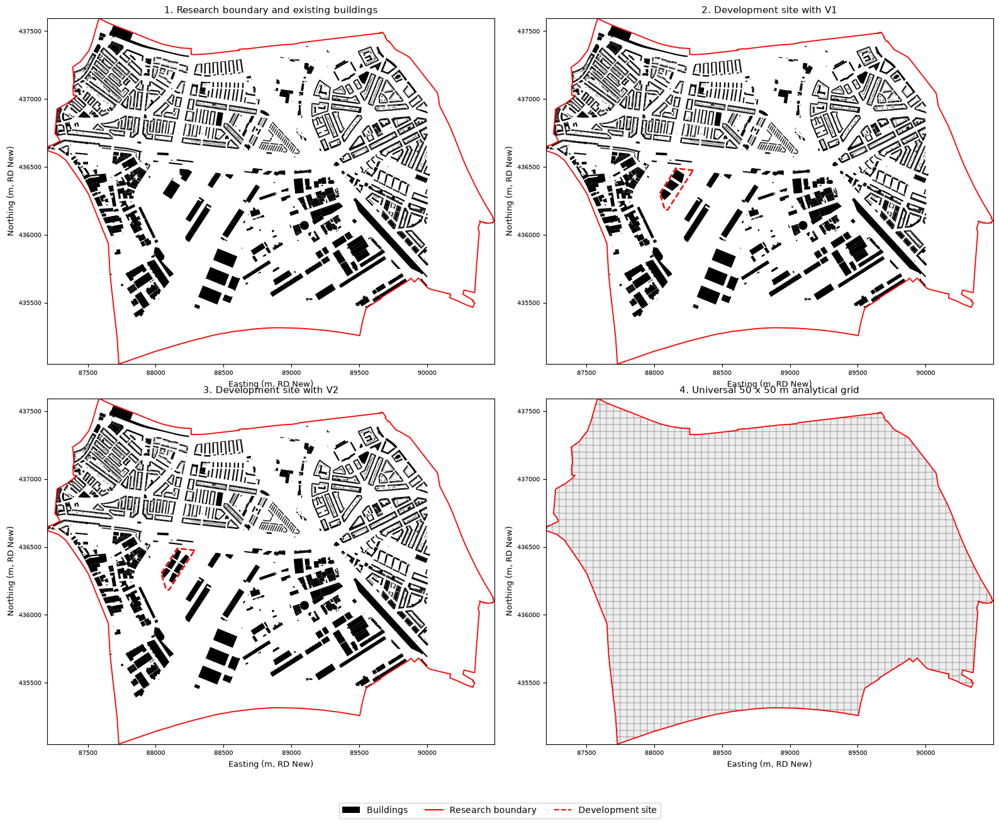

In [28]:
# Introduction: four linked maps, shared district extent.
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
items = [('Existing', '1. Research boundary and existing buildings', False),
         ('V1', '2. Development site with V1', True),
         ('V2', '3. Development site with V2', True),
         (None, '4. Universal 50 x 50 m analytical grid', False)]
for ax, (name, title, site) in zip(axes.ravel(), items):
    if name is None:
        GRID_DISPLAY.plot(ax=ax, facecolor='#eeeeee', edgecolor='#777777', linewidth=0.35)
    else:
        V[name]['buildings'].plot(ax=ax, color='black', edgecolor='none')
    STUDY_AREA.boundary.plot(ax=ax, color='red', linewidth=1.3)
    if site:
        DEVELOPMENT_SITE.boundary.plot(ax=ax, color='red', linewidth=1.8, linestyle='--')
    format_axes(ax, title, EXTENDED_BOUNDS)
fig.legend(handles=[Patch(facecolor='black', label='Buildings'),
                    Line2D([0], [0], color='red', label='Research boundary'),
                    Line2D([0], [0], color='red', linestyle='--', label='Development site')],
           loc='lower center', ncol=3)
fig.tight_layout(rect=(0, 0.06, 1, 1))
show_fig(fig, 'introduction_four_maps')
# Save individual panels as well, using the existing PNG convention.
for name, title, site in items:
    fig, ax = plt.subplots(figsize=(9, 8))
    if name is None:
        GRID_DISPLAY.plot(ax=ax, facecolor='#eeeeee', edgecolor='#777777', linewidth=0.35)
    else:
        V[name]['buildings'].plot(ax=ax, color='black', edgecolor='none')
    STUDY_AREA.boundary.plot(ax=ax, color='red', linewidth=1.3)
    if site:
        DEVELOPMENT_SITE.boundary.plot(ax=ax, color='red', linewidth=1.8, linestyle='--')
    format_axes(ax, title, EXTENDED_BOUNDS)
    save_fig(fig, title, 'introduction')
    plt.close(fig)

## Factor 1: Mean roof height, variation and volume

All calculations use mean roof height above ground. Existing mean attributes are used when available; otherwise a positive nDSM zonal mean is calculated. Uniform proposal `height_m` values are interpreted as mean building heights. Roof surfaces for SVF use ground elevation plus mean height. Extruded footprint area times mean height remains a massing volume estimate.

Legacy `h_max` output attributes are compatibility aliases for mean height only. No maximum-roof field is used. The tallest-building statistic is the highest building mean, not the maximum roof elevation.

Height classes are displayed on filled 50 m cells using footprint-area-weighted mean heights. Cells without height support remain No data. Building-height and roof-surface continuous maps remain available.


In [11]:
# Diagnose the failed Factor 1 check without recalculating heights.
uf_height_check = _existing.loc[_inside_uf].copy()

mean_height = pd.to_numeric(
    uf_height_check['h_mean'], errors='coerce'
)
ground_elevation = pd.to_numeric(
    uf_height_check['base_nap_m'], errors='coerce'
)

uf_height_check['missing_mean_height'] = (
    ~np.isfinite(mean_height) | mean_height.le(0)
)
uf_height_check['missing_ground_elevation'] = (
    ~np.isfinite(ground_elevation)
)

diagnosis = pd.Series({
    'Building parts inside UF boundary': len(uf_height_check),
    'Missing mean height only': int((
        uf_height_check['missing_mean_height']
        & ~uf_height_check['missing_ground_elevation']
    ).sum()),
    'Missing ground elevation only': int((
        ~uf_height_check['missing_mean_height']
        & uf_height_check['missing_ground_elevation']
    ).sum()),
    'Missing both': int((
        uf_height_check['missing_mean_height']
        & uf_height_check['missing_ground_elevation']
    ).sum()),
    'Valid mean height and ground elevation': int((
        ~uf_height_check['missing_mean_height']
        & ~uf_height_check['missing_ground_elevation']
    ).sum()),
}, name='Building parts')

print('Boundary used:', STUDY_AREA_FILE)
print('Boundary layer:', STUDY_AREA_LAYER)

display(diagnosis.to_frame())
display(_source_audit)

# Show the actual height-related attributes available in the building layer.
height_fields = [
    c for c in uf_height_check.columns
    if any(
        word in str(c).casefold()
        for word in ['height', 'roof', 'ground', 'maaiveld', 'dak', 'nap']
    )
    or str(c).casefold().startswith(('rf_h_', 'b3_h_'))
]

problem_rows = uf_height_check.loc[
    uf_height_check['missing_mean_height']
    | uf_height_check['missing_ground_elevation']
]

identifier_fields = [
    c for c in ['building_key', 'bag_id']
    if c in problem_rows.columns
]

display(
    problem_rows[
        list(dict.fromkeys(identifier_fields + height_fields))
    ].head(15)
)

Boundary used: H:\GCS Final Project\GCS_FA_QGIS\GCS_FA_Boundary_UF.gpkg
Boundary layer: output


,Building parts
Building parts inside UF boundary,9086
Missing mean height only,3065
Missing ground elevation only,0
Missing both,0
Valid mean height and ground elevation,6021


,Source,Terrain,UF extent coverage (%),Status
0,H:\GCS Final Project\GCS_FA_QGIS\GCS_FP_DSM-DT...,,47.750197,Available; valid pixels checked below
1,H:\GCS Final Project\GCS_FA_QGIS\GCS_FP_DSM_RA...,H:\GCS Final Project\GCS_FA_QGIS\GCS_FP_DTM_RA...,47.750197,Available; valid pixels checked below
2,C:\Users\micha\Documents\Education\University\...,C:\Users\micha\Documents\Education\University\...,79.343724,Available; valid pixels checked below


,building_key,bag_id,rf_h_ground,rf_h_roof_min,rf_h_roof_ridge,rf_h_roof_50p,rf_h_roof_70p,rf_h_roof_max,rf_roof_type,rf_is_glass_roof,base_nap_m,height_source,roof_nap_m,height_valid,height_class,height_m,_height_key,missing_mean_height,missing_ground_elevation
0,existing:0606100000002478,0606100000002478,0.724,2.744576,NaN,2.823898,2.849300,2.898820,slanted,False,0.724,,NaN,False,No data,NaN,existing:0606100000002478:01060000000100000001...,True,False
6,existing:0606100000012723,0606100000012723,-1.712,3.994776,10.464532,4.250617,4.353737,7.107081,slanted,False,-1.712,,NaN,False,No data,NaN,existing:0606100000012723:01060000000100000001...,True,False
7,existing:0606100000012723,0606100000012723,-1.712,7.107081,10.464532,7.337740,7.419954,10.030671,slanted,False,-1.712,,NaN,False,No data,NaN,existing:0606100000012723:01060000000100000001...,True,False
8,existing:0606100000012723,0606100000012723,-1.712,7.227907,10.464532,10.256111,10.447673,12.390083,slanted,False,-1.712,,NaN,False,No data,NaN,existing:0606100000012723:01060000000100000001...,True,False
9,existing:0606100000020577,0606100000020577,-0.858,5.833348,NaN,8.536664,8.548761,8.570733,slanted,False,-0.858,,NaN,False,No data,NaN,existing:0606100000020577:01060000000100000001...,True,False
10,existing:0606100000002374,0606100000002374,-1.192,9.379246,13.990479,9.856699,10.076439,12.579709,slanted,False,-1.192,,NaN,False,No data,NaN,existing:0606100000002374:01060000000100000001...,True,False
11,existing:0606100000002374,0606100000002374,-1.192,9.587613,13.990479,12.666445,12.835745,15.652079,slanted,False,-1.192,,NaN,False,No data,NaN,existing:0606100000002374:01060000000100000001...,True,False
12,existing:0606100000014324,0606100000014324,-1.480,7.208739,NaN,9.920372,9.946784,9.992511,multiple horizontal,False,-1.480,,NaN,False,No data,NaN,existing:0606100000014324:01060000000100000001...,True,False
13,existing:0606100000014324,0606100000014324,-1.480,4.162564,NaN,4.229480,4.254206,7.229813,multiple horizontal,False,-1.480,,NaN,False,No data,NaN,existing:0606100000014324:01060000000100000001...,True,False
14,existing:0606100000019864,0606100000019864,-0.638,13.702223,18.214966,16.481062,17.490253,19.350914,slanted,False,-0.638,,NaN,False,No data,NaN,existing:0606100000019864:01060000000100000001...,True,False


Research boundary: H:\GCS Final Project\GCS_FA_QGIS\GCS_FA_Boundary_UF.gpkg
Boundary layer: output
Research area: 5,713,207.14 m2
Height basis: maximum roof elevation minus ground elevation


C:\Users\micha\AppData\Local\Temp\ipykernel_33496\796604246.py:270: UserWarning: Existing: 209 existing building parts have unknown height. Their footprints are retained, but they are excluded from height-dependent calculations. See the saved factor1_invalid_maximum_roof_heights table.
  warnings.warn(
C:\Users\micha\AppData\Local\Temp\ipykernel_33496\796604246.py:562: UserWarning: Existing: overlapping footprint parts (4185.31 m2). Volume remains a part-extrusion sum; inspect overlapping masses.
  warnings.warn(
C:\Users\micha\AppData\Local\Temp\ipykernel_33496\796604246.py:270: UserWarning: V1: 209 existing building parts have unknown height. Their footprints are retained, but they are excluded from height-dependent calculations. See the saved factor1_invalid_maximum_roof_heights table.
  warnings.warn(
C:\Users\micha\AppData\Local\Temp\ipykernel_33496\796604246.py:562: UserWarning: V1: overlapping footprint parts (4185.31 m2). Volume remains a part-extrusion sum; inspect overlapping

,Existing geometry parts,Proposal geometry parts,Parts intersecting UF,Valid height parts,Minimum model height (m),Maximum model height (m)
Scenario,,,,,,
Existing,9085,0,9085,8876,0.003,96.128
V1,9080,3,9083,8874,0.003,96.128
V2,9080,6,9086,8877,0.003,96.128


,,Buildings (unique IDs),Geometry parts,Buildings with measured height,Mean maximum-roof model height (m),Tallest maximum-roof height (m),Height std across building IDs (m),Volume estimate inside study (m³),Known-height footprint coverage (%)
Scope,Scenario,,,,,,,,
Extended area,Existing,6729,9085,6529,10.443,96.128,5.280,1.340515e+07,99.187
Pier buildings / proposal,Existing,3,5,3,8.081,13.496,4.182,1.503597e+05,100.000
Extended area,V1,6729,9083,6529,10.457,96.128,5.317,1.378424e+07,99.185
Pier buildings / proposal,V1,3,3,3,39.000,48.000,7.348,5.294543e+05,100.000
Extended area,V2,6732,9086,6532,10.466,96.128,5.334,1.378008e+07,99.187
Pier buildings / proposal,V2,6,6,6,34.500,48.000,8.617,5.252910e+05,100.000


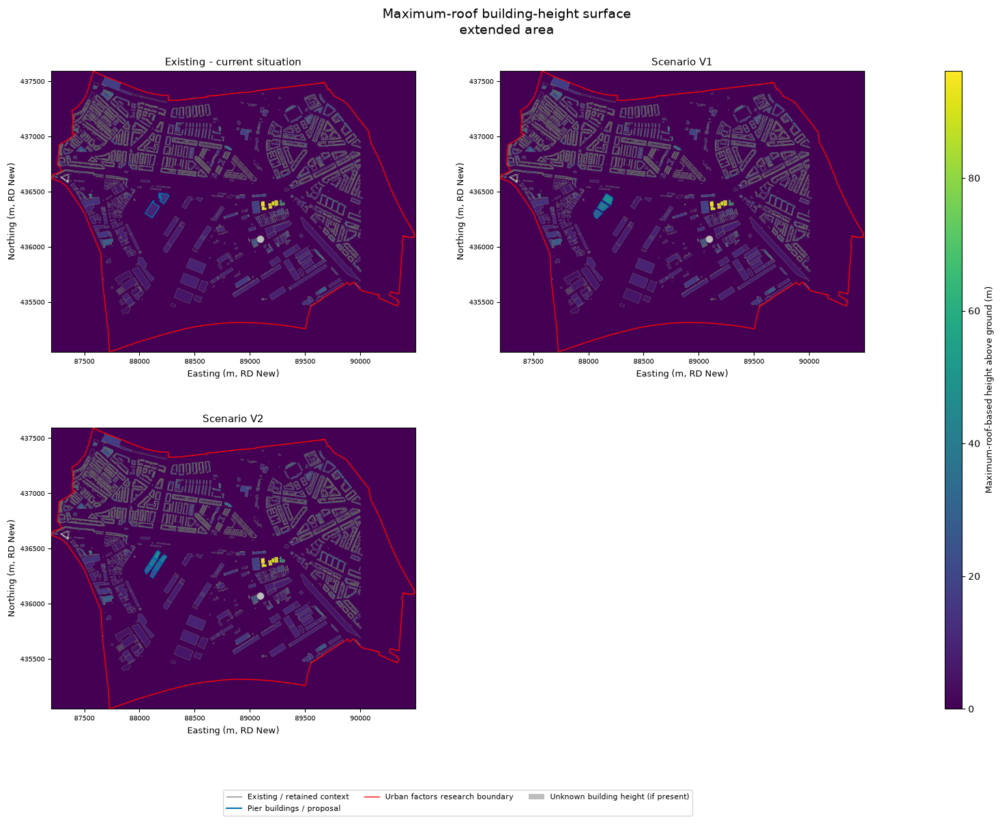

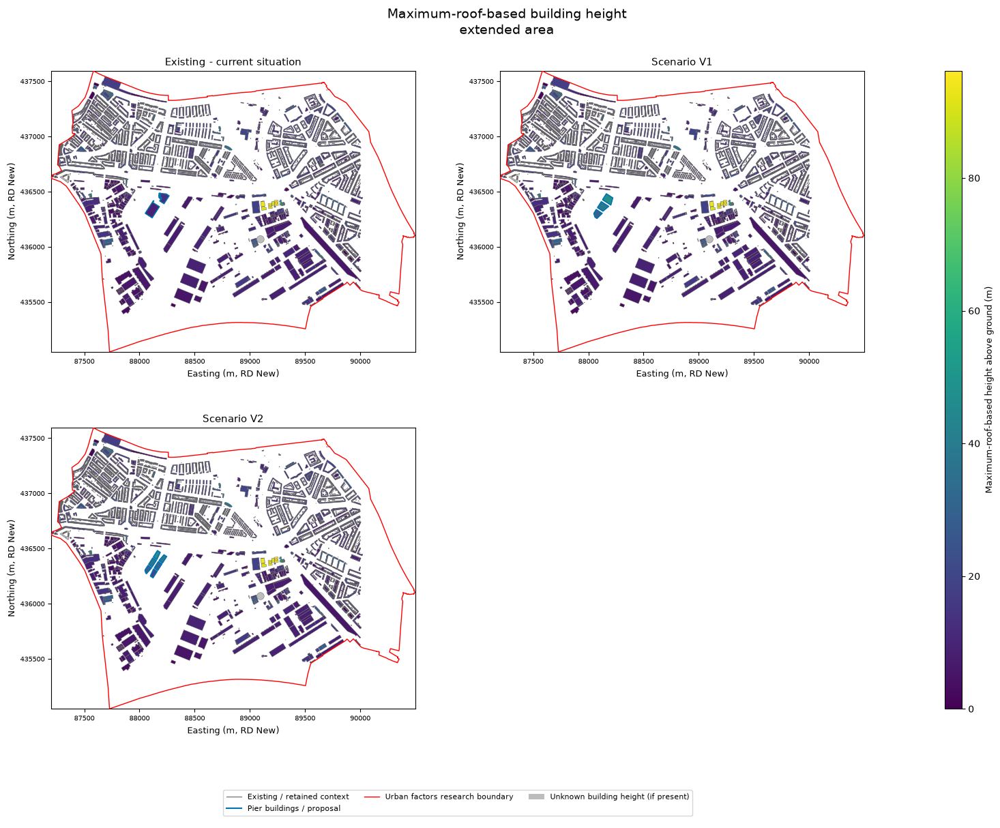

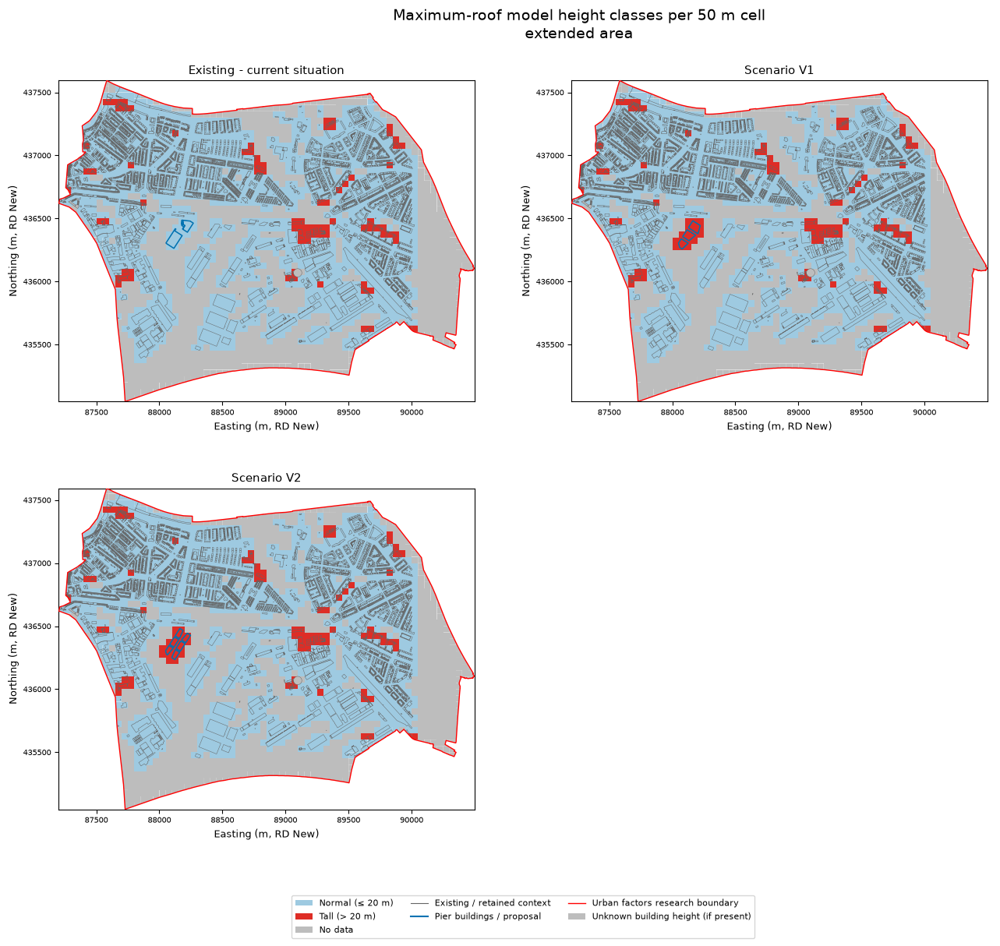

Existing heights use rf_h_roof_max minus rf_h_ground. Proposal heights retain their declared uniform values.
h_mean is a compatibility field containing the selected maximum-roof-based model height, not mean roof height.
Volume is an upper-envelope block estimate, not a surveyed building volume.
Factor 1 complete. Rerun Factor 2 and every later factor because the height model has changed.


In [31]:
# Factor 1 - Maximum-roof height, variation and block-volume estimate
# Existing buildings: rf_h_roof_max minus rf_h_ground.
# Proposals: their declared uniform height_m.
# h_mean is retained as a compatibility field, not an arithmetic mean.

from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import rasterio

from rasterio.features import rasterize
from rasterio.transform import from_origin


# ------------------------------------------------------------
# 1. Load and enforce the UF research boundary
# ------------------------------------------------------------

STUDY_AREA_FILE = DATA_DIR / "GCS_FA_Boundary_UF.gpkg"

available_layers = gpd.list_layers(STUDY_AREA_FILE)
polygon_layers = available_layers.loc[
    available_layers["geometry_type"]
    .fillna("")
    .str.contains("Polygon", case=False),
    "name"
].tolist()

preferred_layer = globals().get("STUDY_AREA_LAYER")

if preferred_layer in polygon_layers:
    STUDY_AREA_LAYER = preferred_layer
elif len(polygon_layers) == 1:
    STUDY_AREA_LAYER = polygon_layers[0]
else:
    raise ValueError(
        "Select the research-boundary layer explicitly. "
        f"Available polygon layers: {polygon_layers}"
    )

STUDY_AREA = read_vector(
    STUDY_AREA_FILE,
    STUDY_AREA_LAYER,
    "Urban factors research boundary"
).dissolve().reset_index(drop=True)

STUDY_GEOM = union_geometry(STUDY_AREA)
EXTENDED_BOUNDS = tuple(STUDY_AREA.total_bounds)

GRID_SIZE_M = 50.0
FINE_GRID_SIZE_M = 25.0
SVF_SPACING_M = 25.0

MODEL_GEOM = STUDY_GEOM.buffer(
    max(
        SVF_MAX_DIST_M,
        HW_RADIUS_M,
        GRID_SIZE_M * np.sqrt(2)
    ) + 10
)

print("Research boundary:", STUDY_AREA_FILE)
print("Boundary layer:", STUDY_AREA_LAYER)
print(f"Research area: {STUDY_GEOM.area:,.2f} m2")
print("Height basis: maximum roof elevation minus ground elevation")


# ------------------------------------------------------------
# 2. Refresh the 50 m and 25 m spatial supports
# ------------------------------------------------------------

GRID = aligned_grid(
    GRID_SIZE_M,
    STUDY_GEOM,
    EXTENDED_BOUNDS
)

GRID_DISPLAY = GRID.copy()
GRID_DISPLAY.geometry = (
    GRID_DISPLAY.geometry.intersection(STUDY_GEOM)
)

FINE_GRID = aligned_grid(
    FINE_GRID_SIZE_M,
    STUDY_GEOM,
    EXTENDED_BOUNDS
)

FINE_GRID.geometry = (
    FINE_GRID.geometry.intersection(STUDY_GEOM)
)

# Preserve the configured raster pixel sizes and previous origin,
# but extend the surface to cover the complete UF model extent.
dx = float(SURF_RES_X)
dy = float(SURF_RES_Y)

origin_x = SURF_TRANSFORM.c
origin_y = SURF_TRANSFORM.f

mx0, my0, mx1, my1 = MODEL_GEOM.bounds

col0 = math.floor((mx0 - origin_x) / dx)
col1 = math.ceil((mx1 - origin_x) / dx)

row0 = math.floor((origin_y - my1) / dy)
row1 = math.ceil((origin_y - my0) / dy)

SURF_TRANSFORM = from_origin(
    origin_x + col0 * dx,
    origin_y - row0 * dy,
    dx,
    dy
)

SURF_SHAPE = (
    row1 - row0,
    col1 - col0
)

SURF_BOUNDS = rasterio.transform.array_bounds(
    *SURF_SHAPE,
    SURF_TRANSFORM
)

SURF_RES = min(dx, dy)


# ------------------------------------------------------------
# 3. Assign maximum-roof-based heights to every scenario
# ------------------------------------------------------------

RESULTS = {name: {} for name in SCENARIO_NAMES}
SUMMARY = {name: {} for name in SCENARIO_NAMES}

height_records = []
height_audit_records = []

for name in SCENARIO_NAMES:
    b = V[name]["buildings"].copy()

    # Existing data import identifies proposals through role.
    proposal_mask = (
        b["role"]
        .astype(str)
        .str.casefold()
        .eq("proposal")
    )
    existing_mask = ~proposal_mask

    b["height_basis"] = ""
    b["height_source"] = ""

    if existing_mask.any():
        roof_col = column(
            b,
            "rf_h_roof_max",
            required=True
        )
        ground_col = column(
            b,
            "rf_h_ground",
            required=True
        )

        roof = numeric(
            b.loc[existing_mask, roof_col]
        )
        ground = numeric(
            b.loc[existing_mask, ground_col]
        )

        # Negative NAP ground elevations are allowed.
        # Missing values and large negative NoData sentinels are not.
        valid_roof = (
            np.isfinite(roof)
            & roof.gt(-9999)
        )
        valid_ground = (
            np.isfinite(ground)
            & ground.gt(-9999)
        )

        height = roof - ground

        valid_height = (
            valid_roof
            & valid_ground
            & np.isfinite(height)
            & height.gt(0)
        )

        # Keep invalid buildings, but leave their height unknown.
        # Do not replace negative differences with absolute values.
        model_height = height.where(valid_height, np.nan)

        b.loc[existing_mask, "base_nap_m"] = (
            ground.where(valid_ground, np.nan).to_numpy()
        )

        b.loc[existing_mask, "roof_nap_m"] = (
            roof.where(valid_height, np.nan).to_numpy()
        )

        # Compatibility fields used by downstream factors.
        b.loc[existing_mask, "h_mean"] = (
            model_height.to_numpy()
        )
        b.loc[existing_mask, "h_max"] = (
            model_height.to_numpy()
        )

        b.loc[existing_mask, "height_basis"] = (
            "maximum_roof"
        )

        height_source = pd.Series(
            "Unknown building height",
            index=height.index,
            dtype=object
        )
        height_source.loc[valid_height] = (
            f"{roof_col} minus {ground_col}"
        )

        b.loc[existing_mask, "height_source"] = (
            height_source.to_numpy()
        )

        # Record why each invalid height was rejected.
        height_issue = pd.Series(
            "",
            index=height.index,
            dtype=object
        )

        height_issue.loc[
            ~valid_roof | ~valid_ground
        ] = "Missing or invalid roof/ground elevation"

        height_issue.loc[
            valid_roof
            & valid_ground
            & height.le(0)
        ] = "Roof minus ground is zero or negative"

        if "height_issue" not in b.columns:
            b["height_issue"] = ""

        b.loc[existing_mask, "height_issue"] = (
            height_issue.to_numpy()
        )

        invalid_indices = height.index[~valid_height]

        if len(invalid_indices):
            save_table(
                b.loc[invalid_indices].drop(
                    columns="geometry"
                ),
                "factor1_invalid_maximum_roof_heights",
                name
            )

            warnings.warn(
                f"{name}: {len(invalid_indices)} existing "
                "building parts have unknown height. "
                "Their footprints are retained, but they "
                "are excluded from height-dependent "
                "calculations. See the saved "
                "factor1_invalid_maximum_roof_heights table."
            )

    if proposal_mask.any():
        cfg = VERSIONS.get(name, {})
        requested_height_col = cfg.get(
            "height_column",
            "height_m"
        )

        proposal_height_col = column(
            b,
            requested_height_col
        )

        if proposal_height_col is not None:
            proposal_height = numeric(
                b.loc[proposal_mask, proposal_height_col]
            )
        else:
            # Preserve the uniform heights assembled during import.
            proposal_height = numeric(
                b.loc[proposal_mask, "h_mean"]
            )

        proposal_base = numeric(
            b.loc[proposal_mask, "base_nap_m"]
        )

        bad_proposal = (
            ~np.isfinite(proposal_height)
            | proposal_height.le(0)
            | ~np.isfinite(proposal_base)
        )

        if bad_proposal.any():
            raise ValueError(
                f"{name}: proposal heights or base elevations "
                "are invalid. Proposal heights are never replaced "
                "with existing-building raster values."
            )

        b.loc[proposal_mask, "h_mean"] = (
            proposal_height.to_numpy()
        )
        b.loc[proposal_mask, "h_max"] = (
            proposal_height.to_numpy()
        )
        b.loc[proposal_mask, "base_nap_m"] = (
            proposal_base.to_numpy()
        )
        b.loc[proposal_mask, "roof_nap_m"] = (
            proposal_base + proposal_height
        ).to_numpy()

        b.loc[proposal_mask, "height_basis"] = (
            "uniform_proposal_height"
        )
        b.loc[proposal_mask, "height_source"] = (
            "Declared uniform proposal height"
        )

    for field in [
        "h_mean",
        "h_max",
        "base_nap_m",
        "roof_nap_m"
    ]:
        b[field] = pd.to_numeric(
            b[field],
            errors="coerce"
        )

    b["height_valid"] = (
        np.isfinite(b["h_mean"])
        & b["h_mean"].gt(0)
        & np.isfinite(b["base_nap_m"])
        & np.isfinite(b["roof_nap_m"])
    )

    b["height_class"] = classify(
        b["h_mean"],
        "height"
    )

    b["footprint_m2"] = b.area
    b["study_area_m2"] = (
        b.geometry.intersection(STUDY_GEOM).area
    )

    b["volume_m3"] = (
        b["footprint_m2"] * b["h_mean"]
    )
    b["study_volume_m3"] = (
        b["study_area_m2"] * b["h_mean"]
    )

    valid = b.loc[b["height_valid"]].sort_values(
        "roof_nap_m",
        kind="stable"
    )

    if valid.empty:
        raise ValueError(
            f"{name}: no valid maximum-roof-based heights."
        )

    # Highest absolute roof wins where footprints overlap.
    roof_surface = rasterize(
        [
            (geom, float(height))
            for geom, height in zip(
                valid.geometry,
                valid["roof_nap_m"]
            )
        ],
        out_shape=SURF_SHAPE,
        transform=SURF_TRANSFORM,
        fill=np.nan,
        dtype="float32"
    )

    # Highest above-ground height wins in the height display.
    height_order = valid.sort_values(
        "h_mean",
        kind="stable"
    )

    height_surface = rasterize(
        [
            (geom, float(height))
            for geom, height in zip(
                height_order.geometry,
                height_order["h_mean"]
            )
        ],
        out_shape=SURF_SHAPE,
        transform=SURF_TRANSFORM,
        fill=0,
        dtype="float32"
    )

    V[name].update({
        "buildings": b,
        "ndsm": height_surface,
        "roof_surface": roof_surface
    })

    RESULTS[name]["buildings"] = b

    save_table(
        b.drop(columns="geometry"),
        "building_height_volume_parts",
        name
    )

    height_audit_records.append({
        "Scenario": name,
        "Existing geometry parts": int(existing_mask.sum()),
        "Proposal geometry parts": int(proposal_mask.sum()),
        "Parts intersecting UF": int(
            b["study_area_m2"].gt(0).sum()
        ),
        "Valid height parts": int(
            b["height_valid"].sum()
        ),
        "Minimum model height (m)": valid["h_mean"].min(),
        "Maximum model height (m)": valid["h_mean"].max()
    })

    # Retain legacy scope names so comparison code keeps working.
    for scope, title in [
        ("study", "Extended area"),
        ("pier", "Pier buildings / proposal")
    ]:
        selected = subset_scope(b, scope)

        measured = selected.loc[
            selected["height_valid"]
            & selected["study_area_m2"].gt(0)
        ].copy()

        aggregates = measured.groupby(
            "building_key"
        ).agg(
            area_m2=("study_area_m2", "sum"),
            volume_m3=("study_volume_m3", "sum"),
            maximum_height_m=("h_max", "max")
        )

        # Area-weighted model height across parts of each BAG ID.
        # This averages maximum-roof-based part heights,
        # not measured arithmetic mean roof heights.
        aggregates["representative_height_m"] = (
            aggregates["volume_m3"]
            / aggregates["area_m2"]
        )

        h = aggregates["representative_height_m"]
        tallest = aggregates["maximum_height_m"].max()

        denominator = selected["study_area_m2"].sum()

        known_coverage = (
            100 * measured["study_area_m2"].sum()
            / denominator
            if denominator > 0
            else np.nan
        )

        volume_total = aggregates["volume_m3"].sum(
            min_count=1
        )

        height_records.append({
            "Scenario": name,
            "Scope": title,
            "Buildings (unique IDs)": id_count(selected),
            "Geometry parts": len(selected),
            "Buildings with measured height": len(aggregates),
            "Mean maximum-roof model height (m)": h.mean(),
            "Tallest maximum-roof height (m)": tallest,
            "Height std across building IDs (m)": h.std(ddof=0),
            "Volume estimate inside study (m³)": volume_total,
            "Known-height footprint coverage (%)": known_coverage
        })

        prefix = "Pier" if scope == "pier" else "Extended"

        store_summary(name, **{
            f"{prefix}: buildings (count)": id_count(selected),
            f"{prefix}: maximum-roof model mean height (m)": (
                float(h.mean())
            ),
            f"{prefix}: maximum-roof height (m)": (
                float(tallest)
            ),
            f"{prefix}: height std (m)": (
                float(h.std(ddof=0))
            ),
            f"{prefix}: block volume estimate (m³)": (
                float(volume_total)
            )
        })

        save_table(
            aggregates,
            f"height_by_building_id_{scope}",
            name
        )

        counts = (
            pd.Series(classify(h, "height"))
            .value_counts()
            .reindex(
                class_orders()["height"],
                fill_value=0
            )
            .to_frame("Buildings")
        )

        counts["Percentage (%)"] = (
            counts["Buildings"]
            / max(len(h), 1)
            * 100
        )

        save_table(
            counts,
            f"height_classes_{scope}",
            name
        )

    selected_study = subset_scope(b)

    overlap = (
        b.loc[
            b["study_area_m2"].gt(0),
            "study_area_m2"
        ].sum()
        - union_geometry(selected_study)
        .intersection(STUDY_GEOM)
        .area
    )

    if overlap > 0.1:
        warnings.warn(
            f"{name}: overlapping footprint parts "
            f"({overlap:.2f} m2). Volume remains a "
            "part-extrusion sum; inspect overlapping masses."
        )


# ------------------------------------------------------------
# 4. Refresh SVF receptor locations for the verified UF extent
# ------------------------------------------------------------

SVF_POINTS = gpd.GeoDataFrame(
    geometry=FINE_GRID.geometry.representative_point(),
    crs=ANALYSIS_CRS
)

SVF_POINTS["fine_id"] = FINE_GRID["grid_id"].to_numpy()
SVF_POINTS["point_id"] = np.arange(len(SVF_POINTS))
SVF_POINTS["in_pier_window"] = (
    SVF_POINTS.intersects(FOCUS_GEOM)
)

SVF_POINTS["ground_nap_m"] = float(
    SVF_GROUND_NAP_M
)
SVF_POINTS["ground_source"] = (
    "Configured fallback"
)

if (
    USE_DTM_RECEPTOR_ELEVATIONS
    and DTM_FILE
    and Path(DTM_FILE).is_file()
):
    with rasterio.open(DTM_FILE) as src:
        if src.crs is None:
            raise ValueError("The receptor DTM has no CRS.")

        sample_points = SVF_POINTS.to_crs(src.crs)

        sampled = np.ma.vstack(
            list(
                src.sample(
                    zip(
                        sample_points.geometry.x,
                        sample_points.geometry.y
                    ),
                    masked=True
                )
            )
        )[:, 0]

        elevations = np.ma.filled(
            sampled.astype(float),
            np.nan
        )

        observed = np.isfinite(elevations)

        SVF_POINTS.loc[
            observed,
            "ground_nap_m"
        ] = elevations[observed]

        SVF_POINTS.loc[
            observed,
            "ground_source"
        ] = "Observed DTM"

baseline_buildings = V[BASELINE_VERSION]["buildings"]

invalid_context = baseline_buildings.loc[
    ~baseline_buildings["height_valid"]
].copy()

SVF_POINTS["unknown_height_footprint"] = (
    shapely.covers(
        union_geometry(invalid_context),
        SVF_POINTS.geometry.to_numpy()
    )
)

fallback_count = int(
    SVF_POINTS["ground_source"]
    .eq("Configured fallback")
    .sum()
)

if fallback_count:
    warnings.warn(
        f"{fallback_count} SVF receptors use the configured "
        "ground-elevation fallback. Building heights now "
        "come from attributes, but the receptor DTM may "
        "still have limited coverage."
    )


# ------------------------------------------------------------
# 5. Save summaries and create the Factor 1 maps
# ------------------------------------------------------------

HEIGHT_AUDIT = pd.DataFrame(
    height_audit_records
).set_index("Scenario")

save_table(
    HEIGHT_AUDIT,
    "factor1_maximum_roof_audit",
    "quality"
)

HEIGHT_TABLE = pd.DataFrame(
    height_records
).set_index(["Scope", "Scenario"])

save_table(
    HEIGHT_TABLE,
    "factor1_height_summary"
)

display(HEIGHT_AUDIT.round(3))
display(HEIGHT_TABLE.round(3))

max_h = max(
    float(
        V[name]["buildings"]
        .loc[
            V[name]["buildings"]["height_valid"],
            "h_mean"
        ]
        .max()
    )
    for name in SCENARIO_NAMES
)

map_series(
    {name: V[name]["ndsm"] for name in SCENARIO_NAMES},
    None,
    "Maximum-roof building-height surface",
    "factor1_ndsm",
    "Maximum-roof-based height above ground (m)",
    limits=(0, max_h),
    extents=("extended",)
)

map_series(
    {
        name: V[name]["buildings"]
        for name in SCENARIO_NAMES
    },
    "h_mean",
    "Maximum-roof-based building height",
    "factor1_mean_height",
    "Maximum-roof-based height above ground (m)",
    limits=(0, max_h),
    extents=("extended",)
)

for name in SCENARIO_NAMES:
    height_cells = aggregate_polygons(
        V[name]["buildings"],
        GRID,
        "h_mean"
    )

    height_cells["height_class"] = classify(
        height_cells["h_mean"],
        "height"
    )
    height_cells["height_basis"] = (
        "footprint-area-weighted maximum-roof model"
    )

    RESULTS[name]["height_grid"] = height_cells

    save_table(
        height_cells.drop(columns="geometry"),
        "mean_height_50m_cells",
        name
    )

map_series(
    {
        name: RESULTS[name]["height_grid"]
        for name in SCENARIO_NAMES
    },
    "height_class",
    "Maximum-roof model height classes per 50 m cell",
    "factor1_height_classes",
    factor="height",
    extents=("extended",)
)

print(
    "Existing heights use rf_h_roof_max minus rf_h_ground. "
    "Proposal heights retain their declared uniform values."
)
print(
    "h_mean is a compatibility field containing the selected "
    "maximum-roof-based model height, not mean roof height."
)
print(
    "Volume is an upper-envelope block estimate, "
    "not a surveyed building volume."
)
print(
    "Factor 1 complete. Rerun Factor 2 and every later "
    "factor because the height model has changed."
)

## Factor 2: Plan area density

Unioned footprint area within each complete 50 m square is divided by 2500 m2. Maps clip the display geometry to the UF boundary only. District-wide density is separately computed inside the actual research boundary, including water. Boundary-cell density and district density therefore use explicitly different supports. FSI remains an estimated floor-height-based massing indicator.


Extended λp and FSI retain the agreed boundary, INCLUDING WATER. No new pier-density denominator is invented.
Estimated FSI assumes 3 m per floor and excludes unknown-height buildings.


,Extended study area (m²),Unioned built area (m²),Extended λp,Extended coverage (%),Pier/proposal footprint (m²),"Estimated GFA, known heights only (m²)",Estimated FSI,Area-weighted λp in cells touching pier display window
Scenario,,,,,,,,
Existing,5.713207e+06,1.150705e+06,0.2014,20.1411,14699.7734,3.881733e+06,0.6794,0.1626
V1,5.713207e+06,1.149169e+06,0.2011,20.1143,13163.4760,4.018144e+06,0.7033,0.1516
V2,5.713207e+06,1.151205e+06,0.2015,20.1499,15199.6989,4.016756e+06,0.7031,0.1661


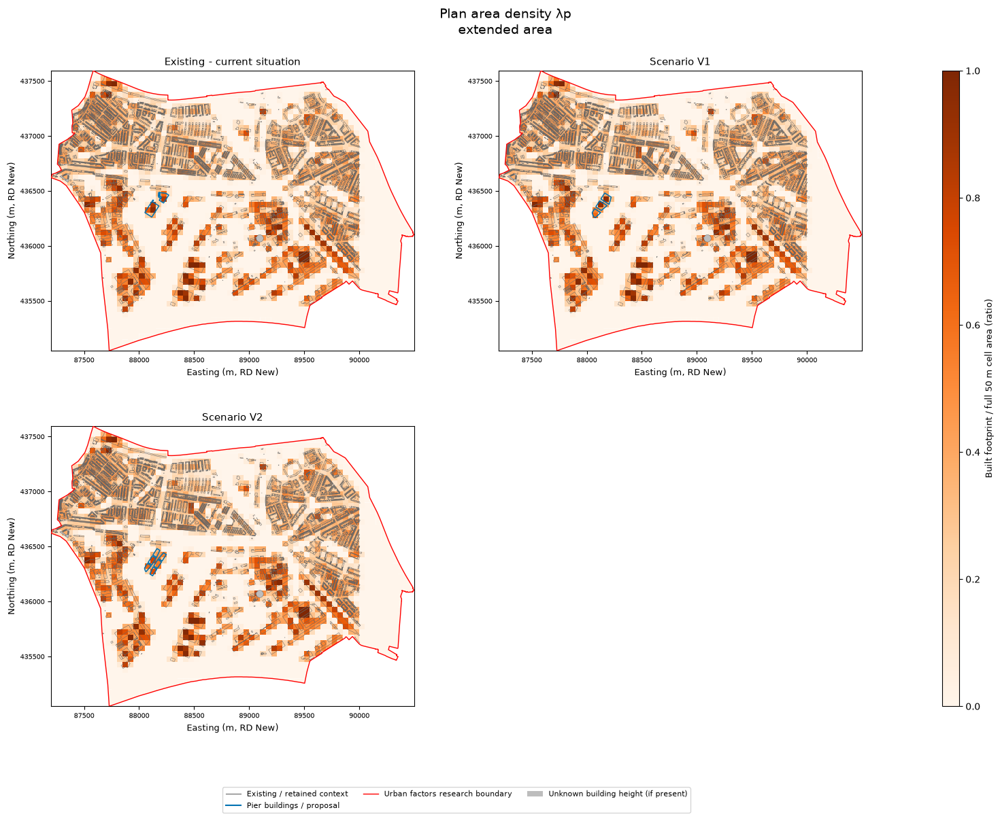

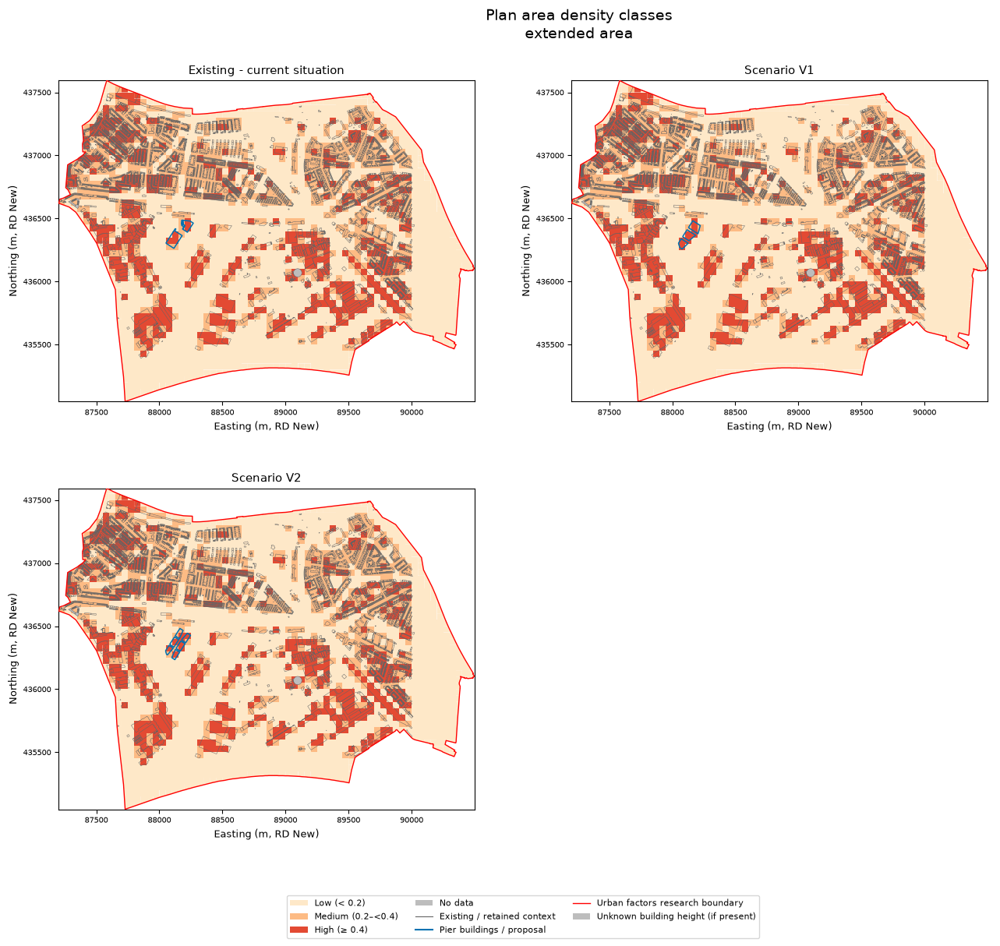

Factor 2 complete. Continue with Factor 3.


In [32]:
# Factor 2 - Footprint density λp and estimated FSI
# λp uses unioned footprints so overlapping parts are not counted twice.
density_records = []
for name in SCENARIO_NAMES:
    if 'buildings' not in RESULTS[name]:
        raise RuntimeError('Run Factor 1 before Factor 2.')
    RESULTS[name].pop('hw_points', None)
    RESULTS[name].pop('svf_points', None)
    for metric in list(SUMMARY[name]):
        if 'enclosure proxy' in metric or 'SVF' in metric:
            SUMMARY[name].pop(metric)
    b = V[name]['buildings']
    grid = GRID.copy()
    building_union = union_geometry(b)
    grid['built_area_m2'] = grid.geometry.intersection(building_union).area
    grid['lambda_p'] = grid['built_area_m2'] / grid['cell_area_m2']
    grid['density_class'] = classify(grid['lambda_p'], 'density')
    if (grid['lambda_p'] > 1 + 1e-8).any():
        raise ValueError(f'{name}: λp exceeds one; inspect invalid geometry.')
    RESULTS[name]['grid'] = grid
    save_table(grid.drop(columns='geometry'), 'density_per_cell', name)
    # Rounded-down floor count is only a massing assumption, not a measured FSI.
    floor_count = np.maximum(1, np.floor(b['h_mean'] / FLOOR_HEIGHT_M))
    known_gfa = float((b['study_area_m2'] * floor_count).where(b['height_valid']).sum())
    area = STUDY_GEOM.area
    built_area = building_union.intersection(STUDY_GEOM).area
    lp = built_area / area
    pier = b.loc[b['is_focus']]
    pier_union_area = union_geometry(pier).intersection(STUDY_GEOM).area
    focus_grid = grid.loc[grid['in_pier_window']]
    density_records.append({
        'Scenario': name, 'Extended study area (m²)': area, 'Unioned built area (m²)': built_area,
        'Extended λp': lp, 'Extended coverage (%)': 100 * lp,
        'Pier/proposal footprint (m²)': pier_union_area,
        'Estimated GFA, known heights only (m²)': known_gfa, 'Estimated FSI': known_gfa / area,
        'Area-weighted λp in cells touching pier display window': focus_grid['built_area_m2'].sum() / focus_grid['cell_area_m2'].sum()
            if len(focus_grid) else np.nan,
    })
    store_summary(name, **{
        'Extended: λp (ratio)': lp, 'Extended: estimated FSI (ratio)': known_gfa / area,
        'Pier: footprint area (m²)': pier_union_area,
    })
    counts = grid['density_class'].value_counts().reindex(class_orders()['density'], fill_value=0).to_frame('Grid cells')
    counts['Percentage of cells (%)'] = counts['Grid cells'] / len(grid) * 100
    counts['Area share (%)'] = grid.groupby('density_class')['study_cell_area_m2'].sum().reindex(counts.index, fill_value=0) / area * 100
    save_table(counts, 'density_classes', name)
DENSITY_TABLE = pd.DataFrame(density_records).set_index('Scenario')
save_table(DENSITY_TABLE, 'factor2_density_summary')
print('Extended λp and FSI retain the agreed boundary, INCLUDING WATER. No new pier-density denominator is invented.')
print(f'Estimated FSI assumes {FLOOR_HEIGHT_M:g} m per floor and excludes unknown-height buildings.')
display(DENSITY_TABLE.round(4))
map_series({n: RESULTS[n]['grid'] for n in SCENARIO_NAMES}, 'lambda_p', 'Plan area density λp',
           'factor2_density_continuous', 'Built footprint / full 50 m cell area (ratio)', cmap='Oranges', limits=(0, 1))
map_series({n: RESULTS[n]['grid'] for n in SCENARIO_NAMES}, 'density_class', 'Plan area density classes',
           'factor2_density_classes', factor='density')
print('Factor 2 complete. Continue with Factor 3.')


## Factor 3: Street-space enclosure on 25 m polygons

Remove each scenario's buildings from the aligned 25 m cells and split disconnected polygon parts. At each remaining part's representative point, cast 12 opposing ray pairs out to 50 m per direction. For each axis with buildings on both sides, divide the mean of their mean roof heights by their summed distances from the receptor. Retain the narrowest valid opposing width. A courtyard can have the same building on both sides and is flagged.

No opposing pair within the search radius is assigned H/W = 0 as an explicit finite-radius open-space screening assumption. Unknown-height opposing pairs remain missing when no valid pair is available. Classes are Open below 0.5, Regular from 0.5 to below 1, and Canyon-like at 1 or above.

Fine polygons display the inter-building spaces, not building values or connecting lines. The universal 50 m output shows the class with the greatest supported open-space area, with more enclosed classes winning exact ties. Buildings, courtyards, parks and water cannot be separated into public streets without an additional street mask. A 25 m sample can miss narrow passages or local facade changes.


,,Open-space pieces,Open-space area (m2),Area-weighted H/W
Scope,Scenario,,,
Extended area,Existing,12533,4536778.830,0.193
Pier display window,Existing,173,95160.662,0.022
Extended area,V1,12524,4538315.127,0.194
Pier display window,V1,178,96696.959,0.076
Extended area,V2,12539,4536278.904,0.196
Pier display window,V2,182,94660.736,0.165


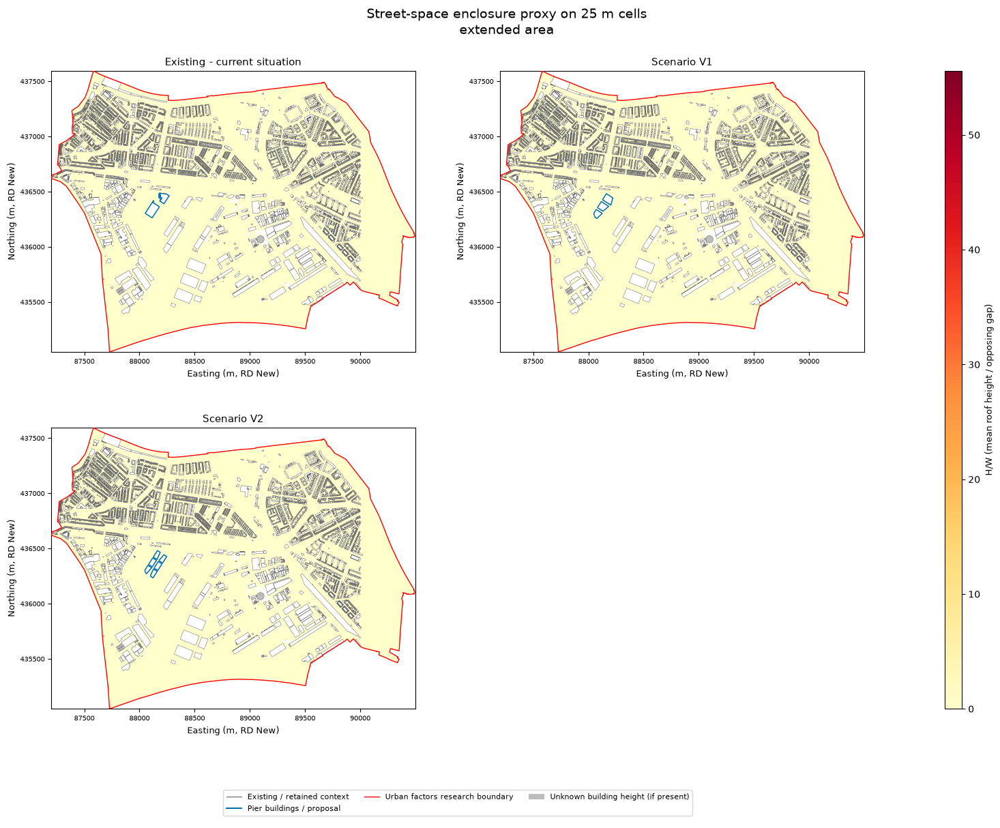

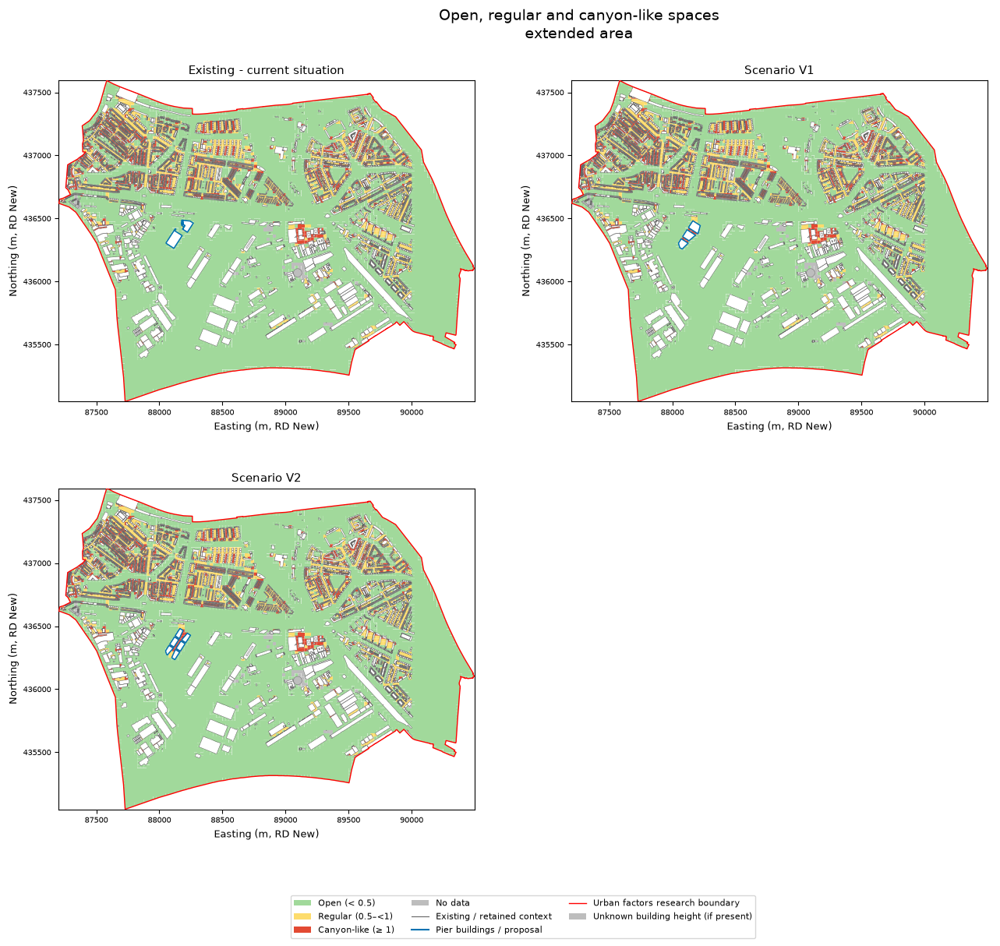

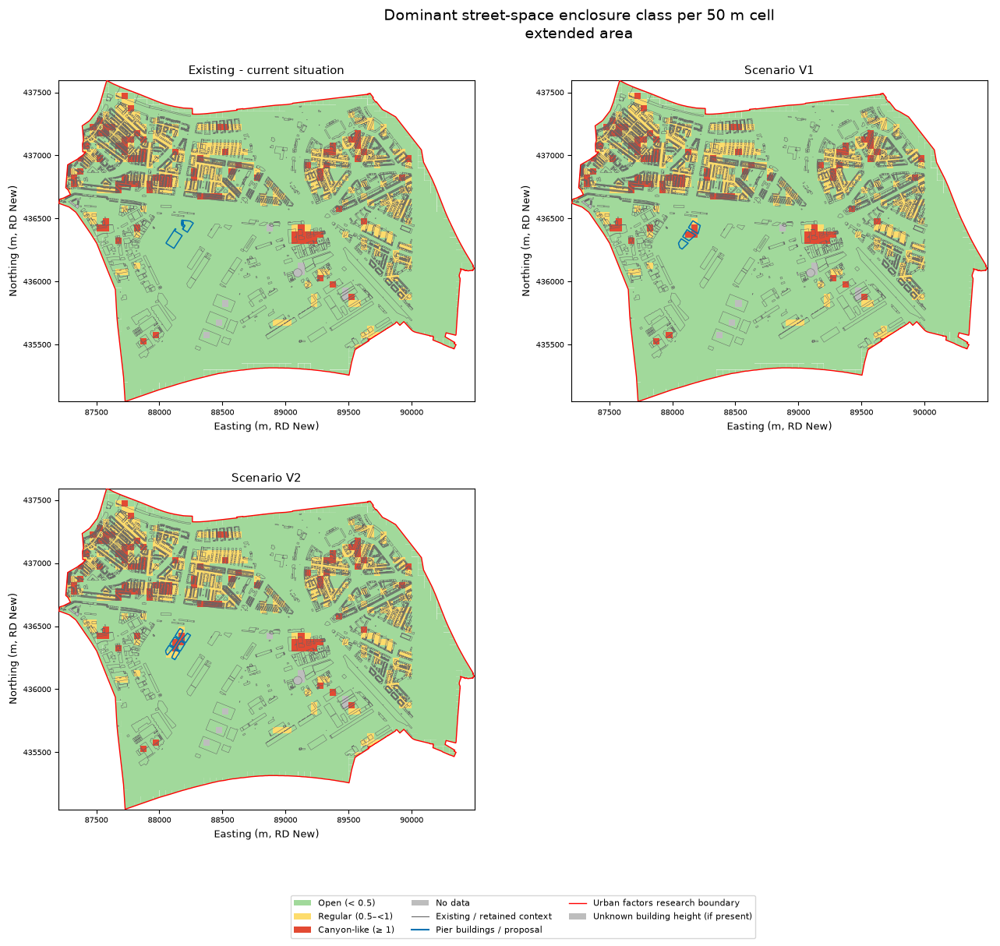

In [34]:

# Factor 3: directional enclosure over 25 m open-space cells.
from shapely.geometry import Point, LineString

def hw_building_model(buildings):
    rows = []
    for key, parts in buildings.groupby('building_key', sort=False):
        good = parts.loc[parts['height_valid']]
        weights = good.area
        h = float(np.average(good['h_mean'], weights=weights)) if len(good) and weights.sum() > 0 else np.nan
        rows.append({'building_key': key, 'h_mean': h, 'geometry': union_geometry(parts)})
    return gpd.GeoDataFrame(rows, geometry='geometry', crs=ANALYSIS_CRS)


def directional_hw(point, buildings):
    def first_hit(angle):
        endpoint = (point.x + HW_RADIUS_M * np.cos(angle), point.y + HW_RADIUS_M * np.sin(angle))
        ray = LineString([(point.x, point.y), endpoint])
        hits = []
        for idx in buildings.sindex.query(ray, predicate='intersects'):
            hit = buildings.geometry.iloc[idx].intersection(ray)
            if not hit.is_empty:
                distance = point.distance(hit)
                if distance > 1e-7:
                    hits.append((distance, int(idx)))
        return min(hits) if hits else None
    pairs, uncertain = [], False
    for angle in np.linspace(0, np.pi, HW_N_AXES, endpoint=False):
        left, right = first_hit(angle), first_hit(angle + np.pi)
        if left is None or right is None:
            continue
        width = left[0] + right[0]
        # Same building on both sides is a courtyard enclosure, retained and flagged.
        heights = buildings.iloc[[left[1], right[1]]]['h_mean'].to_numpy()
        if not np.isfinite(heights).all():
            uncertain = True
            continue
        if width >= HW_MIN_GAP_M:
            pairs.append((width, float(heights.mean()), left[1] == right[1]))
    if pairs:
        width, height, courtyard = min(pairs, key=lambda value: value[0])
        return height / width, width, height, 'courtyard_pair' if courtyard else 'opposing_buildings'
    if uncertain:
        return np.nan, np.nan, np.nan, 'unknown_height_pair'
    # Explicit finite-radius screening assumption, not a measured infinite street width.
    return 0.0, np.nan, np.nan, 'no_opposing_pair_within_radius'

hw_records = []
for name in SCENARIO_NAMES:
    b = V[name]['buildings']
    model = hw_building_model(b)
    fine = FINE_GRID.rename(columns={'grid_id': 'fine_id'}).copy()
    fine.geometry = fine.geometry.difference(union_geometry(b)).map(polygon_only)
    fine = fine.loc[fine.geometry.notna() & ~fine.geometry.is_empty].copy()
    # Explode disconnected street/courtyard pieces before assigning representative values.
    fine = fine.explode(index_parts=False).reset_index(drop=True)
    fine['sample_id'] = np.arange(len(fine))
    fine['open_area_m2'] = fine.area
    receptors = fine.geometry.representative_point()
    measured = [directional_hw(point, model) for point in receptors]
    fine[['H_W', 'width_m', 'mean_height_m', 'measurement_status']] = pd.DataFrame(measured, index=fine.index)
    fine['H_W'] = pd.to_numeric(fine['H_W'], errors='coerce')
    fine['H_W_class'] = classify(fine['H_W'], 'hw')
    fine['in_pier_window'] = fine.intersects(FOCUS_GEOM)
    fine['is_focus'] = fine['in_pier_window']
    fine['building_key'] = fine['sample_id'].astype(str)  # legacy table compatibility only
    coarse = aggregate_polygons(fine, GRID, 'H_W', 'H_W_class')
    RESULTS[name]['hw_fine'] = fine
    RESULTS[name]['hw_grid'] = coarse
    # Compatibility keys now contain polygons, never display lines or points.
    RESULTS[name]['hw_points'] = fine
    RESULTS[name]['hw_gaps'] = fine
    fine['lambda_p'] = density_at_points(gpd.GeoDataFrame(geometry=receptors, crs=ANALYSIS_CRS), RESULTS[name]['grid'])
    for scope, select in [('Extended area', np.ones(len(fine), dtype=bool)),
                          ('Pier display window', fine['in_pier_window'].to_numpy())]:
        part = fine.loc[select].dropna(subset=['H_W'])
        mean = float(np.average(part['H_W'], weights=part['open_area_m2'])) if len(part) else np.nan
        hw_records.append({'Scope': scope, 'Scenario': name, 'Open-space pieces': len(part),
                           'Open-space area (m2)': part['open_area_m2'].sum(), 'Area-weighted H/W': mean})
        store_summary(name, **{('Extended' if scope == 'Extended area' else 'Pier window') + ': mean street enclosure proxy (ratio)': mean})
    counts = fine.groupby('H_W_class')['open_area_m2'].sum().reindex(class_orders()['hw'], fill_value=0).to_frame('Open area (m2)')
    counts['Area share (%)'] = counts.iloc[:, 0] / max(fine['open_area_m2'].sum(), 1) * 100
    save_table(counts, 'hw_classes', name)
    save_table(fine.drop(columns='geometry'), 'hw_25m_open_space', name)
    save_table(coarse.drop(columns='geometry'), 'hw_50m_majority', name)
    save_table(fine['measurement_status'].value_counts().to_frame('Pieces'), 'hw_measurement_audit', name)
HW_TABLE = pd.DataFrame(hw_records).set_index(['Scope', 'Scenario'])
save_table(HW_TABLE, 'factor3_hw_summary')
display(HW_TABLE.round(3))
map_series({n: RESULTS[n]['hw_fine'] for n in SCENARIO_NAMES}, 'H_W',
           'Street-space enclosure proxy on 25 m cells', 'factor3_hw_continuous', 'H/W (mean roof height / opposing gap)', cmap='YlOrRd')
map_series({n: RESULTS[n]['hw_fine'] for n in SCENARIO_NAMES}, 'H_W_class',
           'Open, regular and canyon-like spaces', 'factor3_hw_classes', factor='hw')
map_series({n: RESULTS[n]['hw_grid'] for n in SCENARIO_NAMES}, 'H_W_class',
           'Dominant street-space enclosure class per 50 m cell', 'factor3_hw_50m_classes', factor='hw')


## Factor 4: Approximate building-only Sky View Factor

The existing radial horizon sampler is retained, using a mean-height roof surface and fixed 25 m fine-cell receptors. Ground comes from the DTM with the declared fallback outside valid coverage. Building-covered sample locations are excluded. Values are assigned to their fine-cell support and area-weighted onto the common 50 m grid for filled-polygon maps. Unsupported SVF cells are shown as No data, not open sky.

The finite-radius, 36-direction approximation omits vegetation, terrain along rays, bridges and facade detail. Internal points remain available for the existing common-support comparison tables, but map and Cesium outputs use polygons. Full 50 m fills are cartographic summaries and do not imply observation at every location inside each cell.


Existing: 7,558/9,408 valid open-ground points.
V1: 7,559/9,408 valid open-ground points.
V2: 7,556/9,408 valid open-ground points.
Existing: mean local density and NEAREST enclosure proxy by SVF class (descriptive association only)


,lambda_p,nearest_H_W_proxy
SVF_class,,
Low (< 0.3),0.418,2.058
Medium (0.3–<0.6),0.363,0.737
High (≥ 0.6),0.104,0.114


V1: mean local density and NEAREST enclosure proxy by SVF class (descriptive association only)


,lambda_p,nearest_H_W_proxy
SVF_class,,
Low (< 0.3),0.418,2.062
Medium (0.3–<0.6),0.363,0.745
High (≥ 0.6),0.103,0.114


V2: mean local density and NEAREST enclosure proxy by SVF class (descriptive association only)


,lambda_p,nearest_H_W_proxy
SVF_class,,
Low (< 0.3),0.414,2.143
Medium (0.3–<0.6),0.365,0.745
High (≥ 0.6),0.103,0.115


Headline means use identical open-ground locations in every scenario; adding V3/V4 may change this common sample set.
Pier-window results are not limited to land: water points remain unless separately masked.
Finite-radius, 36-direction building-only approximation; not full UMEP SVF or thermal-comfort modelling.


,,Valid points (own open space),Mean SVF (own open space),Common open points (ALL scenarios),Mean SVF (common support),Median SVF (common support),Minimum SVF (common support),Low SVF share on common support (%)
Scope,Scenario,,,,,,,
Extended area,Existing,7558,0.8912,7542,0.8913,0.9845,0.0284,0.4110
Pier display window,Existing,120,0.9453,104,0.9649,0.9949,0.5417,0.0000
Extended area,V1,7559,0.8902,7542,0.8907,0.9841,0.0284,0.4243
Pier display window,V1,121,0.8880,104,0.9212,0.9923,0.2468,0.9615
Extended area,V2,7556,0.8896,7542,0.8904,0.9837,0.0284,0.4243
Pier display window,V2,118,0.8485,104,0.8953,0.9601,0.1802,0.9615


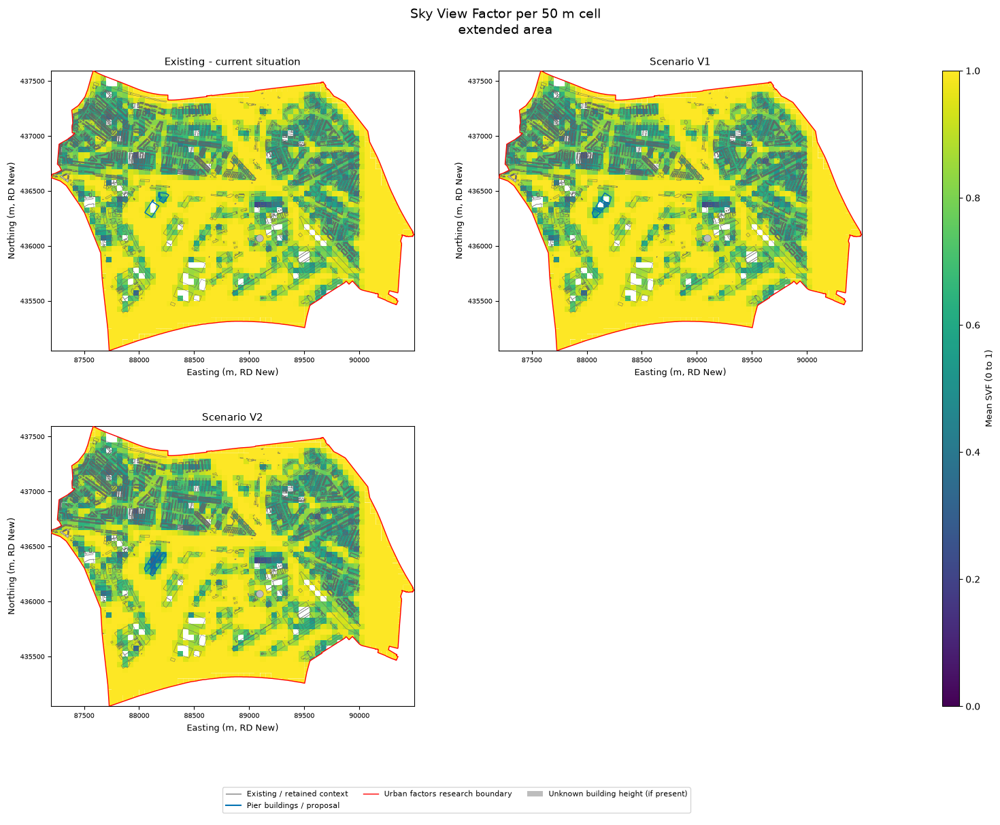

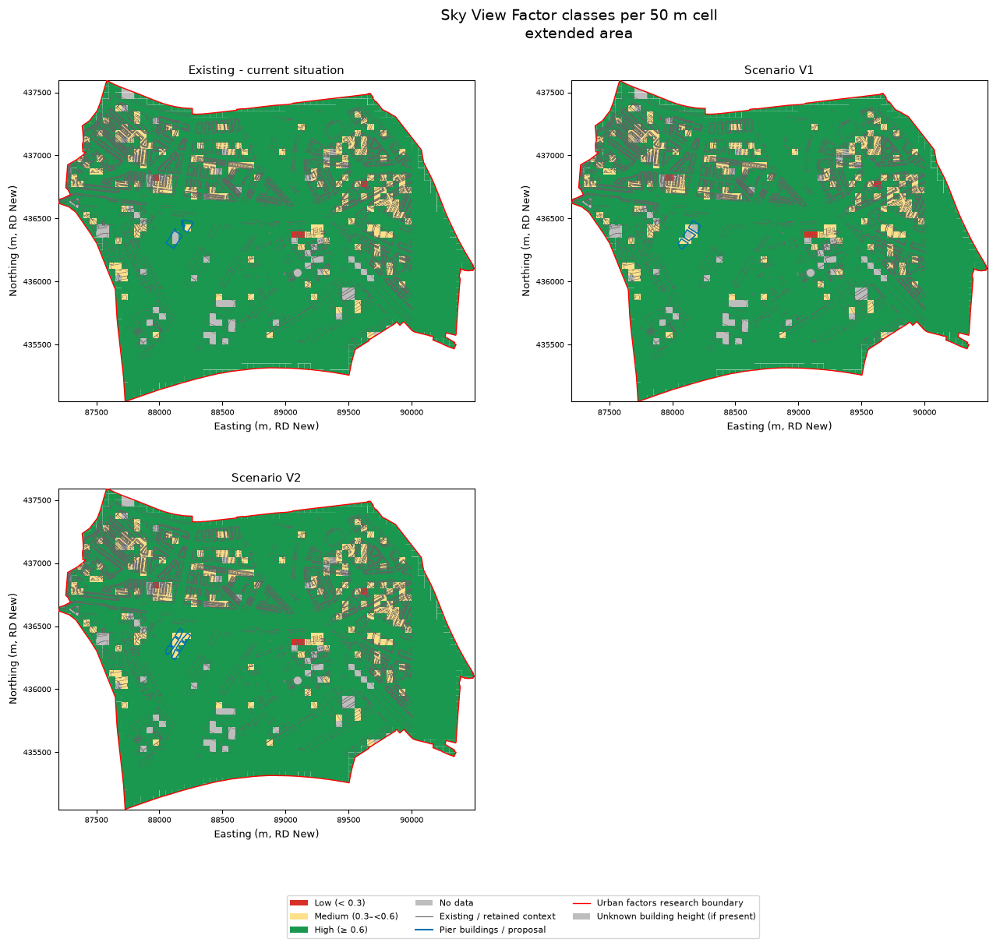

Factor 4 complete. Continue with Factor 5.


In [35]:
# Factor 4 - Approximate building-only Sky View Factor
# Roofs are absolute NAP elevations; receptor ground comes from DTM or the declared fallback.
# Terrain along rays / vegetation / bridges / facade details are NOT modelled.
# Distances are in metres, independently converted using X and Y pixel sizes.

def radial_svf(points, roof_surface):
    inv = ~SURF_TRANSFORM
    sample_x = points.geometry.x.to_numpy()
    sample_y = points.geometry.y.to_numpy()
    ground = points['ground_nap_m'].to_numpy() + SVF_EYE_HEIGHT_M
    angle = np.linspace(0, 2 * np.pi, SVF_N_ANGLES, endpoint=False)
    sin_a, cos_a = np.sin(angle), np.cos(angle)
    distances = np.arange(min(SURF_RES_X, SURF_RES_Y), SVF_MAX_DIST_M, min(SURF_RES_X, SURF_RES_Y))
    distances = np.unique(np.append(distances, SVF_MAX_DIST_M))
    out = np.full(len(points), np.nan)
    coverage = np.ones(len(points), dtype=bool)
    for start in range(0, len(points), SVF_CHUNK_SIZE):
        end = min(start + SVF_CHUNK_SIZE, len(points))
        horizon_slope = np.zeros((end - start, SVF_N_ANGLES))
        complete = np.ones(end - start, dtype=bool)
        x0, y0, z0 = sample_x[start:end], sample_y[start:end], ground[start:end]
        for distance in distances:
            x = x0[:, None] + distance * cos_a[None, :]
            y = y0[:, None] + distance * sin_a[None, :]
            col = np.floor(inv.a * x + inv.c).astype(np.int64)
            row = np.floor(inv.e * y + inv.f).astype(np.int64)
            inside = (row >= 0) & (row < roof_surface.shape[0]) & (col >= 0) & (col < roof_surface.shape[1])
            complete &= inside.all(axis=1)
            roof = np.full(row.shape, np.nan)
            roof[inside] = roof_surface[row[inside], col[inside]]
            rise = np.maximum(np.nan_to_num(roof - z0[:, None], nan=0.0), 0)
            horizon_slope = np.maximum(horizon_slope, rise / distance)
        values = (1.0 / (1.0 + horizon_slope ** 2)).mean(axis=1)
        values[~complete] = np.nan
        out[start:end] = values
        coverage[start:end] = complete
    return out, coverage

for name in SCENARIO_NAMES:
    if 'hw_points' not in RESULTS[name]:
        raise RuntimeError('Run Factor 3 before Factor 4.')
    p = SVF_POINTS.copy()
    b = V[name]['buildings']
    p['unknown_height_footprint'] = shapely.covers(union_geometry(b.loc[~b['height_valid']]), p.geometry.to_numpy())
    # covers includes walls/footprint edges, unlike within().
    p['in_building'] = shapely.covers(union_geometry(b), p.geometry.to_numpy())
    eligible = ~p['in_building'] & ~p['unknown_height_footprint']
    p['SVF'] = np.nan
    p['full_grid_radius'] = False
    indices = p.index[eligible]
    values, complete = radial_svf(p.loc[indices], V[name]['roof_surface'])
    p.loc[indices, 'SVF'] = values
    p.loc[indices, 'full_grid_radius'] = complete
    p['SVF_class'] = classify(p['SVF'], 'svf')
    RESULTS[name]['svf_points'] = p
    print(f'{name}: {int(p.SVF.notna().sum()):,}/{len(p):,} valid open-ground points.')

# Same coordinates AND open ground in every scenario. This is the headline comparison support.
COMMON_OPEN_MASK = np.logical_and.reduce([
    RESULTS[n]['svf_points']['SVF'].notna().to_numpy() for n in SCENARIO_NAMES
])
svf_records = []
for name in SCENARIO_NAMES:
    p = RESULTS[name]['svf_points']
    p['common_open_all_scenarios'] = COMMON_OPEN_MASK
    p['lambda_p'] = density_at_points(p, RESULTS[name]['grid'])
    # Attach nearest enclosure point for the inherited cross-indicator table only.
    known_hw = RESULTS[name]['hw_points'].dropna(subset=['H_W'])
    if len(known_hw):
        left = p[['point_id', 'geometry']]
        joined = gpd.sjoin_nearest(left, known_hw[['H_W', 'geometry']], how='left', distance_col='nearest_hw_distance_m')
        joined = joined.groupby('point_id')[['H_W', 'nearest_hw_distance_m']].mean()
        p['nearest_H_W_proxy'] = p['point_id'].map(joined['H_W'])
        p['nearest_hw_distance_m'] = p['point_id'].map(joined['nearest_hw_distance_m'])
    else:
        p['nearest_H_W_proxy'] = np.nan
        p['nearest_hw_distance_m'] = np.nan
    context_table = p.loc[p.SVF.notna()].groupby('SVF_class')[['lambda_p', 'nearest_H_W_proxy']].mean().reindex(class_orders()['svf'])
    save_table(context_table, 'density_and_nearest_hw_by_svf_class', name)
    for scope, select in [('Extended area', np.ones(len(p), dtype=bool)),
                          ('Pier display window', p['in_pier_window'].to_numpy())]:
        all_open = p.loc[select, 'SVF'].dropna()
        common = p.loc[select & COMMON_OPEN_MASK, 'SVF'].dropna()
        svf_records.append({
            'Scope': scope, 'Scenario': name, 'Valid points (own open space)': len(all_open),
            'Mean SVF (own open space)': all_open.mean(), 'Common open points (ALL scenarios)': len(common),
            'Mean SVF (common support)': common.mean(), 'Median SVF (common support)': common.median(),
            'Minimum SVF (common support)': common.min(),
            'Low SVF share on common support (%)': 100 * (common < SVF_CLASSES[0]).mean() if len(common) else np.nan,
        })
        prefix = 'Extended' if scope == 'Extended area' else 'Pier window'
        store_summary(name, **{f'{prefix}: mean SVF common support (ratio)': float(common.mean())})
    if not (COMMON_OPEN_MASK & p['in_pier_window'].to_numpy()).any():
        warnings.warn('No common open SVF points in the pier window. Reduce SVF_SPACING_M; no mean is invented.')
    save_table(p.drop(columns='geometry'), 'svf_per_point', name)
    counts = p.loc[p.SVF.notna(), 'SVF_class'].value_counts().reindex(class_orders()['svf'], fill_value=0).to_frame('Open-ground points')
    counts['Percentage (%)'] = counts.iloc[:, 0] / max(p.SVF.notna().sum(), 1) * 100
    save_table(counts, 'svf_classes', name)
    print(f'{name}: mean local density and NEAREST enclosure proxy by SVF class (descriptive association only)')
    display(context_table.round(3))
SVF_TABLE = pd.DataFrame(svf_records).set_index(['Scope', 'Scenario'])
save_table(SVF_TABLE, 'factor4_svf_summary')
print('Headline means use identical open-ground locations in every scenario; adding V3/V4 may change this common sample set.')
print('Pier-window results are not limited to land: water points remain unless separately masked.')
print(f'Finite-radius, {SVF_N_ANGLES}-direction building-only approximation; not full UMEP SVF or thermal-comfort modelling.')
display(SVF_TABLE.round(4))

for name in SCENARIO_NAMES:
    p = RESULTS[name]['svf_points']
    fine = FINE_GRID.rename(columns={'grid_id': 'fine_id'}).copy()
    fine['SVF'] = fine['fine_id'].map(p.set_index('fine_id')['SVF'])
    fine['SVF_class'] = classify(fine['SVF'], 'svf')
    RESULTS[name]['svf_fine'] = fine
    coarse = aggregate_polygons(fine, GRID, 'SVF')
    coarse['SVF_class'] = classify(coarse['SVF'], 'svf')
    RESULTS[name]['svf_grid'] = coarse
    save_table(coarse.drop(columns='geometry'), 'svf_50m_cells', name)
map_series({n: RESULTS[n]['svf_grid'] for n in SCENARIO_NAMES}, 'SVF',
           'Sky View Factor per 50 m cell', 'factor4_svf_continuous', 'Mean SVF (0 to 1)', limits=(0, 1))
map_series({n: RESULTS[n]['svf_grid'] for n in SCENARIO_NAMES}, 'SVF_class',
           'Sky View Factor classes per 50 m cell', 'factor4_svf_classes', factor='svf')
print('Factor 4 complete. Continue with Factor 5.')


## Factor 5: Heat and ventilation screening risk

Separate factor using the original Task 5 formula: the equal-weight mean of normalized density, normalized H/W and inverted normalized SVF. The input geometry changes as requested, while the combination formula is retained.

,lambda_p,H_W_mean,SVF_mean,R
count,2404.000,2404.000,2404.000,2404.000
mean,0.191,0.249,0.869,0.136
std,0.229,0.410,0.155,0.149
min,0.000,0.000,0.203,0.000
25%,0.000,0.000,0.763,0.000
50%,0.101,0.041,0.941,0.078
75%,0.341,0.398,1.000,0.259
max,1.000,4.843,1.000,0.843


,lambda_p,H_W_mean,SVF_mean,R
count,2404.000,2404.000,2404.000,2404.000
mean,0.191,0.252,0.868,0.136
std,0.229,0.413,0.156,0.149
min,0.000,0.000,0.203,0.000
25%,0.000,0.000,0.762,0.000
50%,0.098,0.042,0.940,0.080
75%,0.342,0.406,1.000,0.261
max,1.000,4.843,1.000,0.843


,lambda_p,H_W_mean,SVF_mean,R
count,2404.000,2404.000,2404.000,2404.000
mean,0.192,0.254,0.867,0.137
std,0.228,0.415,0.157,0.150
min,0.000,0.000,0.203,0.000
25%,0.000,0.000,0.759,0.000
50%,0.102,0.045,0.938,0.081
75%,0.343,0.410,1.000,0.263
max,1.000,4.843,1.000,0.843


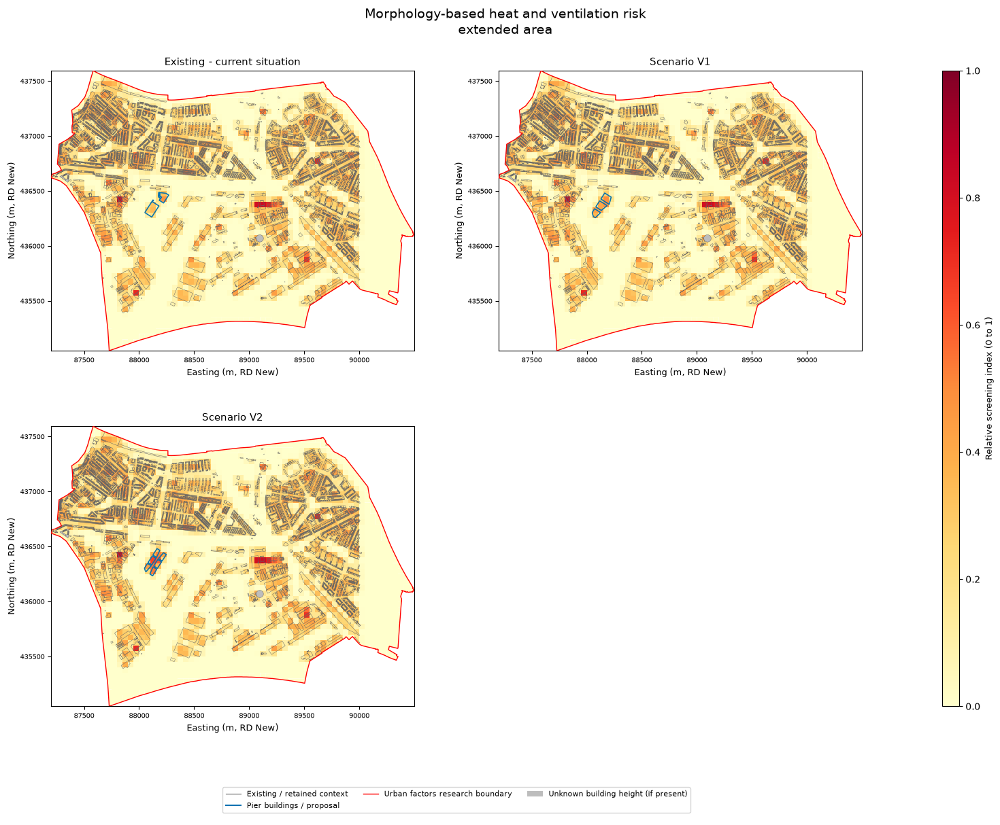

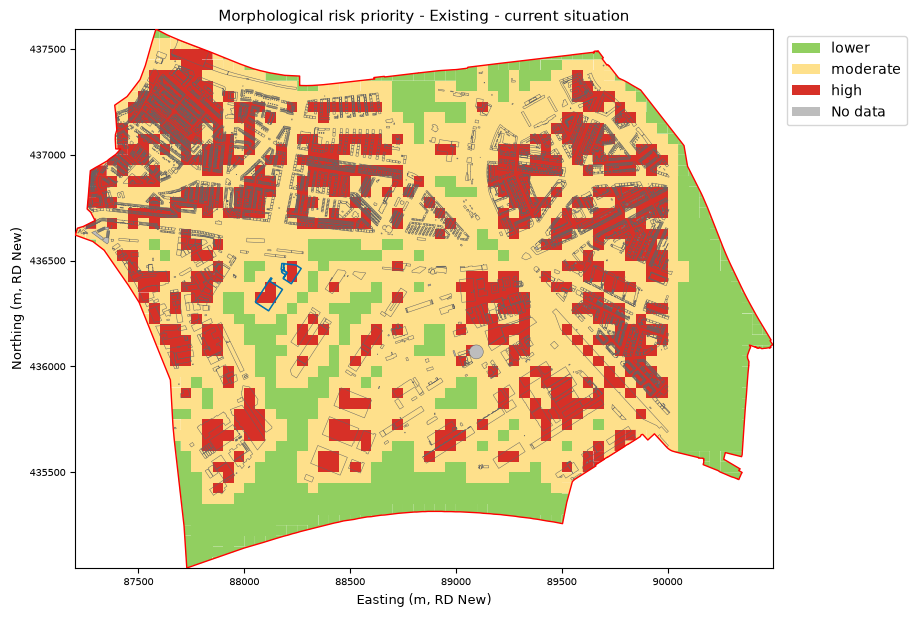

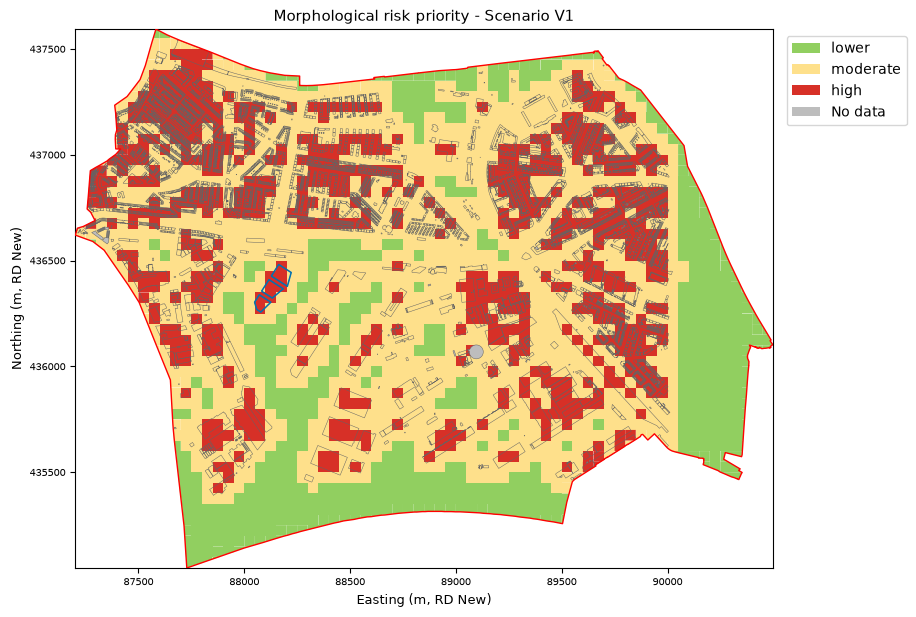

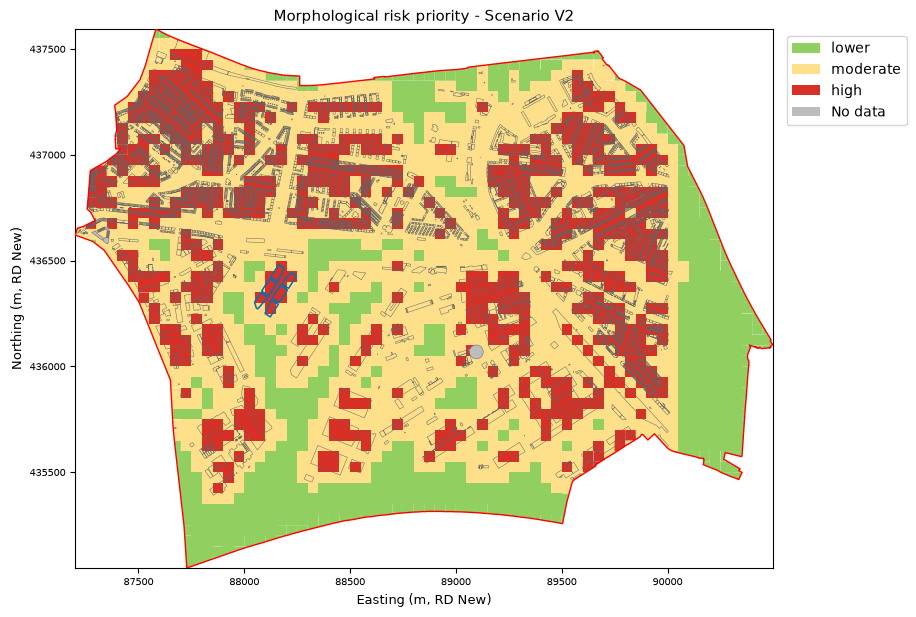

In [36]:
# Factor 5: original Task 5 morphology-based heat and ventilation risk.
# Each scenario uses the original within-scenario min-max convention.
for name in SCENARIO_NAMES:
    grid = RESULTS[name]['grid'].copy()
    hw = RESULTS[name]['hw_grid'].set_index('grid_id')['H_W']
    svf = RESULTS[name]['svf_grid'].set_index('grid_id')['SVF']
    grid['H_W_mean'] = grid['grid_id'].map(hw)
    grid['SVF_mean'] = grid['grid_id'].map(svf)
    grid['H_W_imputed'] = grid['H_W_mean'].isna()
    grid['SVF_imputed'] = grid['SVF_mean'].isna()
    grid['H_W_mean'] = grid['H_W_mean'].fillna(0)
    median_svf = grid['SVF_mean'].median()
    if not np.isfinite(median_svf):
        raise ValueError(f'{name}: no valid SVF cells. Risk cannot be calculated without SVF.')
    grid['SVF_mean'] = grid['SVF_mean'].fillna(median_svf)
    grid['lambda_p_norm'] = safe_scale(grid['lambda_p'])
    grid['H_W_norm'] = safe_scale(grid['H_W_mean'])
    grid['SVF_norm'] = safe_scale(grid['SVF_mean'])
    grid['SVF_risk'] = 1 - grid['SVF_norm']
    grid['R'] = (grid['lambda_p_norm'] + grid['H_W_norm'] + grid['SVF_risk']) / 3
    grid['heat_vent_risk'] = grid['R']
    grid['priority_old'] = priority_classes(grid['R'])
    RESULTS[name]['risk_grid'] = grid
    save_table(grid.drop(columns='geometry'), 'factor5_heat_ventilation_risk', name)
    influence = grid[['lambda_p_norm', 'H_W_norm', 'SVF_risk']].std().to_frame('Standard deviation')
    influence['Correlation with R'] = grid[['lambda_p_norm', 'H_W_norm', 'SVF_risk']].corrwith(grid['R'])
    save_table(influence, 'factor5_indicator_influence', name)
    store_summary(name, **{'Extended: mean heat and ventilation risk (ratio)': grid['R'].mean(),
                           'Extended: imputed SVF cells (count)': int(grid['SVF_imputed'].sum())})
    display(grid[['lambda_p', 'H_W_mean', 'SVF_mean', 'R']].describe().round(3))
map_series({n: RESULTS[n]['risk_grid'] for n in SCENARIO_NAMES}, 'R',
           'Morphology-based heat and ventilation risk', 'factor5_heat_ventilation_risk',
           'Relative screening index (0 to 1)', cmap='YlOrRd', limits=(0, 1))
categorical_maps({n: RESULTS[n]['risk_grid'] for n in SCENARIO_NAMES}, 'priority_old',
                 'Morphological risk priority', 'factor5_priority',
                 ['lower', 'moderate', 'high'], ['#91cf60', '#fee08b', '#d73027'])

## Factor 6: Age vulnerability and adjusted risk

Select complete CBS buurten overlapping the UF boundary, compute weighted age vulnerability, allocate baseline population via building area, and combine hazard and vulnerability. Include priority transitions and sensitivity checks. Allocation remains provisional until complete buurt footprint coverage is confirmed.

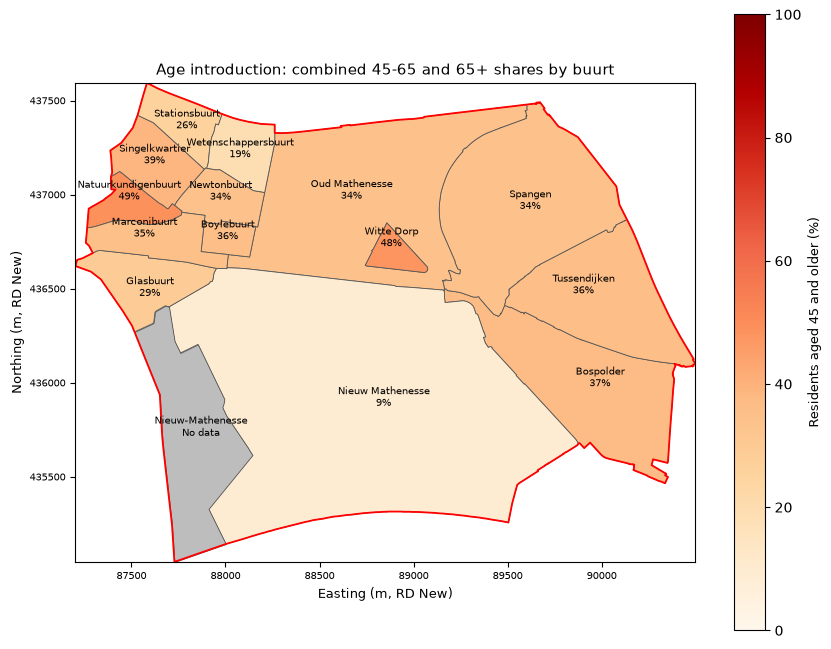

C:\Users\micha\AppData\Local\Temp\ipykernel_33496\3257655932.py:333: UserWarning: PROVISIONAL population allocation: complete building coverage of full buurten has not been confirmed. A UF-clipped building layer biases population counts. Set a complete footprint source and confirm coverage before reporting final counts.
  warnings.warn(
C:\Users\micha\AppData\Local\Temp\ipykernel_33496\3257655932.py:343: UserWarning: Population uses ALL building footprints as a proxy, not verified residential footprints. Industrial buildings can receive residents in this model.
  warnings.warn(


priority_new,lower,moderate,high
priority_old,,,
lower,601,0,0
moderate,0,1126,76
high,0,76,525


priority_new,lower,moderate,high
priority_old,,,
lower,601,0,0
moderate,0,1127,75
high,0,75,526


priority_new,lower,moderate,high
priority_old,,,
lower,601,0,0
moderate,0,1127,75
high,0,75,526


,Scenario,alpha,45-65 weight,Changed cells vs alpha 1,High cells
0,Existing,0.5,0.5,72,601
1,Existing,1.0,0.5,0,601
2,Existing,2.0,0.5,70,601
3,Existing,1.0,0.3,2,601
4,V1,0.5,0.5,68,601
5,V1,1.0,0.5,0,601
6,V1,2.0,0.5,72,601
7,V1,1.0,0.3,4,601
8,V2,0.5,0.5,66,601
9,V2,1.0,0.5,0,601


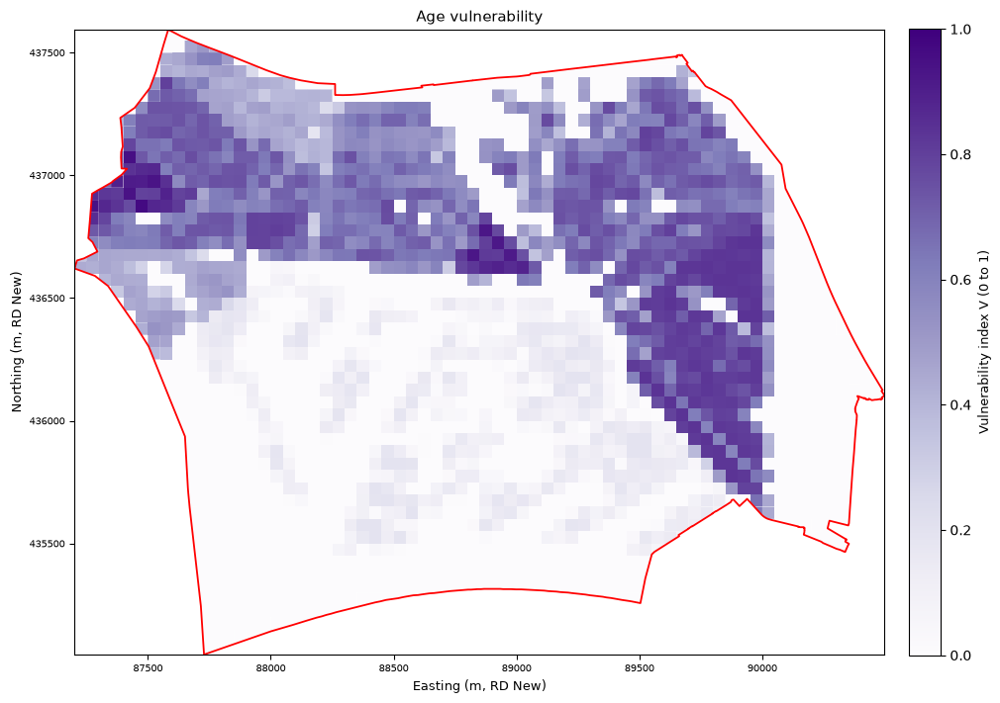

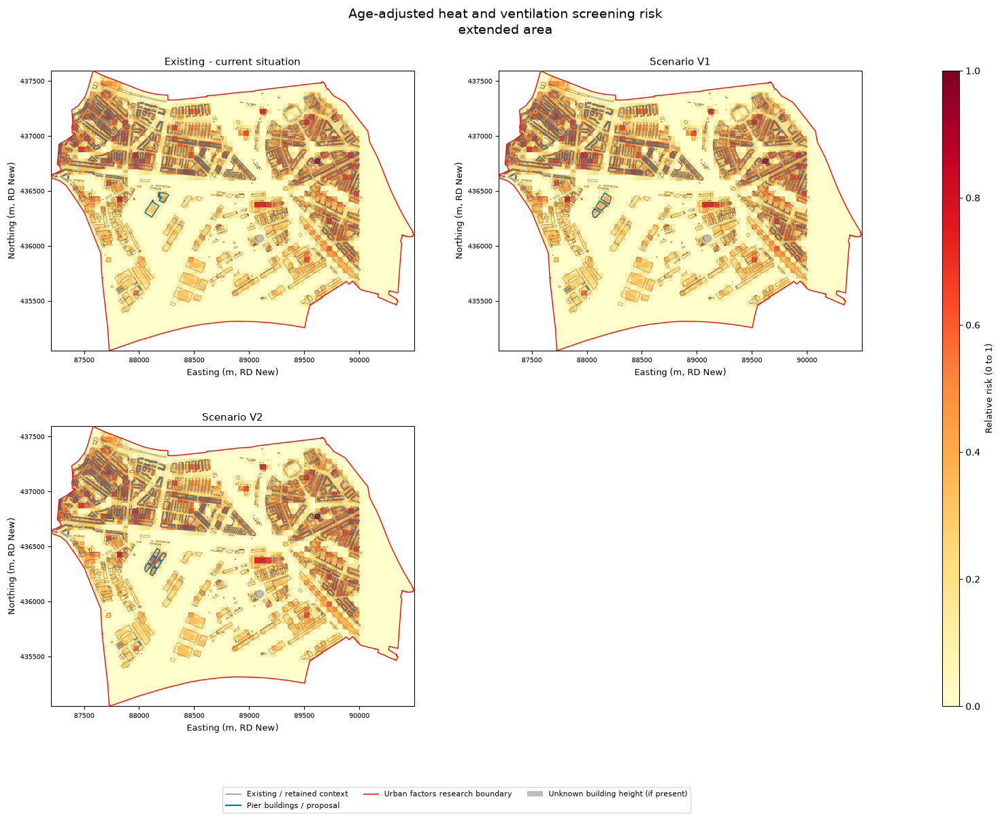

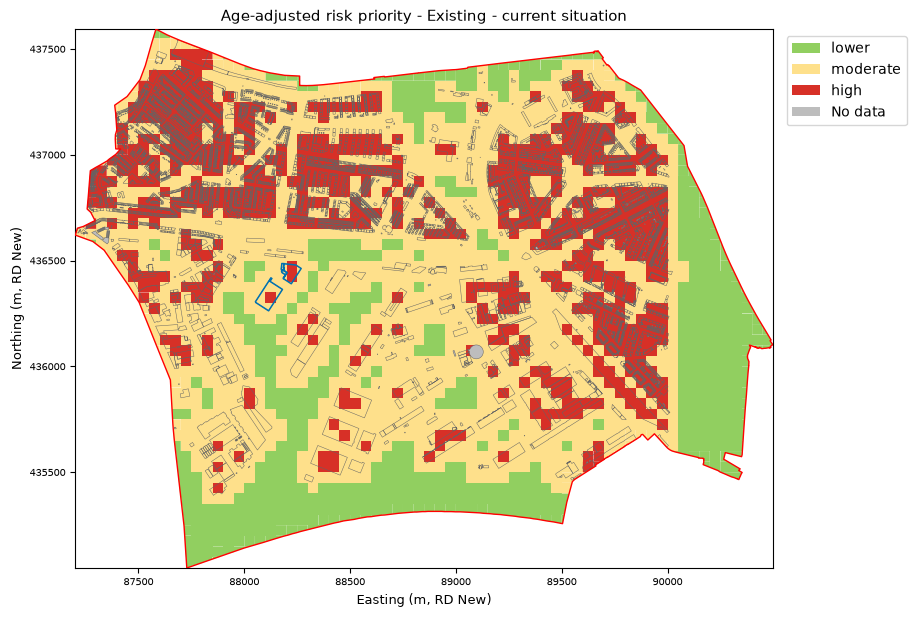

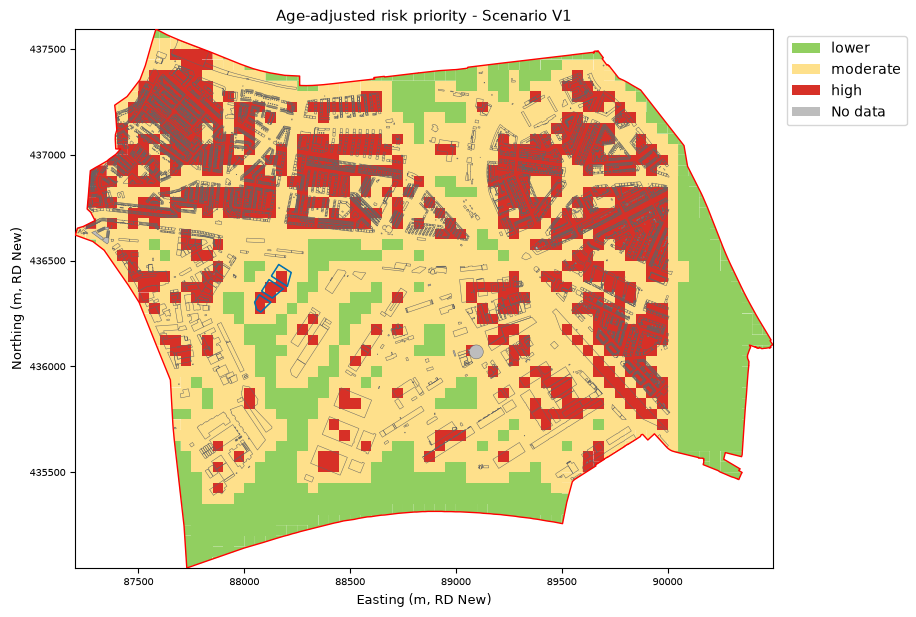

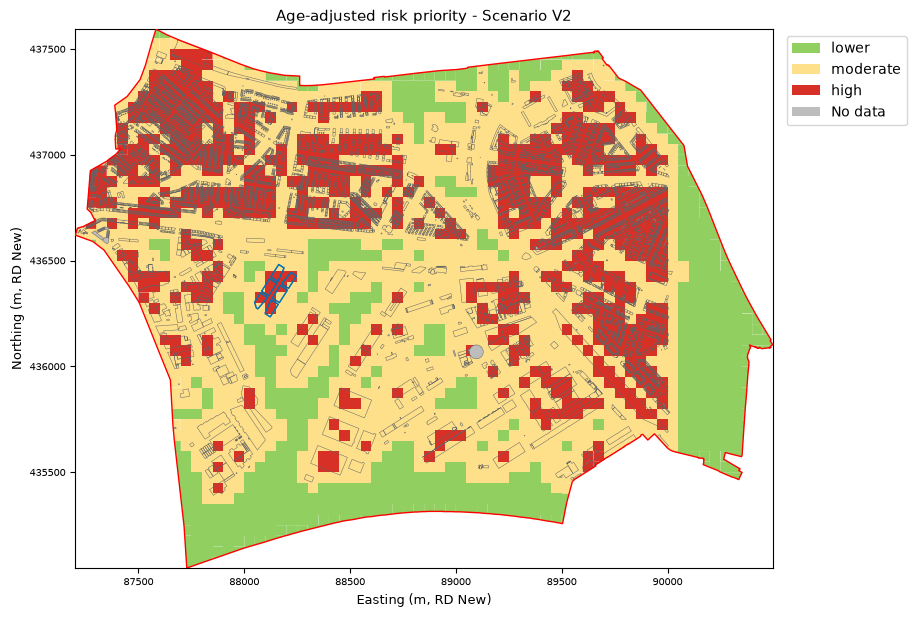

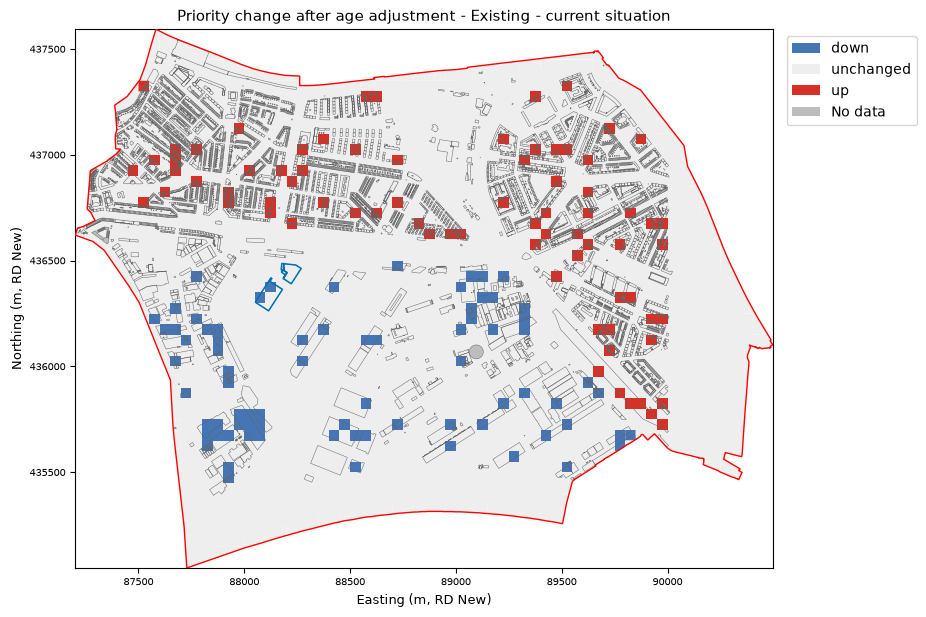

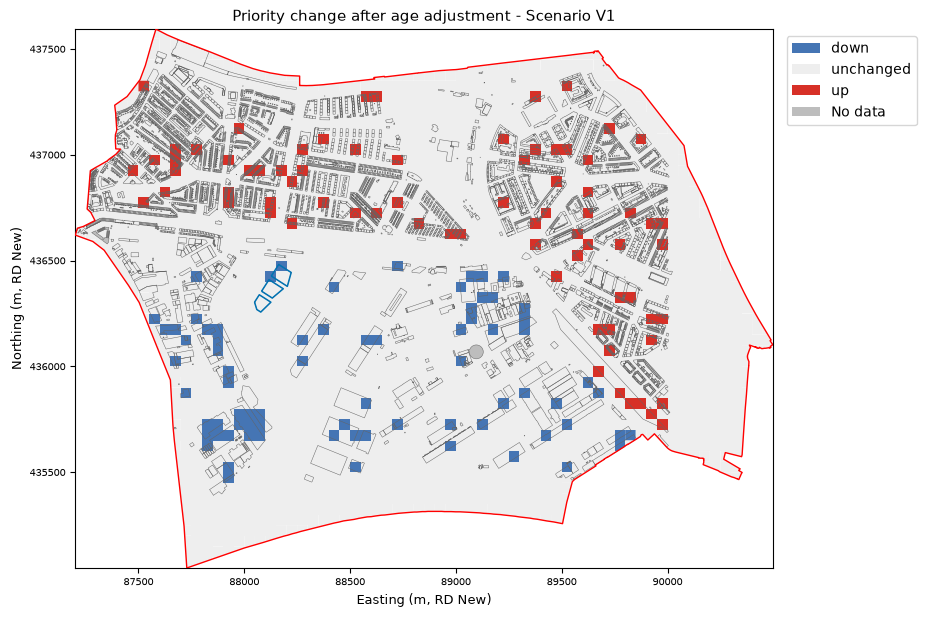

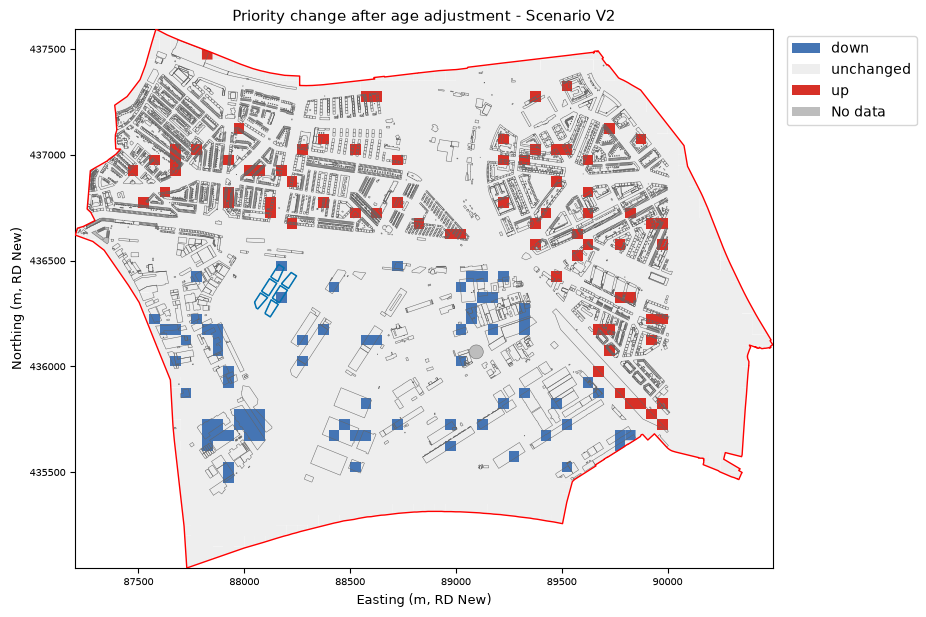

Factor 6 complete. The shared vulnerability map uses one title: Age vulnerability.


In [37]:
# Factor 6: age vulnerability and age-adjusted screening risk.

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable


def cbs_column(frame, *candidates):
    def key(value):
        return re.sub(
            r'[^a-z0-9]',
            '',
            str(value).casefold()
        )

    names = {
        key(c): c
        for c in frame.columns
    }

    for candidate in candidates:
        if key(candidate) in names:
            return names[key(candidate)]

    raise KeyError(
        f'CBS field not found: {candidates}. '
        f'Available: {list(frame.columns)}'
    )


# ------------------------------------------------------------
# 1. Prepare CBS buurt data
# ------------------------------------------------------------

buurt = read_vector(
    CBS_FILE,
    CBS_LAYER,
    'CBS buurten'
)

for field in buurt.select_dtypes(
    include=np.number
).columns:
    buurt.loc[
        buurt[field] == -99997,
        field
    ] = np.nan

aliases = {
    'buurtcode': ('buurtcode',),
    'buurtnaam': ('buurtnaam',),
    'inhabitants': ('aantalInwoners',),
    'p0': ('percentagePersonen0Tot15Jaar',),
    'p45': ('percentagePersonen45Tot65Jaar',),
    'p65': (
        'percentagePersonen65JaarEnOuder',
        'percentagePersonen65EnOuder'
    )
}

for dest, choices in aliases.items():
    source = cbs_column(buurt, *choices)

    buurt[dest] = (
        buurt[source]
        if dest in ('buurtcode', 'buurtnaam')
        else numeric(buurt[source])
    )

for field in [
    'inhabitants',
    'p0',
    'p45',
    'p65'
]:
    buurt.loc[
        buurt[field] < 0,
        field
    ] = np.nan

for field in ['p0', 'p45', 'p65']:
    buurt.loc[
        buurt[field] > 100,
        field
    ] = np.nan

# Keep complete buurt geometries for allocation denominators.
# Select buurten based on their overlap with the UF boundary.
buurt['overlap_m2'] = (
    buurt.geometry.intersection(STUDY_GEOM).area
)

buurt = buurt.loc[
    buurt['overlap_m2'] > 100
].copy().reset_index(drop=True)

if buurt.empty:
    raise ValueError(
        'No CBS buurten overlap the UF boundary '
        'by more than 100 m2.'
    )

if buurt['buurtcode'].duplicated().any():
    raise ValueError(
        'Duplicate buurtcodes. Resolve duplicate '
        'records before population allocation.'
    )


# ------------------------------------------------------------
# 2. Check age shares and calculate buurt vulnerability
# ------------------------------------------------------------

try:
    p15 = cbs_column(
        buurt,
        'percentagePersonen15Tot25Jaar'
    )
    p25 = cbs_column(
        buurt,
        'percentagePersonen25Tot45Jaar'
    )

    buurt['age_share_sum'] = (
        buurt['p0']
        + buurt['p45']
        + buurt['p65']
        + numeric(buurt[p15]).where(
            numeric(buurt[p15]) >= 0
        )
        + numeric(buurt[p25]).where(
            numeric(buurt[p25]) >= 0
        )
    )

    if (
        buurt['age_share_sum']
        .sub(100)
        .abs()
        .gt(5)
        .any()
    ):
        warnings.warn(
            'Some five-group age shares differ from '
            '100 by more than 5 percentage points.'
        )

except KeyError:
    warnings.warn(
        'Optional 15-25 / 25-45 fields absent: '
        'five-group age-share check unavailable.'
    )

buurt['percentage_45plus'] = (
    buurt['p45'] + buurt['p65']
)

buurt['V_raw'] = (
    buurt['p65']
    + 0.5 * buurt['p45']
    + 0.3 * buurt['p0']
)

buurt['V_share'] = safe_scale(
    buurt['V_raw']
)

buurt['vuln_people'] = (
    buurt['inhabitants']
    * buurt['V_raw']
    / 100
)

buurt['age_data_missing'] = (
    buurt[
        ['p0', 'p45', 'p65', 'inhabitants']
    ]
    .isna()
    .any(axis=1)
)


# ------------------------------------------------------------
# 3. Introduction map: combined 45-65 and 65+ shares
# ------------------------------------------------------------

# This map uses the unweighted age-share sum, not V_raw.
intro_buurt = buurt.copy()

intro_buurt.geometry = (
    intro_buurt.geometry.intersection(STUDY_GEOM)
)

fig, ax = plt.subplots(figsize=(10, 8))

intro_buurt.plot(
    column='percentage_45plus',
    ax=ax,
    cmap='OrRd',
    vmin=0,
    vmax=100,
    edgecolor='#555555',
    linewidth=0.6,
    legend=True,
    legend_kwds={
        'label': 'Residents aged 45 and older (%)'
    },
    missing_kwds={
        'color': '#bdbdbd',
        'label': 'Suppressed or missing'
    }
)

for _, row in intro_buurt.iterrows():
    p = row.geometry.representative_point()

    label = row['buurtnaam'] + (
        '\nNo data'
        if pd.isna(row['percentage_45plus'])
        else f"\n{row['percentage_45plus']:.0f}%"
    )

    ax.annotate(
        label,
        (p.x, p.y),
        ha='center',
        fontsize=7
    )

STUDY_AREA.boundary.plot(
    ax=ax,
    color='red',
    linewidth=1.3
)

format_axes(
    ax,
    'Age introduction: combined 45-65 and 65+ shares by buurt',
    EXTENDED_BOUNDS
)

show_fig(
    fig,
    'factor6_age_45plus_introduction'
)

save_table(
    buurt.drop(columns='geometry'),
    'factor6_buurt_age_scores',
    'demographics'
)


# ------------------------------------------------------------
# 4. Prepare building-area population allocation
# ------------------------------------------------------------

# Use source buildings before model-area filtering or clipping.
if (
    Path(POPULATION_BUILDINGS_FILE)
    == Path(CONTEXT_BUILDINGS_FILE)
    and POPULATION_BUILDINGS_LAYER
    == CONTEXT_BUILDINGS_LAYER
):
    population_buildings = RAW_CONTEXT_ALL.copy()

else:
    population_buildings = read_vector(
        POPULATION_BUILDINGS_FILE,
        POPULATION_BUILDINGS_LAYER,
        'Population allocation buildings'
    )

if POPULATION_RESIDENTIAL_ONLY:
    raw_id = column(
        population_buildings,
        CONTEXT_ID_COLUMN,
        required=True
    )

    residential_ids = set(
        context.loc[
            context['use_en'].str.contains(
                'Residential',
                case=False,
                na=False
            ),
            'bag_id'
        ]
    )

    raw_use = (
        column(
            population_buildings,
            'gebruiksdoel'
        )
        or column(
            population_buildings,
            USE_COLUMN
        )
    )

    known_residential = (
        population_buildings[raw_id]
        .map(normalize_id)
        .isin(residential_ids)
    )

    if raw_use:
        known_residential |= (
            population_buildings[raw_use]
            .map(translate_use)
            .str.contains(
                'Residential',
                case=False,
                na=False
            )
        )

    population_buildings = (
        population_buildings.loc[
            known_residential
        ].copy()
    )

    if population_buildings.empty:
        raise ValueError(
            'No residential buildings identified. '
            'Supply complete residential-use data '
            'or use the all-footprint proxy.'
        )

if not POPULATION_COVERAGE_CONFIRMED:
    warnings.warn(
        'PROVISIONAL population allocation: complete '
        'building coverage of full buurten has not been '
        'confirmed. A UF-clipped building layer biases '
        'population counts. Set a complete footprint '
        'source and confirm coverage before reporting '
        'final counts.'
    )

if not POPULATION_RESIDENTIAL_ONLY:
    warnings.warn(
        'Population uses ALL building footprints as a '
        'proxy, not verified residential footprints. '
        'Industrial buildings can receive residents '
        'in this model.'
    )

# Union roof parts and duplicate overlaps before allocation.
allocation_union = union_geometry(
    population_buildings.loc[
        population_buildings.intersects(
            union_geometry(buurt)
        )
    ]
)

allocation = (
    gpd.GeoDataFrame(
        geometry=[allocation_union],
        crs=ANALYSIS_CRS
    )
    .explode(index_parts=False)
    .reset_index(drop=True)
)

if allocation.empty or allocation_union.is_empty:
    raise ValueError(
        'No allocation footprints overlap '
        'the selected buurten.'
    )

b_b = gpd.overlay(
    allocation[['geometry']],
    buurt[['buurtcode', 'geometry']],
    how='intersection',
    keep_geom_type=True
)

b_b['a_b'] = b_b.area

area_totals = (
    b_b.groupby('buurtcode')['a_b'].sum()
)

b_b['a_buurt_total'] = (
    b_b['buurtcode'].map(area_totals)
)

pieces = gpd.overlay(
    b_b,
    GRID[['grid_id', 'geometry']],
    how='intersection',
    keep_geom_type=True
)

pieces['a'] = pieces.area

save_table(
    area_totals.to_frame(
        'Complete supplied building area (m2)'
    ),
    'population_allocation_denominators',
    'quality'
)


# ------------------------------------------------------------
# 5. Allocate vulnerability to the universal grid
# ------------------------------------------------------------

def allocate_vulnerability(weight45=0.5):
    scores = buurt.set_index(
        'buurtcode'
    ).copy()

    scores['raw'] = (
        scores['p65']
        + weight45 * scores['p45']
        + 0.3 * scores['p0']
    )

    scores['share'] = safe_scale(
        scores['raw']
    )

    scores['people'] = (
        scores['inhabitants']
        * scores['raw']
        / 100
    )

    work = pieces.copy()

    work['share'] = (
        work['buurtcode'].map(scores['share'])
    )

    work['people_piece'] = (
        work['buurtcode'].map(scores['people'])
        * work['a']
        / work['a_buurt_total']
    )

    valid = work.loc[
        work['share'].notna()
    ]

    weighted = (
        (valid['share'] * valid['a'])
        .groupby(valid['grid_id'])
        .sum()
    )

    denominator = (
        valid.groupby('grid_id')['a'].sum()
    )

    counts = (
        work.groupby('grid_id')['people_piece']
        .sum(min_count=1)
    )

    out = GRID.copy()

    out['V_share_cell'] = (
        out['grid_id'].map(
            weighted / denominator
        )
    )

    out['vuln_people_cell'] = (
        out['grid_id'].map(counts)
    )

    out['vulnerability_data_missing'] = (
        out['V_share_cell'].isna()
        | out['vuln_people_cell'].isna()
    )

    # Empty cells do not acquire a positive percentile rank.
    out['V_count'] = 0.0

    positive = out['vuln_people_cell'].gt(0)

    out.loc[positive, 'V_count'] = (
        out.loc[positive, 'vuln_people_cell']
        .rank(pct=True)
    )

    out[
        ['V_share_cell', 'vuln_people_cell']
    ] = out[
        ['V_share_cell', 'vuln_people_cell']
    ].fillna(0)

    out['V'] = (
        0.5 * out['V_share_cell']
        + 0.5 * out['V_count']
    )

    out['allocation_provisional'] = (
        not POPULATION_COVERAGE_CONFIRMED
    )

    return out


VULNERABILITY_GRID = allocate_vulnerability()
VULNERABILITY_ALT = allocate_vulnerability(0.3)


# ------------------------------------------------------------
# 6. Calculate age-adjusted risk and priority changes
# ------------------------------------------------------------

sensitivity_records = []

for name in SCENARIO_NAMES:
    grid = RESULTS[name]['risk_grid'].copy()

    for field in [
        'V_share_cell',
        'vuln_people_cell',
        'V_count',
        'V',
        'vulnerability_data_missing',
        'allocation_provisional'
    ]:
        grid[field] = grid['grid_id'].map(
            VULNERABILITY_GRID
            .set_index('grid_id')[field]
        )

    grid['R_final_raw'] = (
        grid['R']
        * (
            1
            + VULNERABILITY_ALPHA * grid['V']
        )
    )

    grid['R_final'] = safe_scale(
        grid['R_final_raw']
    )

    grid['priority_new'] = priority_classes(
        grid['R_final']
    )

    order = {
        'lower': 0,
        'moderate': 1,
        'high': 2
    }

    grid['priority_shift'] = (
        grid['priority_new'].map(order)
        - grid['priority_old'].map(order)
    )

    grid['priority_change'] = np.select(
        [
            grid['priority_shift'] > 0,
            grid['priority_shift'] < 0
        ],
        ['up', 'down'],
        default='unchanged'
    )

    table = pd.crosstab(
        grid['priority_old'],
        grid['priority_new']
    ).reindex(
        index=['lower', 'moderate', 'high'],
        columns=['lower', 'moderate', 'high'],
        fill_value=0
    )

    save_table(
        table,
        'factor6_priority_transition',
        name
    )

    display(table)

    for alpha in [0.5, 1.0, 2.0]:
        index = safe_scale(
            grid['R']
            * (1 + alpha * grid['V'])
        )

        classes = priority_classes(index)

        sensitivity_records.append({
            'Scenario': name,
            'alpha': alpha,
            '45-65 weight': 0.5,
            'Changed cells vs alpha 1': int(
                classes.ne(
                    grid['priority_new']
                ).sum()
            ),
            'High cells': int(
                classes.eq('high').sum()
            )
        })

    alt_v = grid['grid_id'].map(
        VULNERABILITY_ALT
        .set_index('grid_id')['V']
    )

    alt_classes = priority_classes(
        safe_scale(
            grid['R'] * (1 + alt_v)
        )
    )

    sensitivity_records.append({
        'Scenario': name,
        'alpha': 1.0,
        '45-65 weight': 0.3,
        'Changed cells vs alpha 1': int(
            alt_classes.ne(
                grid['priority_new']
            ).sum()
        ),
        'High cells': int(
            alt_classes.eq('high').sum()
        )
    })

    RESULTS[name]['risk_grid'] = grid

    save_table(
        grid.drop(columns='geometry'),
        'factor6_age_adjusted_risk',
        name
    )

    store_summary(name, **{
        'Extended: mean age-adjusted risk (ratio)': (
            grid['R_final'].mean()
        ),
        'Extended: priority cells changed by age adjustment (count)': (
            int(
                grid['priority_shift']
                .ne(0)
                .sum()
            )
        )
    })

SENSITIVITY_TABLE = pd.DataFrame(
    sensitivity_records
)

save_table(
    SENSITIVITY_TABLE,
    'factor6_sensitivity'
)

display(SENSITIVITY_TABLE)


# ------------------------------------------------------------
# 7. Shared vulnerability map with corrected title
# ------------------------------------------------------------

# Do not use map_series here because vulnerability is shared
# across scenarios and should not have an Existing subtitle.

vulnerability_display = (
    VULNERABILITY_GRID.copy()
)

vulnerability_display.geometry = (
    vulnerability_display.geometry
    .intersection(STUDY_GEOM)
)

vulnerability_display = (
    vulnerability_display.loc[
        vulnerability_display.geometry.notna()
        & ~vulnerability_display.geometry.is_empty
    ].copy()
)

fig, ax = plt.subplots(
    figsize=(10, 8),
    constrained_layout=True
)

vulnerability_display.plot(
    column='V',
    ax=ax,
    cmap='Purples',
    vmin=0,
    vmax=1,
    edgecolor='none',
    linewidth=0,
    legend=False,
    missing_kwds={
        'color': '#bdbdbd'
    }
)

# Research boundary only, without building outlines.
STUDY_AREA.boundary.plot(
    ax=ax,
    color='red',
    linewidth=1.3
)

format_axes(
    ax,
    'Age vulnerability',
    EXTENDED_BOUNDS
)

colour_scale = ScalarMappable(
    norm=Normalize(vmin=0, vmax=1),
    cmap='Purples'
)

colour_scale.set_array([])

fig.colorbar(
    colour_scale,
    ax=ax,
    shrink=0.8,
    pad=0.03,
    label='Vulnerability index V (0 to 1)'
)

show_fig(
    fig,
    'factor6_vulnerability_extended',
    'comparison'
)


# ------------------------------------------------------------
# 8. Scenario-specific risk and priority maps
# ------------------------------------------------------------

map_series(
    {
        n: RESULTS[n]['risk_grid']
        for n in SCENARIO_NAMES
    },
    'R_final',
    'Age-adjusted heat and ventilation screening risk',
    'factor6_final_risk',
    'Relative risk (0 to 1)',
    cmap='YlOrRd',
    limits=(0, 1)
)

categorical_maps(
    {
        n: RESULTS[n]['risk_grid']
        for n in SCENARIO_NAMES
    },
    'priority_new',
    'Age-adjusted risk priority',
    'factor6_priority',
    ['lower', 'moderate', 'high'],
    ['#91cf60', '#fee08b', '#d73027']
)

categorical_maps(
    {
        n: RESULTS[n]['risk_grid']
        for n in SCENARIO_NAMES
    },
    'priority_change',
    'Priority change after age adjustment',
    'factor6_priority_change',
    ['down', 'unchanged', 'up'],
    ['#4575b4', '#eeeeee', '#d73027']
)

print(
    'Factor 6 complete. The shared vulnerability map '
    'uses one title: Age vulnerability.'
)

## Comparison: Existing and all proposals

Retain the existing summary tables, scenario differences, all-pair comparisons, charts and distributions. Class-share charts use universal 50 m cells for density, H/W and SVF, and building IDs for the height distribution. Difference maps use matched 50 m supports. Internal common-open SVF points remain available for paired descriptive statistics. Only complete research-area maps are produced.


Existing is the current pier + current surrounding buildings. Each proposal retains the same surroundings.


,Existing,V1,V2,Δ V1 − Existing,Δ V2 − Existing
Metric,,,,,
Extended: buildings (count),6.729000e+03,6.729000e+03,6.732000e+03,0.0000,3.0000
Extended: maximum-roof model mean height (m),1.044270e+01,1.045690e+01,1.046590e+01,0.0142,0.0232
Extended: maximum-roof height (m),9.612810e+01,9.612810e+01,9.612810e+01,0.0000,0.0000
Extended: height std (m),5.279800e+00,5.316500e+00,5.334100e+00,0.0367,0.0543
Extended: block volume estimate (m³),1.340515e+07,1.378424e+07,1.378008e+07,379094.5399,374931.2259
Pier: buildings (count),3.000000e+00,3.000000e+00,6.000000e+00,0.0000,3.0000
Pier: maximum-roof model mean height (m),8.081000e+00,3.900000e+01,3.450000e+01,30.9190,26.4190
Pier: maximum-roof height (m),1.349610e+01,4.800000e+01,4.800000e+01,34.5039,34.5039
Pier: height std (m),4.182300e+00,7.348500e+00,8.616800e+00,3.1662,4.4345


All-pairs changes (zero baselines have no relative-percent change):


Absolute change  \
From     To Metric                                                                
Existing V1 Extended: buildings (count)                                  0.0000   
            Extended: maximum-roof model mean height (m)                 0.0142   
            Extended: maximum-roof height (m)                            0.0000   
            Extended: height std (m)                                     0.0367   
            Extended: block volume estimate (m³)                    379094.5399   
...                                                                         ...   
V1       V2 Pier window: mean SVF common support (ratio)                -0.0259   
            Extended: mean heat and ventilation risk (ratio)             0.0007   
            Extended: imputed SVF cells (count)                         -2.0000   
            Extended: mean age-adjusted risk (ratio)                     0.0006   
            Extended: priority cells changed by age adjustm...           0.0000   

                                                                Relative change (%)  
From     To Metric                                                                   
Existing V1 Extended: buildings (count)                                      0.0000  
            Extended: maximum-roof model mean height (m)                     0.1360  
            Extended: maximum-roof height (m)                                0.0000  
            Extended: height std (m)                                         0.6948  
            Extended: block volume estimate (m³)                             2.8280  
...                                                                             ...  
V1       V2 Pier window: mean SVF common support (ratio)                    -2.8097  
            Extended: mean heat and ventilation risk (ratio)                 0.5377  
            Extended: imputed SVF cells (count)                             -2.8571  
            Extended: mean age-adjusted risk (ratio)                         0.4014  
            Extended: priority cells changed by age adjustm...               0.0000  

[63 rows x 2 columns]

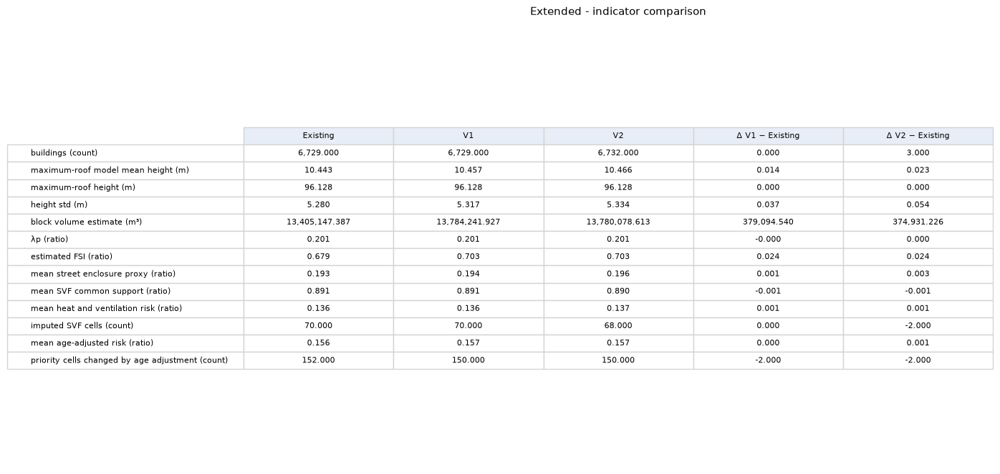

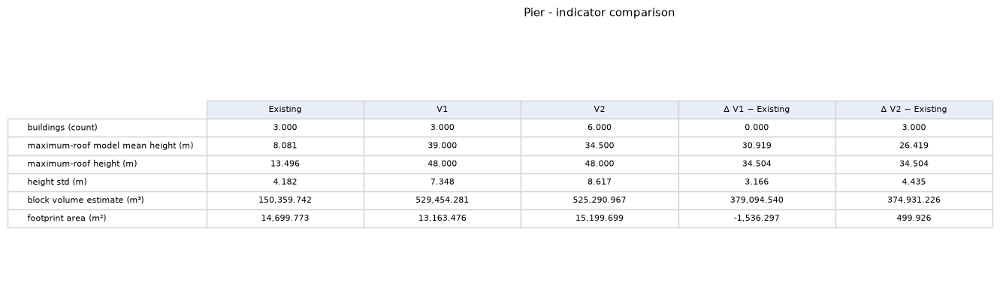

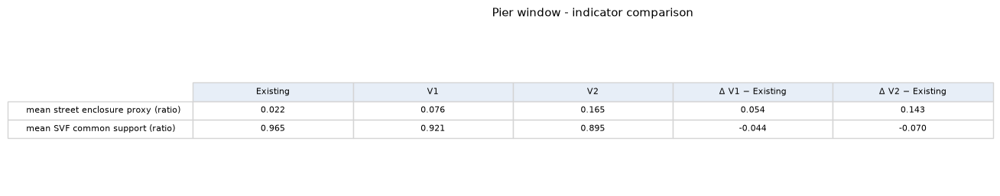

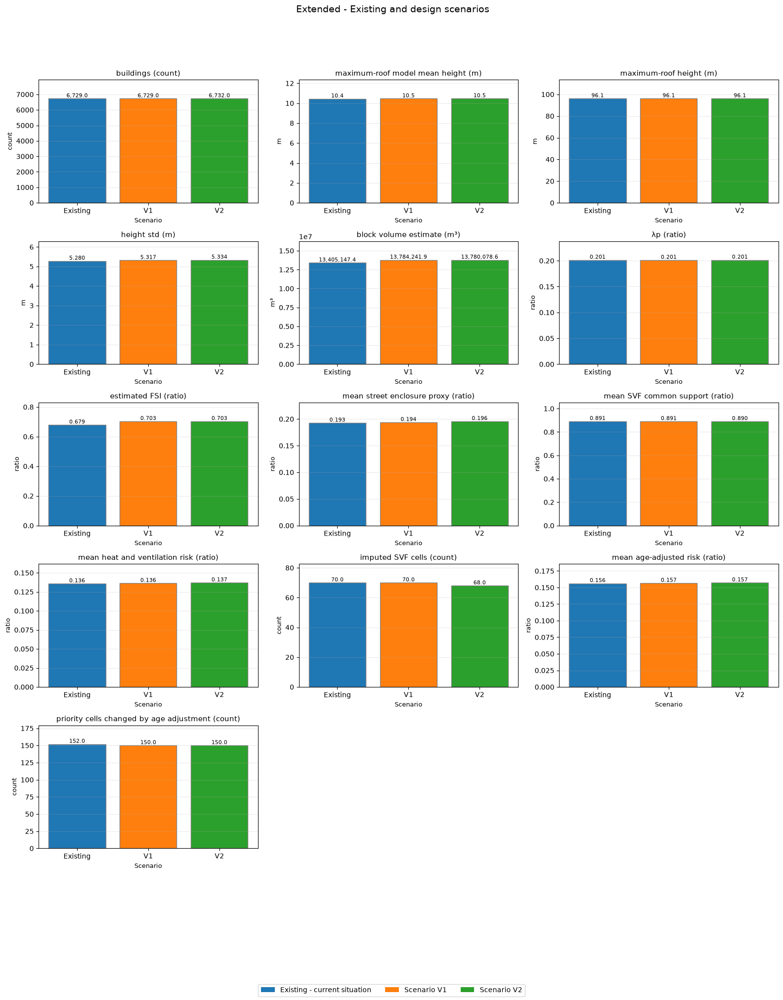

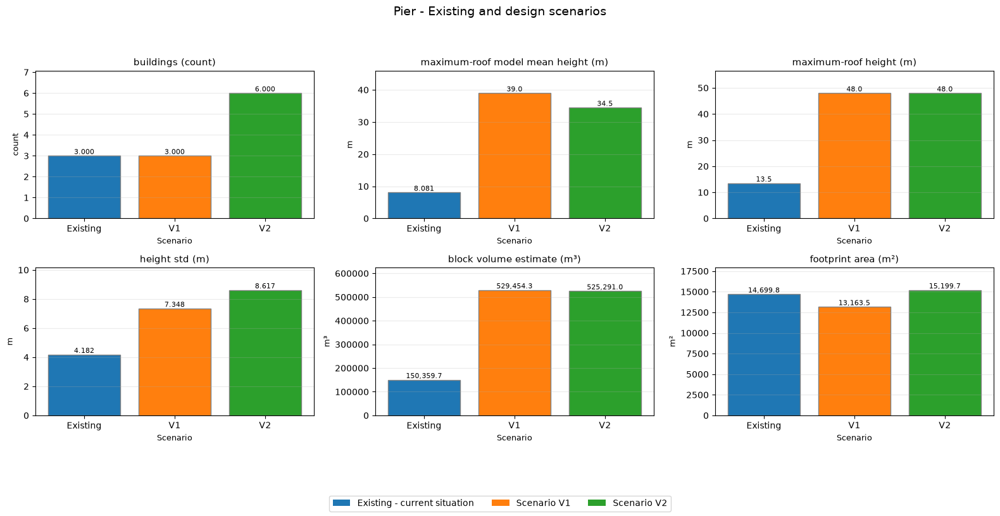

...

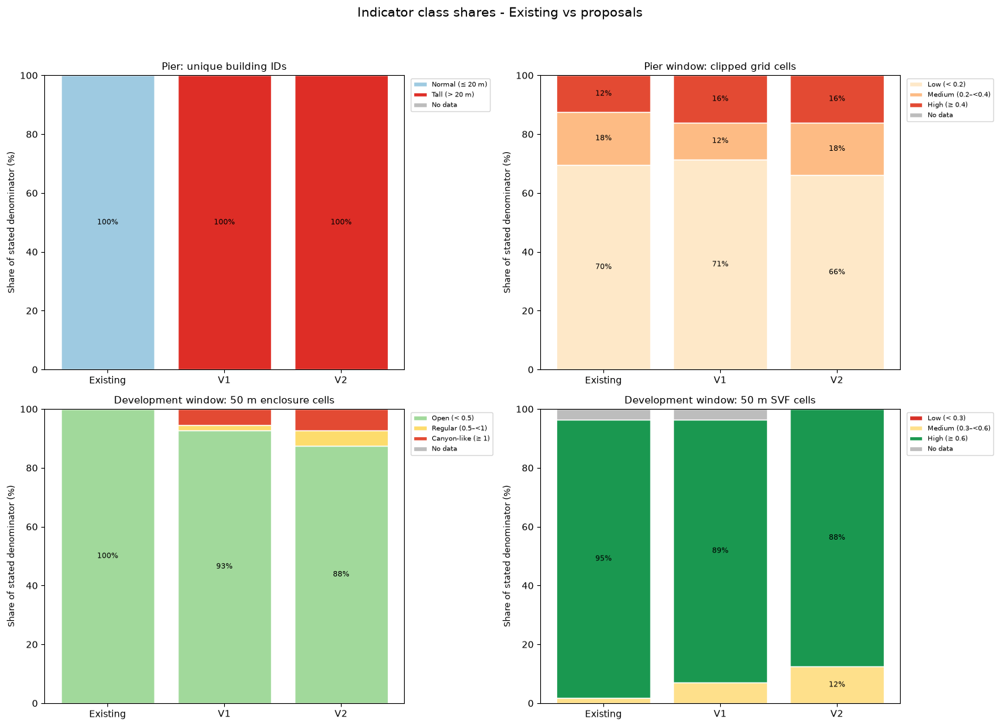

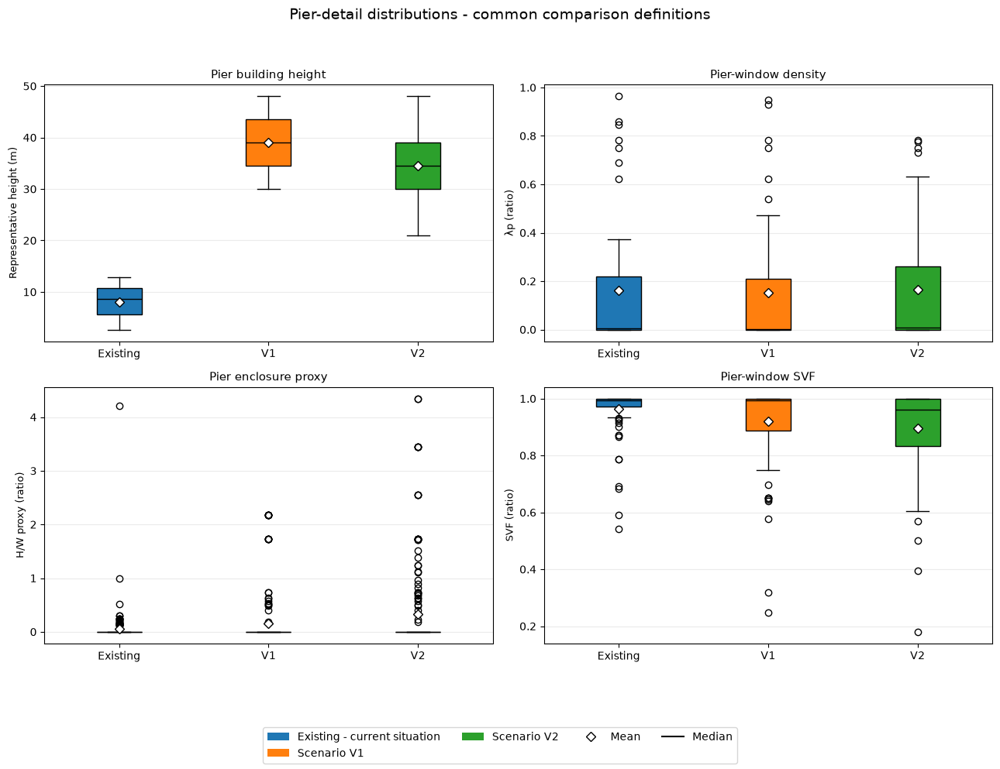

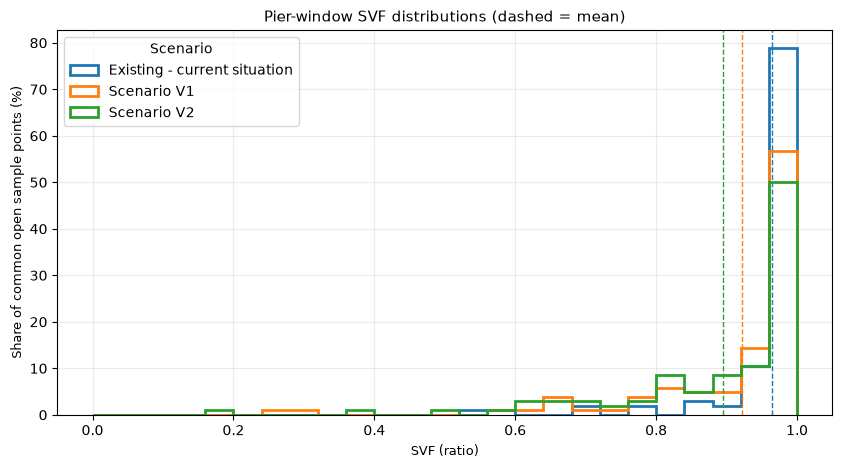

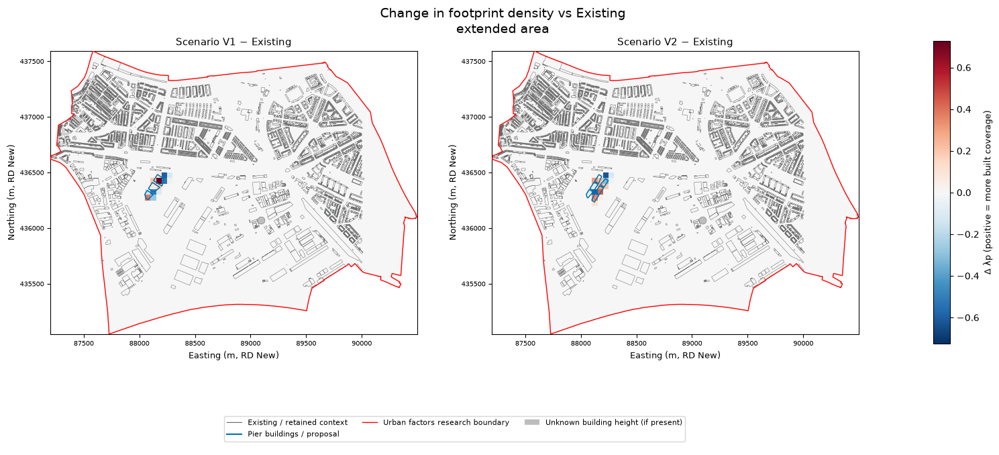

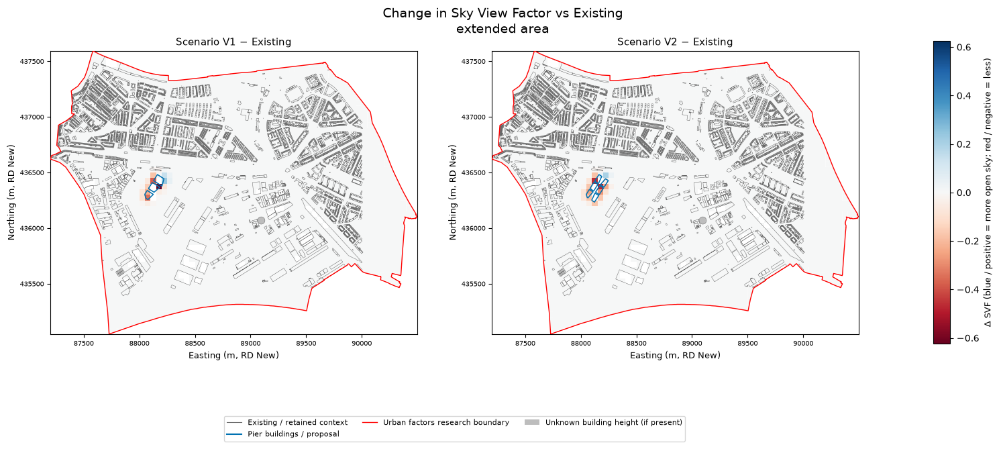

Complete. Source files were not modified.
This run’s tables: H:\GCS Final Project\GCS_FA_Tables\urban_factors_20261101_012354
This run’s plots : H:\GCS Final Project\GCS_FA_Plots\urban_factors_20261101_012354
Add V3/V4 only in VERSIONS (0.2), then Restart Kernel and Run All.


In [38]:
# Comparison - Existing vs every proposal; plus automatic all-pairs tables
required = ['buildings', 'grid', 'hw_points', 'svf_points']
for name in SCENARIO_NAMES:
    if any(key not in RESULTS[name] for key in required):
        raise RuntimeError(f'{name}: run Factors 1–4 in order before Comparison.')
names = SCENARIO_NAMES
summary = pd.DataFrame(SUMMARY).reindex(columns=names)
summary.index.name = 'Metric'
deltas = summary.drop(columns=BASELINE_VERSION).sub(summary[BASELINE_VERSION], axis=0)
deltas.columns = ['Δ ' + name + ' − Existing' for name in deltas.columns]
comparison_table = pd.concat([summary, deltas], axis=1)
save_table(comparison_table, 'summary_and_changes_vs_existing')
print('Existing is the current pier + current surrounding buildings. Each proposal retains the same surroundings.')
display(comparison_table.round(4))

# Every pair is automatic, including V2−V1, V3−V1, V4−V3, etc.
pair_records = []
for i, left in enumerate(names):
    for right in names[i + 1:]:
        for metric in summary.index:
            a, b = summary.loc[metric, left], summary.loc[metric, right]
            pair_records.append({'From': left, 'To': right, 'Metric': metric,
                                 'Absolute change': b - a,
                                 'Relative change (%)': 100 * (b - a) / abs(a) if pd.notna(a) and a != 0 else np.nan})
PAIRWISE_TABLE = pd.DataFrame(pair_records).set_index(['From', 'To', 'Metric'])
save_table(PAIRWISE_TABLE, 'all_pairwise_metric_changes')
print('All-pairs changes (zero baselines have no relative-percent change):')
display(PAIRWISE_TABLE.round(4))

# Printable tables as white-background figures, split by metric group.
for prefix in ('Extended:', 'Pier:', 'Pier window:'):
    table = comparison_table.loc[comparison_table.index.str.startswith(prefix)]
    if table.empty:
        continue
    fig, ax = plt.subplots(figsize=(5 + 1.7 * len(table.columns), 1.7 + 0.48 * len(table)))
    ax.axis('off')
    text = [[('-' if pd.isna(v) else f'{v:,.3f}') for v in row] for row in table.to_numpy()]
    t = ax.table(cellText=text, rowLabels=[s.replace(prefix, '').strip() for s in table.index],
                 colLabels=table.columns, cellLoc='center', loc='center')
    t.auto_set_font_size(False); t.set_fontsize(8); t.scale(1, 1.45)
    for (r, c), cell in t.get_celld().items():
        cell.set_edgecolor('#d4d4d4')
        if r == 0:
            cell.set_facecolor('#e7eef7')
    ax.set_title(prefix.rstrip(':') + ' - indicator comparison', pad=15)
    show_fig(fig, 'summary_table_' + prefix)

# Labelled bars for every registered factor metric, grouped to remain legible.
legend = [Patch(facecolor=VERSION_COLORS[n], label=vlabel(n)) for n in names]
for prefix in ('Extended:', 'Pier:', 'Pier window:'):
    metrics = [m for m in summary.index if m.startswith(prefix)]
    if not metrics:
        continue
    cols = min(3, len(metrics)); rows = math.ceil(len(metrics) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(5.3 * cols, 4.1 * rows), squeeze=False)
    for ax, metric in zip(axes.ravel(), metrics):
        vals = summary.loc[metric, names].to_numpy(dtype=float)
        bars = ax.bar(np.arange(len(names)), vals, color=[VERSION_COLORS[n] for n in names], edgecolor='grey')
        for bar, val in zip(bars, vals):
            if np.isfinite(val):
                ax.annotate(f'{val:,.3f}' if abs(val) < 10 else f'{val:,.1f}',
                            (bar.get_x() + bar.get_width() / 2, val), ha='center', va='bottom', fontsize=8)
        ax.set_xticks(np.arange(len(names)), names, rotation=20 if len(names) > 3 else 0)
        short = metric.replace(prefix, '').strip()
        ax.set_title(short); ax.set_xlabel('Scenario'); ax.set_ylabel(short.split('(')[-1].rstrip(')'))
        ax.grid(axis='y', alpha=0.25); ax.margins(y=0.18)
    for ax in axes.ravel()[len(metrics):]:
        ax.set_visible(False)
    fig.legend(handles=legend, loc='lower center', ncol=min(3, len(names)))
    fig.suptitle(prefix.rstrip(':') + ' - Existing and design scenarios', fontsize=14)
    fig.tight_layout(rect=(0, 0.12, 1, 0.94))
    show_fig(fig, 'metric_bars_' + prefix)

# Class shares: explicit denominators (IDs for heights; cells for density; parts for H/W).
class_panels = []
for factor in ('height', 'density', 'hw', 'svf'):
    frames = {}
    for n in names:
        if factor == 'height':
            table = pd.read_csv(RUN_TABLE_DIR / n / 'height_by_building_id_pier.csv')
            frames[n] = pd.Series(classify(table['representative_height_m'], 'height'))
        elif factor == 'density':
            g = RESULTS[n]['grid']; frames[n] = g.loc[g['in_pier_window'], 'density_class']
        elif factor == 'hw':
            g = RESULTS[n]['hw_grid']; frames[n] = g.loc[g['in_pier_window'], 'H_W_class']
        else:
            g = RESULTS[n]['svf_grid']; frames[n] = g.loc[g['in_pier_window'], 'SVF_class']
    labels = class_orders()[factor] + ['No data']
    shares = pd.DataFrame({n: frames[n].value_counts().reindex(labels, fill_value=0) / max(len(frames[n]), 1) * 100 for n in names})
    class_panels.append((factor, shares))
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
class_titles = {'height': 'Pier: unique building IDs', 'density': 'Pier window: clipped grid cells',
                'hw': 'Development window: 50 m enclosure cells', 'svf': 'Development window: 50 m SVF cells'}
for ax, (factor, shares) in zip(axes.ravel(), class_panels):
    bottom = np.zeros(len(names))
    for label, color in zip(shares.index, CLASS_COLORS[factor] + ['#bdbdbd']):
        val = shares.loc[label].to_numpy()
        ax.bar(np.arange(len(names)), val, bottom=bottom, color=color, edgecolor='white', label=label)
        for i, value in enumerate(val):
            if value >= 8:
                ax.text(i, bottom[i] + value / 2, f'{value:.0f}%', ha='center', va='center', fontsize=8)
        bottom += val
    ax.set_xticks(np.arange(len(names)), names); ax.set_ylim(0, 100)
    ax.set_ylabel('Share of stated denominator (%)'); ax.set_title(class_titles[factor])
    ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc='upper left')
fig.suptitle('Indicator class shares - Existing vs proposals', fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
show_fig(fig, 'class_shares_pier')

# Boxplots: every available factor distribution; NaN-only groups stay empty.
distributions = [
    ('Pier building height', 'Representative height (m)',
     {n: pd.read_csv(RUN_TABLE_DIR / n / 'height_by_building_id_pier.csv')['representative_height_m'].dropna().to_numpy() for n in names}),
    ('Pier-window density', 'λp (ratio)',
     {n: RESULTS[n]['grid'].loc[RESULTS[n]['grid']['in_pier_window'], 'lambda_p'].dropna().to_numpy() for n in names}),
    ('Pier enclosure proxy', 'H/W proxy (ratio)',
     {n: RESULTS[n]['hw_points'].loc[RESULTS[n]['hw_points']['is_focus']].groupby('building_key')['H_W'].mean().dropna().to_numpy() for n in names}),
    ('Pier-window SVF', 'SVF (ratio)',
     {n: RESULTS[n]['svf_points'].loc[RESULTS[n]['svf_points']['in_pier_window'] & COMMON_OPEN_MASK, 'SVF'].dropna().to_numpy() for n in names}),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (title, unit, data) in zip(axes.ravel(), distributions):
    bp = ax.boxplot([data[n] if len(data[n]) else [np.nan] for n in names], patch_artist=True, showmeans=True,
                    meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black'},
                    medianprops={'color': 'black'})
    for patch, n in zip(bp['boxes'], names):
        patch.set_facecolor(VERSION_COLORS[n])
    ax.set_xticks(np.arange(1, len(names) + 1), names); ax.set_title(title); ax.set_ylabel(unit)
    ax.grid(axis='y', alpha=0.25)
fig.legend(handles=legend + [Line2D([0], [0], marker='D', linestyle='', markerfacecolor='white', color='black', label='Mean'),
                             Line2D([0], [0], color='black', label='Median')], loc='lower center', ncol=min(4, len(names) + 2))
fig.suptitle('Pier-detail distributions - common comparison definitions', fontsize=14)
fig.tight_layout(rect=(0, 0.12, 1, 0.95))
show_fig(fig, 'factor_distributions')

fig, ax = plt.subplots(figsize=(10, 5))
for n in names:
    p = RESULTS[n]['svf_points']
    values = p.loc[p['in_pier_window'] & COMMON_OPEN_MASK, 'SVF'].dropna()
    if len(values):
        ax.hist(values, bins=np.linspace(0, 1, 26), weights=np.full(len(values), 100 / len(values)),
                histtype='step', linewidth=2, color=VERSION_COLORS[n], label=vlabel(n))
        ax.axvline(values.mean(), color=VERSION_COLORS[n], linestyle='--', linewidth=1)
ax.set_xlabel('SVF (ratio)'); ax.set_ylabel('Share of common open sample points (%)')
ax.set_title('Pier-window SVF distributions (dashed = mean)'); ax.legend(title='Scenario'); ax.grid(alpha=0.25)
show_fig(fig, 'svf_histogram_common_support')

# Before/after difference maps, matched by fixed grid ID / point ID.
base_grid = RESULTS[BASELINE_VERSION]['grid'].set_index('grid_id')['lambda_p']
base_points = RESULTS[BASELINE_VERSION]['svf_points'].set_index('point_id')['SVF']
density_changes, svf_changes = {}, {}
for n in names:
    if n == BASELINE_VERSION:
        continue
    g = RESULTS[n]['grid'].copy()
    g['change'] = g['lambda_p'] - g['grid_id'].map(base_grid)
    density_changes[n] = g
    p = RESULTS[n]['svf_points'].copy()
    p['change'] = p['SVF'] - p['point_id'].map(base_points)
    p.loc[~COMMON_OPEN_MASK, 'change'] = np.nan
    fine = FINE_GRID.rename(columns={'grid_id': 'fine_id'}).copy()
    fine['change'] = fine['fine_id'].map(p.set_index('fine_id')['change'])
    svf_changes[n] = aggregate_polygons(fine, GRID, 'change')
    save_table(p.drop(columns='geometry'), 'svf_change_vs_existing', n)
map_series(density_changes, 'change', 'Change in footprint density vs Existing', 'density_change_vs_existing',
           'Δ λp (positive = more built coverage)', cmap='RdBu_r', signed=True)
map_series(svf_changes, 'change', 'Change in Sky View Factor vs Existing', 'svf_change_vs_existing',
           'Δ SVF (blue / positive = more open sky; red / negative = less)', cmap='RdBu', signed=True)

print('Complete. Source files were not modified.')
print('This run’s tables:', RUN_TABLE_DIR)
print('This run’s plots :', RUN_PLOT_DIR)
print('Add V3/V4 only in VERSIONS (0.2), then Restart Kernel and Run All.')


In [40]:
# CELL A - Select GeoTIFF layers and inspect changes before exporting.
# True means selected. This cell does not write GeoTIFFs.
from pathlib import Path
from datetime import datetime
import hashlib
import json
import math
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from IPython.display import display

# Keep this dictionary in the cell: your choices survive rerunning the cell.
# Keys not listed here are added below with False as their default.
EXPORT_PLOTS = {
    'introduction/1_research_boundary_and_existing_buildings': True,
    'introduction/2_development_site_with_v1': True,
    'introduction/3_development_site_with_v2': True,
    'introduction/4_universal_50_x_50_m_analytical_grid': True,
    'V1/factor1_height_classes_extended': True,
    'V1/factor2_density_classes_extended': True,
    'V1/factor3_hw_50m_classes_extended': True,
    'V1/factor3_hw_classes_extended': True,
    'V1/factor4_svf_classes_extended': True,
    'V1/factor4_svf_continuous_extended': True,
    'V1/factor5_heat_ventilation_risk_extended': True,
    'V1/factor5_priority': True,
    'V1/factor6_final_risk_extended': True,
    'V1/factor6_priority': True,
    'V1/factor6_priority_change': True,
    'V1/svf_change_vs_existing_extended': True,
    'V2/factor1_height_classes_extended': True,
    'V2/factor2_density_classes_extended': True,
    'V2/factor3_hw_50m_classes_extended': True,
    'V2/factor3_hw_classes_extended': True,
    'V2/factor4_svf_classes_extended': True,
    'V2/factor4_svf_continuous_extended': True,
    'V2/factor5_heat_ventilation_risk_extended': True,
    'V2/factor5_priority': True,
    'V2/factor6_final_risk_extended': True,
    'V2/factor6_priority': True,
    'V2/factor6_priority_change': True,
    'V2/svf_change_vs_existing_extended': True,
    'shared/factor6_age_45plus_introduction': True,
    'shared/factor6_vulnerability_extended': False,
    'Existing/factor1_height_classes_extended': False,
    'Existing/factor1_mean_height_extended': False,
    'Existing/factor1_ndsm_extended': False,
    'Existing/factor2_density_classes_extended': False,
    'Existing/factor2_density_continuous_extended': False,
    'Existing/factor3_hw_50m_classes_extended': False,
    'Existing/factor3_hw_classes_extended': False,
    'Existing/factor3_hw_continuous_extended': False,
    'Existing/factor4_svf_classes_extended': False,
    'Existing/factor4_svf_continuous_extended': False,
    'Existing/factor5_heat_ventilation_risk_extended': False,
    'Existing/factor5_priority': False,
    'Existing/factor6_final_risk_extended': False,
    'Existing/factor6_priority': False,
    'Existing/factor6_priority_change': False,
    'V1/factor1_mean_height_extended': False,
    'V1/factor1_ndsm_extended': False,
    'V1/density_change_vs_existing_extended': False,
    'V1/factor2_density_continuous_extended': False,
    'V1/factor3_hw_continuous_extended': False,
    'V2/factor1_mean_height_extended': False,
    'V2/factor1_ndsm_extended': False,
    'V2/density_change_vs_existing_extended': False,
    'V2/factor2_density_continuous_extended': False,
    'V2/factor3_hw_continuous_extended': False,
}

EXPORT_ONLY_CHANGED = True  # False forces every selected layer to be exported.
EXPORT_PIXEL_M = 1.0        # Display resolution only; analysis remains 50 m / 25 m.
EXPORT_BOUNDARY_WIDTH_M = 2.0
EXPORT_GRID_LINE_WIDTH_M = 0.5
EXPORT_MISSING_COLOUR = '#bdbdbd'
EXPORT_WGS84_COPY = False   # True produces an additional geographic copy per layer.

# A stable destination allows unchanged exports to be reused across kernel restarts.
SELECTED_EXPORT_DIR = Path(PROJECT_DIR) / 'GCS_FA_Cesium' / 'selected_plot_exports'
EXPORT_STATE_FILE = SELECTED_EXPORT_DIR / 'selected_export_state.json'
PNG_STATE_FILE = SELECTED_EXPORT_DIR / 'png_inventory_state.json'
PNG_PREVIOUS_STATE = json.loads(PNG_STATE_FILE.read_text(encoding='utf-8')) if PNG_STATE_FILE.is_file() else {}
PNG_CURRENT_STATE = {}

# Extra geographic products are automatically listed with False defaults.
GEO_EXPORT_CATALOG = {}
def add_product(key, kind, scenario=None, result=None, field=None, factor=None,
                cmap=None, limits=None, categories=None, colours=None):
    GEO_EXPORT_CATALOG[key] = dict(kind=kind, scenario=scenario, result=result,
                                  field=field, factor=factor, cmap=cmap,
                                  limits=limits, categories=categories, colours=colours)
    EXPORT_PLOTS.setdefault(key, False)

for key, name in [('1_research_boundary_and_existing_buildings', BASELINE_VERSION),
                  ('2_development_site_with_v1', 'V1'), ('3_development_site_with_v2', 'V2')]:
    add_product('introduction/' + key, 'intro_buildings', name)
add_product('introduction/4_universal_50_x_50_m_analytical_grid', 'intro_grid')
priority_labels = ['lower', 'moderate', 'high']
priority_colours = ['#91cf60', '#fee08b', '#d73027']
for name in SCENARIO_NAMES:
    def add(stem, *args, **kwargs):
        add_product(name + '/' + stem, *args, scenario=name, **kwargs)
    add('factor1_height_classes_extended', 'factor', result='height_grid', field='height_class', factor='height')
    add('factor1_mean_height_extended', 'height_continuous', field='h_mean', cmap='viridis')
    add('factor1_ndsm_extended', 'height_continuous', field='h_mean', cmap='viridis')
    add('factor2_density_classes_extended', 'factor', result='grid', field='density_class', factor='density')
    add('factor2_density_continuous_extended', 'continuous', result='grid', field='lambda_p', cmap='Oranges', limits=(0, 1))
    add('factor3_hw_50m_classes_extended', 'factor', result='hw_grid', field='H_W_class', factor='hw')
    add('factor3_hw_classes_extended', 'factor', result='hw_fine', field='H_W_class', factor='hw')
    add('factor3_hw_continuous_extended', 'continuous', result='hw_fine', field='H_W', cmap='YlOrRd')
    add('factor4_svf_classes_extended', 'factor', result='svf_grid', field='SVF_class', factor='svf')
    add('factor4_svf_continuous_extended', 'continuous', result='svf_grid', field='SVF', cmap='viridis', limits=(0, 1))
    add('factor5_heat_ventilation_risk_extended', 'continuous', result='risk_grid', field='R', cmap='YlOrRd', limits=(0, 1))
    add('factor5_priority', 'categorical', result='risk_grid', field='priority_old', categories=priority_labels, colours=priority_colours)
    add('factor6_final_risk_extended', 'continuous', result='risk_grid', field='R_final', cmap='YlOrRd', limits=(0, 1))
    add('factor6_priority', 'categorical', result='risk_grid', field='priority_new', categories=priority_labels, colours=priority_colours)
    add('factor6_priority_change', 'categorical', result='risk_grid', field='priority_change',
        categories=['down', 'unchanged', 'up'], colours=['#4575b4', '#eeeeee', '#d73027'])
    if name != BASELINE_VERSION:
        add('svf_change_vs_existing_extended', 'svf_difference', field='change', cmap='RdBu')
        add('density_change_vs_existing_extended', 'density_difference', field='change', cmap='RdBu_r', limits=(-1, 1))
add_product('shared/factor6_age_45plus_introduction', 'age', field='percentage_45plus', cmap='OrRd', limits=(0, 100))
add_product('shared/factor6_vulnerability_extended', 'vulnerability', field='V', cmap='Purples', limits=(0, 1))

SVF_EXPORT_DIFF_CACHE = {}
def current_svf_difference(name):
    if name in SVF_EXPORT_DIFF_CACHE:
        return SVF_EXPORT_DIFF_CACHE[name].copy()
    current = RESULTS[name]['svf_points'].copy()
    baseline = RESULTS[BASELINE_VERSION]['svf_points'].set_index('point_id')['SVF']
    common_ids = None
    for other in SCENARIO_NAMES:
        sample = RESULTS[other]['svf_points']
        valid_ids = set(sample.loc[sample['SVF'].notna(), 'point_id'])
        common_ids = valid_ids if common_ids is None else common_ids & valid_ids
    current['change'] = current['SVF'] - current['point_id'].map(baseline)
    current.loc[~current['point_id'].isin(common_ids), 'change'] = np.nan
    fine = FINE_GRID.rename(columns={'grid_id': 'fine_id'}).copy()
    fine['change'] = fine['fine_id'].map(current.set_index('fine_id')['change'])
    result = aggregate_polygons(fine, GRID, 'change')
    SVF_EXPORT_DIFF_CACHE[name] = result
    return result.copy()

def source_layer(spec):
    kind, name = spec['kind'], spec['scenario']
    if kind in ('intro_buildings', 'height_continuous'):
        return V[name]['buildings'].copy()
    if kind == 'intro_grid':
        return GRID.copy()
    if kind == 'age':
        return buurt.copy()
    if kind == 'vulnerability':
        return VULNERABILITY_GRID.copy()
    if kind == 'svf_difference':
        return current_svf_difference(name)
    if kind == 'density_difference':
        layer = RESULTS[name]['grid'].copy()
        baseline = RESULTS[BASELINE_VERSION]['grid'].set_index('grid_id')['lambda_p']
        layer['change'] = layer['lambda_p'] - layer['grid_id'].map(baseline)
        return layer
    return RESULTS[name][spec['result']].copy()

def prepared_layer(spec):
    layer = source_layer(spec)
    if layer.crs is None:
        raise ValueError('Layer CRS is missing.')
    layer = layer.to_crs(STUDY_AREA.crs)
    if not layer.geom_type.isin(['Polygon', 'MultiPolygon']).all():
        raise ValueError('Expected polygon support; this exporter does not draw sample points or gap lines.')
    layer.geometry = layer.geometry.intersection(STUDY_GEOM)
    return layer.loc[layer.geometry.notna() & ~layer.geometry.is_empty & (layer.area > 0)].copy()

def export_style(spec):
    style = dict(spec)
    factor = style.get('factor')
    if factor:
        style['categories'] = list(class_orders()[factor])
        style['colours'] = list(CLASS_COLORS[factor])
    if spec['kind'] == 'svf_difference':
        values = []
        for name in SCENARIO_NAMES:
            if name != BASELINE_VERSION:
                a = current_svf_difference(name)['change'].to_numpy(dtype=float)
                a = a[np.isfinite(a)]
                if len(a):
                    values.append(float(np.abs(a).max()))
        bound = max(values + [1e-6])
        style['limits'] = (-bound, bound)
    elif style.get('cmap') and style.get('limits') is None:
        # Use a shared continuous scale across current scenarios.
        maxima = []
        for name in SCENARIO_NAMES:
            try:
                other = dict(spec, scenario=name)
                a = source_layer(other)[spec['field']].to_numpy(dtype=float)
                a = a[np.isfinite(a)]
                if len(a):
                    maxima.append(float(a.max()))
            except KeyError:
                pass
        style['limits'] = (0, max(maxima + [1e-6]))
    return style

def layer_fingerprint(layer, style):
    digest = hashlib.sha256()
    digest.update(str(STUDY_AREA.crs).encode())
    digest.update(STUDY_GEOM.wkb)
    if style['kind'] == 'intro_buildings' and style['scenario'] != BASELINE_VERSION:
        digest.update(union_geometry(DEVELOPMENT_SITE).wkb)
    field = style.get('field')
    # Feature order matters if geometries overlap, so keep the rendering order.
    for geom in layer.geometry:
        digest.update(geom.wkb)
    if field:
        if field not in layer:
            raise KeyError(f'Missing field: {field}')
        digest.update(layer[field].reset_index(drop=True).to_json().encode())
    options = dict(style=style, pixel_m=EXPORT_PIXEL_M,
                   boundary_width_m=EXPORT_BOUNDARY_WIDTH_M,
                   grid_line_width_m=EXPORT_GRID_LINE_WIDTH_M,
                   missing_colour=EXPORT_MISSING_COLOUR,
                   wgs84=EXPORT_WGS84_COPY, renderer_version=1)
    digest.update(json.dumps(options, sort_keys=True, default=str).encode())
    return digest.hexdigest()

def target_tif(key):
    group, stem = key.split('/', 1)
    return SELECTED_EXPORT_DIR / group / 'imagery' / (stem + '.tif')

EXPORT_PREVIOUS_STATE = json.loads(EXPORT_STATE_FILE.read_text(encoding='utf-8')) if EXPORT_STATE_FILE.is_file() else {}
EXPORT_PREPARED = {}
rows = []
for key, spec in GEO_EXPORT_CATALOG.items():
    try:
        layer = prepared_layer(spec)
        style = export_style(spec)
        fingerprint = layer_fingerprint(layer, style)
        previous = EXPORT_PREVIOUS_STATE.get(key, {})
        if not previous:
            status = 'NEW'
        elif fingerprint != previous.get('fingerprint'):
            status = 'CHANGED'
        elif not target_tif(key).is_file():
            status = 'OUTPUT MISSING'
        elif EXPORT_WGS84_COPY and not target_tif(key).with_name(target_tif(key).stem + '_wgs84.tif').is_file():
            status = 'OUTPUT MISSING'
        else:
            status = 'UNCHANGED'
        EXPORT_PREPARED[key] = dict(layer=layer, style=style, fingerprint=fingerprint, status=status)
        reason = ''
    except (KeyError, NameError, ValueError) as exc:
        status, reason = 'UNAVAILABLE', str(exc)
    rows.append({'Layer': key, 'Export': bool(EXPORT_PLOTS[key]), 'Status': status, 'Details': reason})
EXPORT_STATUS = pd.DataFrame(rows).set_index('Layer')

print('Geographic products: edit EXPORT_PLOTS above, then rerun this cell.')
print('NEW = no previous successful export; CHANGED = rendered data/style changed since export.')
print('Output directory:', SELECTED_EXPORT_DIR)
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(EXPORT_STATUS)

# Also inventory every actual notebook PNG, including charts and combined panels.
# Those figures are not automatically equivalent to geographic layers.
_png_rows = []
for path in sorted(Path(RUN_PLOT_DIR).rglob('*.png')):
    relative = path.relative_to(RUN_PLOT_DIR).as_posix()
    png_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    PNG_CURRENT_STATE[relative] = png_hash
    png_status = ('NEW' if relative not in PNG_PREVIOUS_STATE else
                  'CHANGED' if PNG_PREVIOUS_STATE[relative] != png_hash else 'UNCHANGED')
    key = relative[:-4]
    if relative.startswith('introduction/'):
        candidates = [k for k in GEO_EXPORT_CATALOG if k.startswith('introduction/') and k.split('/')[-1] == path.stem]
        key = candidates[0] if candidates else key
    if relative == 'comparison/factor6_age_45plus_introduction.png':
        key = 'shared/factor6_age_45plus_introduction'
    if relative == 'comparison/factor6_vulnerability_extended.png':
        key = 'shared/factor6_vulnerability_extended'
    supported = key in GEO_EXPORT_CATALOG
    choice_key = key if supported else 'png_only/' + relative
    EXPORT_PLOTS.setdefault(choice_key, False)
    _png_rows.append({'Saved plot': relative, 'Selection key': choice_key,
                      'Export': bool(EXPORT_PLOTS[choice_key]),
                      'Geographic GeoTIFF supported': supported,
                      'PNG status since previous export session': png_status})
SAVED_PLOT_INVENTORY = pd.DataFrame(_png_rows)
print('All saved notebook plots, including charts and comparison panels:')
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(SAVED_PLOT_INVENTORY)
print('png_only entries are listed for completeness. They cannot be georeferenced as one map.')
print('Additional geographic products default to False; add any displayed key to EXPORT_PLOTS to retain a custom choice.')


Geographic products: edit EXPORT_PLOTS above, then rerun this cell.
NEW = no previous successful export; CHANGED = rendered data/style changed since export.
Output directory: H:\GCS Final Project\GCS_FA_Cesium\selected_plot_exports


,Export,Status,Details
Layer,,,
introduction/1_research_boundary_and_existing_buildings,True,NEW,
introduction/2_development_site_with_v1,True,NEW,
introduction/3_development_site_with_v2,True,NEW,
introduction/4_universal_50_x_50_m_analytical_grid,True,NEW,
Existing/factor1_height_classes_extended,False,NEW,
Existing/factor1_mean_height_extended,False,NEW,
Existing/factor1_ndsm_extended,False,NEW,
Existing/factor2_density_classes_extended,False,NEW,
Existing/factor2_density_continuous_extended,False,NEW,


All saved notebook plots, including charts and comparison panels:


,Saved plot,Selection key,Export,Geographic GeoTIFF supported,PNG status since previous export session
0,comparison/class_shares_pier.png,png_only/comparison/class_shares_pier.png,False,False,NEW
1,comparison/density_change_vs_existing_extended.png,png_only/comparison/density_change_vs_existing_extended.png,False,False,NEW
2,comparison/factor1_height_classes_extended.png,png_only/comparison/factor1_height_classes_extended.png,False,False,NEW
3,comparison/factor1_mean_height_extended.png,png_only/comparison/factor1_mean_height_extended.png,False,False,NEW
4,comparison/factor1_ndsm_extended.png,png_only/comparison/factor1_ndsm_extended.png,False,False,NEW
5,comparison/factor2_density_classes_extended.png,png_only/comparison/factor2_density_classes_extended.png,False,False,NEW
6,comparison/factor2_density_continuous_extended.png,png_only/comparison/factor2_density_continuous_extended.png,False,False,NEW
7,comparison/factor3_hw_50m_classes_extended.png,png_only/comparison/factor3_hw_50m_classes_extended.png,False,False,NEW
8,comparison/factor3_hw_classes_extended.png,png_only/comparison/factor3_hw_classes_extended.png,False,False,NEW
9,comparison/factor3_hw_continuous_extended.png,png_only/comparison/factor3_hw_continuous_extended.png,False,False,NEW


png_only entries are listed for completeness. They cannot be georeferenced as one map.
Additional geographic products default to False; add any displayed key to EXPORT_PLOTS to retain a custom choice.


In [41]:
# CELL B - Export only selected geographic layers, without building outlines.
# Run Cell A immediately before this cell whenever analysis data or selections change.
import os
import rasterio
from rasterio.features import rasterize
from rasterio.transform import from_origin
from rasterio.enums import ColorInterp
from rasterio.warp import calculate_default_transform, reproject, Resampling
from matplotlib import colormaps
from matplotlib.colors import Normalize, to_rgba

if EXPORT_PIXEL_M <= 0 or EXPORT_BOUNDARY_WIDTH_M <= 0:
    raise ValueError('Export pixel size and boundary width must be positive.')
if not STUDY_AREA.crs.is_projected or STUDY_AREA.crs.axis_info[0].unit_name.lower() not in ('metre', 'meter'):
    raise ValueError('Use a projected metre-based research CRS, normally EPSG:28992.')

# Validate everything selected before writing any GeoTIFFs.
selected_keys = [key for key, enabled in EXPORT_PLOTS.items() if enabled]
unsupported = [key for key in selected_keys if key not in GEO_EXPORT_CATALOG]
if unsupported:
    raise ValueError('These entries are charts, multi-panel PNGs, or unknown keys, not supported single geographic layers: '
                     + ', '.join(unsupported) + '. Set them to False.')
# Recompute selected data/styles/hashes now, so exports never use stale prepared data.
SVF_EXPORT_DIFF_CACHE.clear()
selected = {}
for key in selected_keys:
    spec = GEO_EXPORT_CATALOG[key]
    try:
        layer = prepared_layer(spec)
        style = export_style(spec)
        fingerprint = layer_fingerprint(layer, style)
    except (KeyError, NameError, ValueError) as exc:
        raise ValueError(f'{key} is not ready. Run its factor cell first. Details: {exc}') from exc
    previous = EXPORT_PREVIOUS_STATE.get(key, {})
    old_path = target_tif(key)
    exists = old_path.is_file()
    if EXPORT_WGS84_COPY:
        exists = exists and old_path.with_name(old_path.stem + '_wgs84.tif').is_file()
    changed = fingerprint != previous.get('fingerprint') or not exists
    selected[key] = dict(layer=layer, style=style, fingerprint=fingerprint, changed=changed)

pixel = float(EXPORT_PIXEL_M)
xmin, ymin, xmax, ymax = STUDY_GEOM.bounds
left = math.floor(xmin / pixel) * pixel
bottom = math.floor(ymin / pixel) * pixel
right = math.ceil(xmax / pixel) * pixel
top = math.ceil(ymax / pixel) * pixel
shape = (int(round((top - bottom) / pixel)), int(round((right - left) / pixel)))
transform = from_origin(left, top, pixel, pixel)
if min(shape) <= 0:
    raise ValueError('Empty export raster extent.')

def burn(shapes, fill=0, dtype='uint8', touched=False):
    shapes = [(g, v) for g, v in shapes if g is not None and not g.is_empty]
    return rasterize(shapes, out_shape=shape, transform=transform, fill=fill,
                     dtype=dtype, all_touched=touched) if shapes else np.full(shape, fill, dtype=dtype)

inside = burn([(STUDY_GEOM, 1)]).astype(bool)
boundary_stroke = STUDY_GEOM.boundary.buffer(EXPORT_BOUNDARY_WIDTH_M / 2).intersection(STUDY_GEOM)
boundary_pixels = burn([(boundary_stroke, 1)], touched=True).astype(bool) & inside

def colour_bytes(colour):
    return np.rint(np.asarray(to_rgba(colour)) * 255).astype('uint8')

def render_export(layer, style):
    if style['kind'] == 'height_continuous':
        layer = layer.sort_values(style['field'], kind='stable', na_position='first')
    image = np.zeros((*shape, 4), dtype='uint8')
    kind = style['kind']
    if kind in ('intro_buildings', 'intro_grid'):
        image[inside] = colour_bytes('white')
        if kind == 'intro_buildings':
            buildings = burn([(g, 1) for g in layer.geometry]).astype(bool) & inside
            image[buildings] = colour_bytes('black')
            if style['scenario'] != BASELINE_VERSION:
                site = union_geometry(DEVELOPMENT_SITE).boundary.buffer(EXPORT_BOUNDARY_WIDTH_M / 2)
                site = site.intersection(STUDY_GEOM)
                image[burn([(site, 1)], touched=True).astype(bool) & inside] = colour_bytes('red')
        else:
            cells = burn([(g, 1) for g in layer.geometry]).astype(bool) & inside
            image[cells] = colour_bytes('#eeeeee')
            strokes = [(g.boundary.buffer(EXPORT_GRID_LINE_WIDTH_M / 2), 1) for g in layer.geometry]
            image[burn(strokes, touched=True).astype(bool) & inside] = colour_bytes('#777777')
    else:
        field = style['field']
        support = burn([(g, 1) for g in layer.geometry]).astype(bool) & inside
        image[support] = colour_bytes(EXPORT_MISSING_COLOUR)
        categories = style.get('categories')
        if categories is not None:
            coding = {label: index + 1 for index, label in enumerate(categories)}
            codes = layer[field].map(coding)
            raster = burn([(g, int(v)) for g, v in zip(layer.geometry, codes) if pd.notna(v)])
            for code, colour in enumerate(style['colours'], 1):
                image[(raster == code) & inside] = colour_bytes(colour)
        else:
            values = pd.to_numeric(layer[field], errors='coerce')
            raster = burn([(g, float(v)) for g, v in zip(layer.geometry, values) if np.isfinite(v)],
                          fill=np.nan, dtype='float32')
            valid = np.isfinite(raster) & inside
            lo, hi = style['limits']
            if hi <= lo:
                hi = lo + 1e-6
            norm = Normalize(vmin=lo, vmax=hi, clip=True)
            mapped = colormaps[style['cmap']](norm(np.nan_to_num(raster, nan=lo)), bytes=True)
            image[valid] = mapped[valid]
    # Only the research boundary is added to analytical layers. No building outlines.
    image[boundary_pixels] = colour_bytes('red')
    image[~inside] = 0
    return np.moveaxis(image, -1, 0)

def write_tif(path, rgba, key, style):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.stem + '.temporary.tif')
    try:
        with rasterio.open(temporary, 'w', driver='GTiff', count=4, dtype='uint8',
                           width=shape[1], height=shape[0], crs=STUDY_AREA.crs,
                           transform=transform, compress='deflate', tiled=True,
                           blockxsize=256, blockysize=256, BIGTIFF='IF_SAFER') as dst:
            dst.write(rgba)
            dst.colorinterp = (ColorInterp.red, ColorInterp.green, ColorInterp.blue, ColorInterp.alpha)
            dst.update_tags(layer=key, role='COLOURED_IMAGERY_NOT_TERRAIN',
                            analysis_grid_m=str(GRID_SIZE_M), export_pixel_m=str(pixel),
                            building_outlines='absent', value_field=str(style.get('field') or ''),
                            missing_colour=EXPORT_MISSING_COLOUR)
        with rasterio.open(temporary) as check:
            assert check.count == 4 and check.crs == STUDY_AREA.crs
            assert check.width == shape[1] and check.height == shape[0]
        os.replace(temporary, path)
    finally:
        if temporary.exists():
            temporary.unlink()

def geographic_copy(path):
    geographic = path.with_name(path.stem + '_wgs84.tif')
    temporary = geographic.with_name(geographic.stem + '.temporary.tif')
    try:
        with rasterio.open(path) as src:
            tr, width, height = calculate_default_transform(src.crs, 'EPSG:4326', src.width, src.height, *src.bounds)
            profile = src.profile.copy()
            profile.update(crs='EPSG:4326', transform=tr, width=width, height=height)
            with rasterio.open(temporary, 'w', **profile) as dst:
                for band in range(1, 5):
                    reproject(source=rasterio.band(src, band), destination=rasterio.band(dst, band),
                              src_transform=src.transform, src_crs=src.crs,
                              dst_transform=tr, dst_crs='EPSG:4326', resampling=Resampling.nearest)
                dst.colorinterp = src.colorinterp
                dst.update_tags(**src.tags())
        with rasterio.open(temporary) as check:
            assert check.count == 4 and str(check.crs) == 'EPSG:4326'
        os.replace(temporary, geographic)
    finally:
        if temporary.exists():
            temporary.unlink()
    return geographic

SELECTED_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
state = dict(EXPORT_PREVIOUS_STATE)
manifest_rows = []
for key, data in selected.items():
    path = target_tif(key)
    if EXPORT_ONLY_CHANGED and not data['changed']:
        action = 'SKIPPED UNCHANGED'
    else:
        rgba = render_export(data['layer'], data['style'])
        write_tif(path, rgba, key, data['style'])
        del rgba
        if EXPORT_WGS84_COPY:
            geographic_copy(path)
        state[key] = dict(fingerprint=data['fingerprint'],
                          exported_at=datetime.now().isoformat(timespec='seconds'),
                          file=str(path), style=data['style'])
        # Save state only after this layer and its optional copy succeeded.
        temporary_state = EXPORT_STATE_FILE.with_suffix('.temporary.json')
        temporary_state.write_text(json.dumps(state, indent=2, default=str), encoding='utf-8')
        os.replace(temporary_state, EXPORT_STATE_FILE)
        action = 'EXPORTED'
    manifest_rows.append({'Layer': key, 'Action': action, 'File': str(path)})
    print(action, key)

EXPORT_PREVIOUS_STATE = state
_png_state_temp = PNG_STATE_FILE.with_suffix('.temporary.json')
_png_state_temp.write_text(json.dumps(PNG_CURRENT_STATE, indent=2), encoding='utf-8')
os.replace(_png_state_temp, PNG_STATE_FILE)
manifest = pd.DataFrame(manifest_rows, columns=['Layer', 'Action', 'File'])
manifest.to_csv(SELECTED_EXPORT_DIR / 'export_manifest.csv', index=False, encoding='utf-8-sig')
EXPORT_STATUS.to_csv(SELECTED_EXPORT_DIR / 'selection_status_before_export.csv', encoding='utf-8-sig')
SAVED_PLOT_INVENTORY.to_csv(SELECTED_EXPORT_DIR / 'all_saved_notebook_plots.csv', index=False, encoding='utf-8-sig')
legend = {'type': 'RGBA geographic imagery, not numeric analysis rasters',
          'crs': str(STUDY_AREA.crs), 'boundary_colour': 'red',
          'boundary_width_m': EXPORT_BOUNDARY_WIDTH_M, 'missing_colour': EXPORT_MISSING_COLOUR,
          'building_outlines': False,
          'notes': ['Buildings are retained as filled black polygons in introduction maps only.',
                    'No titles, axes, labels, legends or chart furniture are burned into GeoTIFFs.',
                    '25 m fine H/W support retains building-shaped holes; no outlines are added.',
                    'Outside-research-area pixels are transparent.',
                    'The 1 m rendering resolution does not change the 50 m / 25 m analysis supports.'],
          'layers': {key: record.get('style') for key, record in state.items()}}
(SELECTED_EXPORT_DIR / 'legends.json').write_text(json.dumps(legend, indent=2, default=str), encoding='utf-8')
display(manifest)
print('Export folder:', SELECTED_EXPORT_DIR)
print('Rerun Cell A to refresh the status table. False entries are not exported or deleted.')

EXPORTED introduction/1_research_boundary_and_existing_buildings
EXPORTED introduction/2_development_site_with_v1
EXPORTED introduction/3_development_site_with_v2
EXPORTED introduction/4_universal_50_x_50_m_analytical_grid
EXPORTED V1/factor1_height_classes_extended
EXPORTED V1/factor2_density_classes_extended
EXPORTED V1/factor3_hw_50m_classes_extended
EXPORTED V1/factor3_hw_classes_extended
EXPORTED V1/factor4_svf_classes_extended
EXPORTED V1/factor4_svf_continuous_extended
EXPORTED V1/factor5_heat_ventilation_risk_extended
EXPORTED V1/factor5_priority
EXPORTED V1/factor6_final_risk_extended
EXPORTED V1/factor6_priority
EXPORTED V1/factor6_priority_change
EXPORTED V1/svf_change_vs_existing_extended
EXPORTED V2/factor1_height_classes_extended
EXPORTED V2/factor2_density_classes_extended
EXPORTED V2/factor3_hw_50m_classes_extended
EXPORTED V2/factor3_hw_classes_extended
EXPORTED V2/factor4_svf_classes_extended
EXPORTED V2/factor4_svf_continuous_extended
EXPORTED V2/factor5_heat_ventila

,Layer,Action,File
0,introduction/1_research_boundary_and_existing_...,EXPORTED,H:\GCS Final Project\GCS_FA_Cesium\selected_pl...
1,introduction/2_development_site_with_v1,EXPORTED,H:\GCS Final Project\GCS_FA_Cesium\selected_pl...
2,introduction/3_development_site_with_v2,EXPORTED,H:\GCS Final Project\GCS_FA_Cesium\selected_pl...
3,introduction/4_universal_50_x_50_m_analytical_...,EXPORTED,H:\GCS Final Project\GCS_FA_Cesium\selected_pl...
4,V1/factor1_height_classes_extended,EXPORTED,H:\GCS Final Project\GCS_FA_Cesium\selected_pl...
5,V1/factor2_density_classes_extended,EXPORTED,H:\GCS Final Project\GCS_FA_Cesium\selected_pl...
6,V1/factor3_hw_50m_classes_extended,EXPORTED,H:\GCS Final Project\GCS_FA_Cesium\selected_pl...
7,V1/factor3_hw_classes_extended,EXPORTED,H:\GCS Final Project\GCS_FA_Cesium\selected_pl...
8,V1/factor4_svf_classes_extended,EXPORTED,H:\GCS Final Project\GCS_FA_Cesium\selected_pl...
9,V1/factor4_svf_continuous_extended,EXPORTED,H:\GCS Final Project\GCS_FA_Cesium\selected_pl...


Export folder: H:\GCS Final Project\GCS_FA_Cesium\selected_plot_exports
Rerun Cell A to refresh the status table. False entries are not exported or deleted.


## Method and limitations

Age weights of 1 for 65+, 0.5 for 45-65 and 0.3 for 0-15 are modelling assumptions. The introductory age map is instead the unweighted 45-65 plus 65+ share. Rounded and suppressed CBS values remain distinguishable in quality tables. Unsupported vulnerability is assigned zero only for index combination and retains a missing-data flag; zero is not evidence of no vulnerable residents.

Vulnerability combines a building-area-weighted normalized age score and percentile-ranked positive weighted person-equivalent counts, each with weight 0.5. Baseline allocation is fixed across scenarios and does not predict new residents or household redistribution. By default all footprints are an allocation proxy, not verified residential buildings. Complete footprints for the full selected buurten are required for correct population denominators. Unconfirmed coverage produces a visible provisional flag and warning.

Factor 5 uses the original within-scenario min-max normalization, then equally averages normalized density, normalized H/W and inverted normalized SVF. As in the original template, missing H/W is filled with zero and missing SVF with the scenario median, with explicit imputation flags. Independent scenario normalizations support relative patterns but not direct physical hazard comparisons.

Factor 6 computes `R_final_raw = R * (1 + alpha * V)` and then min-max rescales. The hazard floor exists before rescaling; a rescaled final value need not be greater than its original R. Priorities are relative quartile classes, not absolute health thresholds. Ties can prevent exact 25/50/25 splits; a constant index is assigned moderate priority. Sensitivity tests compare alpha 0.5, 1 and 2 plus an alternative 45-65 weight of 0.3 against the default alpha 1 model.

Numeric rasters retain 50 m pixels, use NoData -9999 and a pixel-centre research-boundary mask. A 50 m raster cannot represent an exact boundary through every edge pixel; clipped polygon vectors and fine rendered imagery provide a closer visual outline. WGS84 reprojection changes angular pixel spacing, so the geographic copy does not have a uniform 50 m resolution.

Restart the kernel and run all cells after changes. Source files are never modified. Old notebook outputs were cleared so that earlier results cannot be mistaken for updated results.


In [22]:
# Plot inventory - list every saved plot from this notebook run
# Run after all plotting cells have completed.
# This cell does not create another plot.

from pathlib import Path
import pandas as pd
from IPython.display import display

plot_root = Path(RUN_PLOT_DIR)

if not plot_root.is_dir():
    raise FileNotFoundError(
        f"The current run's plot folder does not exist:\n{plot_root}\n"
        "Run the settings and plotting cells first."
    )

plot_files = sorted(
    [
        path
        for path in plot_root.rglob("*")
        if path.is_file() and path.suffix.lower() == ".png"
    ],
    key=lambda path: str(
        path.relative_to(plot_root)
    ).casefold()
)

if not plot_files:
    print("No saved PNG plots were found for this run.")
    print("Folder checked:", plot_root)

else:
    records = []

    for number, path in enumerate(plot_files, start=1):
        relative_path = path.relative_to(plot_root)

        group = (
            str(relative_path.parent)
            if relative_path.parent != Path(".")
            else "Main folder"
        )

        records.append({
            "Plot number": number,
            "Scenario / group": group,
            "Plot name from filename": (
                path.stem.replace("_", " ")
            ),
            "Filename": path.name,
            "Relative path": str(relative_path)
        })

    PLOT_INVENTORY = (
        pd.DataFrame(records)
        .set_index("Plot number")
    )

    PLOT_COUNTS = (
        PLOT_INVENTORY
        .groupby("Scenario / group", sort=True)
        .size()
        .to_frame("Number of plots")
    )

    print("PLOT INVENTORY")
    print("Run:", plot_root.name)
    print("Plot folder:", plot_root)
    print("Total saved plots:", len(PLOT_INVENTORY))

    print("\nNumber of plots by scenario / group:")
    display(PLOT_COUNTS)

    print("\nComplete list of saved plots:")

    with pd.option_context(
        "display.max_rows", None,
        "display.max_columns", None,
        "display.max_colwidth", None
    ):
        display(PLOT_INVENTORY)

    inventory_path = save_table(
        PLOT_INVENTORY,
        "all_plots_inventory",
        "comparison"
    )

    counts_path = save_table(
        PLOT_COUNTS,
        "all_plots_counts",
        "comparison"
    )

    print("\nComplete inventory saved to:", inventory_path)
    print("Grouped counts saved to:", counts_path)

PLOT INVENTORY
Run: urban_factors_20261031_222625
Plot folder: H:\GCS Final Project\GCS_FA_Plots\urban_factors_20261031_222625
Total saved plots: 63

Number of plots by scenario / group:


,Number of plots
Scenario / group,
V1,17
V2,17
comparison,25
introduction,4



Complete list of saved plots:


,Scenario / group,Plot name from filename,Filename,Relative path
Plot number,,,,
1,comparison,class shares pier,class_shares_pier.png,comparison\class_shares_pier.png
2,comparison,density change vs existing extended,density_change_vs_existing_extended.png,comparison\density_change_vs_existing_extended.png
3,comparison,factor1 height classes extended,factor1_height_classes_extended.png,comparison\factor1_height_classes_extended.png
4,comparison,factor1 mean height extended,factor1_mean_height_extended.png,comparison\factor1_mean_height_extended.png
5,comparison,factor1 ndsm extended,factor1_ndsm_extended.png,comparison\factor1_ndsm_extended.png
6,comparison,factor2 density classes extended,factor2_density_classes_extended.png,comparison\factor2_density_classes_extended.png
7,comparison,factor2 density continuous extended,factor2_density_continuous_extended.png,comparison\factor2_density_continuous_extended.png
8,comparison,factor3 hw 50m classes extended,factor3_hw_50m_classes_extended.png,comparison\factor3_hw_50m_classes_extended.png
9,comparison,factor3 hw classes extended,factor3_hw_classes_extended.png,comparison\factor3_hw_classes_extended.png



Complete inventory saved to: H:\GCS Final Project\GCS_FA_Tables\urban_factors_20261031_222625\comparison\all_plots_inventory.csv
Grouped counts saved to: H:\GCS Final Project\GCS_FA_Tables\urban_factors_20261031_222625\comparison\all_plots_counts.csv
